# 01 — Exploration des données & Feature Engineering

**PFE ENSAI 2025/2026 — Prévision de la demande & Pricing Dynamique**  
Données : Réservations Odalys (sites *Vacances*).

---

## Contenu du notebook

1. **Chargement & Nettoyage** des données brutes.
2. **Analyse univariée** des principales variables.
3. **Analyse bivariée** (CA, Volume) par segment, type, saison.
4. **Analyse avancée** : courbes de pickup, booking windows, saisonnalité, annulations, multivariée.
5. **Feature Engineering** : variables temporelles, vacances, lead-time, PMV, lags, moyennes mobiles.

## Références bibliographiques

- **Ampountolas & Legg (2025)** — *A comprehensive approach to enhancing short-term hotel cancellation forecasts through dynamic machine learning models* — Tourism Economics
- **Rojas & Jatowt (2025)** — *Transformer-based forecasting for hotel demand* — Knowledge-Based Systems
- **Bandalouski et al. (2018)** — *Fondements du pricing dynamique* — RAIRO Operations Research

---


## 0. Imports & Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
from scipy import stats

warnings.filterwarnings('ignore')

# Style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)


## 1. Chargement des données

In [5]:
# Adapter le chemin selon votre environnement
DATA_PATH = "Bases_ENSAI_30012026_VACANCES.csv"


# Chargement
data = pd.read_csv(DATA_PATH, low_memory=False)

print(f'Shape initiale : {data.shape}')
data.head(3)

Shape initiale : (1452172, 38)


,CANAL_VENTE,SEGMENT_DOSSIER,CODE_OFFRE,ETABLISSEMENT_NOM,ETABLISSEMENT_TYPE,ETABLISSEMENT_LOCALISATION,ID_ETABLISSEMENT,DUREE_SEJOUR,PARTENAIRE,PARTENAIRE_NIV1_NOM,PARTENAIRE_SEG1,PARTENAIRE_SEG2,PRESTATION_COMM,ID_TYPE_CHAMBRE,SEMAINE_SEJOUR,DATE_OBSERVATION,ETAT_DOSSIER,CA_N,CA_N1DATE,CA_N1FDS,CA_N2DATE,CA_N2FDS,CA_N3DATE,CA_N3FDS,VOLUME_N,VOLUME_N1DATE,VOLUME_N1FDS,VOLUME_N2DATE,VOLUME_N2FDS,VOLUME_N3DATE,VOLUME_N3FDS,STOCK_N,STOCK_N1DATE,STOCK_N1FDS,STOCK_N2DATE,STOCK_N2FDS,STOCK_N3DATE,STOCK_N3FDS
0,Web,INDIV,NaN,Méribel Mottaret - Le Hameau du Mottaret,Montagne,Tarentaise,78,7n,SKINET TRAVEL,TO ETRANGER,4_B2B,TO Etranger,Le Hameau du Mottaret 2 pièces mezzanine 6 pers.,298,2026-01-03,2025-11-03,Création,2094.40,0.00,0.00,0.00,0.00,0.00,0.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,Propriétaire,INDIV,NaN,L'Alpe d'Huez - L'Eclose,Montagne,Dauphiné - Isère,2894,15n+,NaN,NaN,NaN,NaN,L'Eclose 3 pièces 6 pers.,31831,2026-08-01,2024-11-25,NaN,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,84.00,84.00,0.00,0.00
2,Web,INDIV,NaN,Carnoux - Shangri-La - Les Hauts de Cassis,Mer,Côte d'Azur,56,7n,BOOKING.COM CV,OTA PASS OTA,2_OTA,Booking,Shangri-La - Les Hauts de Cassis - Chalet 3 pi...,201,2026-03-07,2025-12-08,Création,191.15,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [6]:
data.dtypes

CANAL_VENTE                    object
SEGMENT_DOSSIER                object
CODE_OFFRE                     object
ETABLISSEMENT_NOM              object
ETABLISSEMENT_TYPE             object
ETABLISSEMENT_LOCALISATION     object
ID_ETABLISSEMENT                int64
DUREE_SEJOUR                   object
PARTENAIRE                     object
PARTENAIRE_NIV1_NOM            object
PARTENAIRE_SEG1                object
PARTENAIRE_SEG2                object
PRESTATION_COMM                object
ID_TYPE_CHAMBRE                 int64
SEMAINE_SEJOUR                 object
DATE_OBSERVATION               object
ETAT_DOSSIER                   object
CA_N                          float64
CA_N1DATE                     float64
CA_N1FDS                      float64
CA_N2DATE                     float64
CA_N2FDS                      float64
CA_N3DATE                     float64
CA_N3FDS                      float64
VOLUME_N                      float64
VOLUME_N1DATE                 float64
VOLUME_N1FDS

---
## 2. Nettoyage des données

### 2.1 Conversion des types

In [7]:
# Conversion des dates
date_cols = ['DATE_OBSERVATION', 'SEMAINE_SEJOUR']
for col in date_cols:
    data[col] = pd.to_datetime(data[col], errors='coerce')

# Variables catégorielles
cat_cols = [
    'CANAL_VENTE', 'SEGMENT_DOSSIER', 'CODE_OFFRE',
    'ETABLISSEMENT_NOM', 'ETABLISSEMENT_TYPE', 'ETABLISSEMENT_LOCALISATION',
    'DUREE_SEJOUR', 'PARTENAIRE', 'PARTENAIRE_NIV1_NOM',
    'PARTENAIRE_SEG1', 'PARTENAIRE_SEG2', 'PRESTATION_COMM', 'ETAT_DOSSIER'
]
for col in cat_cols:
    if col in data.columns:
        data[col] = data[col].astype('category')

print('Types convertis.')
data.dtypes

Types convertis.


CANAL_VENTE                         category
SEGMENT_DOSSIER                     category
CODE_OFFRE                          category
ETABLISSEMENT_NOM                   category
ETABLISSEMENT_TYPE                  category
ETABLISSEMENT_LOCALISATION          category
ID_ETABLISSEMENT                       int64
DUREE_SEJOUR                        category
PARTENAIRE                          category
PARTENAIRE_NIV1_NOM                 category
PARTENAIRE_SEG1                     category
PARTENAIRE_SEG2                     category
PRESTATION_COMM                     category
ID_TYPE_CHAMBRE                        int64
SEMAINE_SEJOUR                datetime64[ns]
DATE_OBSERVATION              datetime64[ns]
ETAT_DOSSIER                        category
CA_N                                 float64
CA_N1DATE                            float64
CA_N1FDS                             float64
CA_N2DATE                            float64
CA_N2FDS                             float64
CA_N3DATE 

### 2.2 Exclusion des dossiers ACHAT

> **Justification métier** : Les dossiers de type `ACHAT` représentent du stock interne de la résidence. Ils ne correspondent à aucune vente client, n'ont pas de KPI commerciaux (CA, volume) et doivent être exclus de toute modélisation de la demande.

In [8]:
# Sauvegarde des lignes de stock (ETAT_DOSSIER NaN = stock interne) avant le filtrage
# Utilisées plus loin pour l'analyse des stocks et le merge dans la table finale
data_stocks = data[data['ETAT_DOSSIER'].isna()].copy()
print(f'Lignes de stock isolées : {len(data_stocks):,}')


Lignes de stock isolées : 311,343


In [9]:
n_avant = len(data)
data = data[data['ETAT_DOSSIER'].isin(['Création','Modification','Annulation'])].copy()
n_apres = len(data)

print(f'Lignes supprimées  : {n_avant - n_apres:,}')
print(f'Lignes restantes : {n_apres:,}')

Lignes supprimées  : 311,343
Lignes restantes : 1,140,829


### 2.3 Exclusion des dates d'observation post-séjour

> **Justification métier** : Les lignes où `DATE_OBSERVATION > SEMAINE_SEJOUR` correspondent soit à des réajustements comptables post-séjour, soit à des artefacts de données. Elles biaisent l'analyse de la montée en charge (pickup) et doivent être exclues de la modélisation.

In [10]:
data_sej_sup_ob = data[data['DATE_OBSERVATION'] >= data['SEMAINE_SEJOUR']].copy()

In [11]:
data_sej_sup_ob

,CANAL_VENTE,SEGMENT_DOSSIER,CODE_OFFRE,ETABLISSEMENT_NOM,ETABLISSEMENT_TYPE,ETABLISSEMENT_LOCALISATION,ID_ETABLISSEMENT,DUREE_SEJOUR,PARTENAIRE,PARTENAIRE_NIV1_NOM,PARTENAIRE_SEG1,PARTENAIRE_SEG2,PRESTATION_COMM,ID_TYPE_CHAMBRE,SEMAINE_SEJOUR,DATE_OBSERVATION,ETAT_DOSSIER,CA_N,CA_N1DATE,CA_N1FDS,CA_N2DATE,CA_N2FDS,CA_N3DATE,CA_N3FDS,VOLUME_N,VOLUME_N1DATE,VOLUME_N1FDS,VOLUME_N2DATE,VOLUME_N2FDS,VOLUME_N3DATE,VOLUME_N3FDS,STOCK_N,STOCK_N1DATE,STOCK_N1FDS,STOCK_N2DATE,STOCK_N2FDS,STOCK_N3DATE,STOCK_N3FDS
149,VSP,INDIV,NaN,Gréoux les Bains - La Licorne de Haute-Provence,Campagne,Provence et Luberon,74,15n+,ODALYS ( INDIV ),ODALYS ( INDIV ),1_VSP PART,VSP,La Licorne de Haute-Provence 2 pièces 4 pers.,276,2026-03-07,2026-03-23,Modification,0.00,0.00,6.57,0.00,-0.00,0.00,26.14,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
161,VPC,INDIV,R_CSJUIN3=2,Noirmoutier-en-l'Île - Domaine des pins - Bois...,Mer,Pays de la Loire,2475,=4,ODALYS ( INDIV ),ODALYS ( INDIV ),1_Particulier,Call Center,Domaine des pins - Bois de la Chaise - Maisonn...,19349,2026-06-20,2026-06-22,Création,0.00,0.00,0.00,0.00,717.00,0.00,0.00,0.00,0.00,0.00,0.00,0.57,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
197,VSP,INDIV,R_ETEINDIEN25,Ile de Ré - Rêve d'Ile,Mer,Poitou Charentes,2545,7n,ODALYS ( INDIV ),ODALYS ( INDIV ),1_VSP PART,VSP,Rêve d'Ile 2 pièces cabine 6 pers.,20534,2025-10-18,2025-10-20,Annulation,-587.30,0.00,0.00,0.00,0.00,0.00,0.00,-1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
267,VPC,INDIV,R_EBE24,Saint Aygulf - Domaine des Eucalyptus,Mer,Côte d'Azur,116,8-13n,ACTION SOCIALE MINISTÈRE DE LA JUSTICE,CE,3_CSE,Part CSE,Domaine des Eucalyptus 2 pièces 4/5 pers.,444,2026-05-16,2026-05-25,Modification,0.00,0.00,0.00,0.00,356.30,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
305,VPC,Allotement,R_ETEINDIEN25,Baden - Les Iles du Morbihan,Mer,Bretagne,2288,8-13n,ERHOLUNGSWERK,TO ETRANGER,4_B2B,TO Etranger,Les Iles du Morbihan 3 pièces 6 pers.,12344,2026-09-19,2026-09-28,Modification,0.00,0.00,344.70,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1452093,VPC,INDIV,NaN,Auron - Le Mont d'Auron,Montagne,Alpes du Sud,3306,=3,ODALYS ( INDIV ),ODALYS ( INDIV ),1_Particulier,Call Center,Le Mont d'Auron 2 pièces cabine 6 pers.,36085,2026-03-21,2026-03-23,Modification,0.00,0.00,0.00,0.00,189.00,0.00,0.00,0.00,0.00,0.00,0.00,0.14,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1452100,Web,INDIV,NaN,L'Alpe d'Huez - L'Eclose by Odalys,Montagne,Dauphiné - Isère,2896,=1,BOOKING.COM CV,OTA PASS OTA,2_OTA,Booking,L'Eclose by Odalys Chambre double Confort,31881,2025-12-06,2025-12-08,Annulation,-153.86,0.00,0.00,0.00,0.00,0.00,0.00,-0.14,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1452110,Web,INDIV,NaN,Arles - Les Gardians,Campagne,Provence et Luberon,2479,=2,AGODA,OTA PASS OTA,2_OTA,Autres OTA,Les Gardians Studio 2 pers.,19395,2026-07-04,2026-07-06,Création,0.00,0.00,108.25,0.00,0.00,0.00,0.00,0.00,0.00,0.14,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1452158,VPC,INDIV,NaN,La Rochelle - Archipel,Mer,Poitou Charentes,2061,=1,ODALYS RESIDENCES,SOCIETE,9_Autres,Pers. Odalys,Archipel Studio 2 pers.,9396,2026-06-13,2026-06-15,Création,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.14,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [12]:
n_avant = len(data)
data = data[data['DATE_OBSERVATION'] <= data['SEMAINE_SEJOUR']].copy()
n_apres = len(data)

print(f'Lignes supprimées (observation post-séjour) : {n_avant - n_apres:,}')
print(f'Lignes restantes : {n_apres:,}')

Lignes supprimées (observation post-séjour) : 72,646
Lignes restantes : 1,068,183


### 2.4 Vérification des valeurs manquantes

In [13]:
missing = data.isnull().sum()
missing_pct = (missing / len(data) * 100).round(2)
missing_df = pd.DataFrame({'Manquants': missing, '% Manquants': missing_pct})
missing_df = missing_df[missing_df['Manquants'] > 0].sort_values('% Manquants', ascending=False)

print(missing_df.to_string())

                     Manquants  % Manquants
CODE_OFFRE              759825        71.13
PARTENAIRE_SEG2            208         0.02
PARTENAIRE                   2         0.00
PARTENAIRE_NIV1_NOM          2         0.00
PARTENAIRE_SEG1              1         0.00


In [14]:
# Visualisation des manquants
try:
    import missingno as msno
    msno.matrix(data[missing_df.index], figsize=(14, 5))
    plt.title('Matrice des valeurs manquantes')
    plt.tight_layout()
    plt.show()
except ImportError:
    print('pip install missingno pour la visualisation des manquants')

pip install missingno pour la visualisation des manquants


### 2.5 Traitement des valeurs manquantes

| Variable | NaN = ? | Traitement |
|---|---|---|
| `PARTENAIRE`, `PARTENAIRE_NIV1_NOM`, `PARTENAIRE_SEG1/2` | Vente directe (pas de partenaire) | Remplacer par `'Direct'` |
| `CODE_OFFRE` | Pas de code promo | Remplacer par `'Sans_Offre'` |
| `ETAT_DOSSIER` | Indéterminé | Conserver comme catégorie `'Inconnu'` |

In [15]:
for col in ['PARTENAIRE', 'PARTENAIRE_NIV1_NOM']:
    if col in data.columns:
        data[col] = data[col].cat.add_categories('Autres').fillna('Autres')

if 'PARTENAIRE_SEG1' in data.columns:
    data['PARTENAIRE_SEG1'] = data['PARTENAIRE_SEG1'].cat.add_categories('Inconnu').fillna('Inconnu')

if 'PARTENAIRE_SEG1' in data.columns:
    data['PARTENAIRE_SEG2'] = data['PARTENAIRE_SEG2'].cat.add_categories('5_Corporate').fillna('5_Corporate')

# Code offre
if 'CODE_OFFRE' in data.columns:
    data['CODE_OFFRE'] = data['CODE_OFFRE'].cat.add_categories('Sans_Offre').fillna('Sans_Offre')


print('Valeurs manquantes traitées.')
print(f'Manquants restants : {data.isnull().sum().sum()}')

Valeurs manquantes traitées.
Manquants restants : 0


### 2.6 Vérification des doublons

In [16]:
n_doublons = data.duplicated().sum()
print(f'Doublons exacts : {n_doublons:,}')

if n_doublons > 0:
    data = data.drop_duplicates()
    print(f'Doublons supprimés. Lignes restantes : {len(data):,}')

Doublons exacts : 0


In [17]:
# Diagnostic complet
print(f"Lignes avec DATE_OBSERVATION < 2020 : {(data['DATE_OBSERVATION'] < '2020-01-01').sum():,}")
print(f"Lignes avec DATE_OBSERVATION < 2022 : {(data['DATE_OBSERVATION'] < '2022-01-01').sum():,}")
print('\nDates aberrantes :')
print(data[data['DATE_OBSERVATION'] < '2020-01-01']['DATE_OBSERVATION'].value_counts().head(10))

Lignes avec DATE_OBSERVATION < 2020 : 3
Lignes avec DATE_OBSERVATION < 2022 : 3

Dates aberrantes :
DATE_OBSERVATION
1972-12-25    3
Name: count, dtype: int64


In [18]:
# Suppression des dates d'observation aberrantes
# L'exercice le plus ancien est N-3 (oct 2022) donc toute observation avant 2022 est invalide
n_avant = len(data)
data = data[data['DATE_OBSERVATION'] >= '2022-01-01'].copy()
n_apres = len(data)

print(f'Lignes supprimées (DATE_OBSERVATION aberrante) : {n_avant - n_apres:,}')
print(f'Lignes restantes : {n_apres:,}')


Lignes supprimées (DATE_OBSERVATION aberrante) : 3
Lignes restantes : 1,068,180


In [19]:
data[
    (data['CANAL_VENTE'] == 'VSP') & 
    (data['CA_N'] == 0) & 
    (data['VOLUME_N'] != 0) &
    (data['ETAT_DOSSIER'] != 'Annulation')
][['CANAL_VENTE','CA_N', 'VOLUME_N']]

,CANAL_VENTE,CA_N,VOLUME_N
39,VSP,0.00,0.00
227,VSP,0.00,0.00
4951,VSP,0.00,1.00
16867,VSP,0.00,1.00
18048,VSP,0.00,1.00
...,...,...,...
1432233,VSP,0.00,-4.29
1437535,VSP,0.00,0.43
1440603,VSP,0.00,-0.43
1442630,VSP,0.00,0.43


In [20]:
data[
    (data['CANAL_VENTE'] == 'VSP') 
]

,CANAL_VENTE,SEGMENT_DOSSIER,CODE_OFFRE,ETABLISSEMENT_NOM,ETABLISSEMENT_TYPE,ETABLISSEMENT_LOCALISATION,ID_ETABLISSEMENT,DUREE_SEJOUR,PARTENAIRE,PARTENAIRE_NIV1_NOM,PARTENAIRE_SEG1,PARTENAIRE_SEG2,PRESTATION_COMM,ID_TYPE_CHAMBRE,SEMAINE_SEJOUR,DATE_OBSERVATION,ETAT_DOSSIER,CA_N,CA_N1DATE,CA_N1FDS,CA_N2DATE,CA_N2FDS,CA_N3DATE,CA_N3FDS,VOLUME_N,VOLUME_N1DATE,VOLUME_N1FDS,VOLUME_N2DATE,VOLUME_N2FDS,VOLUME_N3DATE,VOLUME_N3FDS,STOCK_N,STOCK_N1DATE,STOCK_N1FDS,STOCK_N2DATE,STOCK_N2FDS,STOCK_N3DATE,STOCK_N3FDS
39,VSP,Groupe,Sans_Offre,La Rochelle - Archipel,Mer,Poitou Charentes,2061,15n+,GROSPIRON MOBILITY SOLUTIONS,ODALYS SÉMINAIRES,4_B2B,Groupe/Séminaires,Archipel Studio 3/4 pers.,9397,2026-04-04,2025-12-22,Modification,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
43,VSP,INDIV,Sans_Offre,La Rochelle - Archipel,Mer,Poitou Charentes,2061,15n+,ETUDIANT CAMPUS,ETUDIANT CAMPUS - R,6_Etudiant,Résidences,Archipel Studio 2 pers.,9396,2026-01-24,2025-11-17,Annulation,0.00,0.00,0.00,0.00,0.00,-123.99,-123.99,0.00,0.00,0.00,0.00,0.00,-1.00,-1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50,VSP,INDIV,Sans_Offre,Balaruc les Bains - Aqualia,Mer,Languedoc Roussillon,2303,15n+,CURISTE,CURISTE,1_VSP PART,Curiste,Aqualia 2 pièces 4 pers.,12602,2026-09-12,2025-05-19,Création,1084.72,0.00,0.00,0.00,0.00,0.00,0.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
118,VSP,INDIV,Sans_Offre,Gréoux les Bains - La Licorne de Haute-Provence,Campagne,Provence et Luberon,74,15n+,ODALYS ( INDIV ),ODALYS ( INDIV ),1_VSP PART,VSP,La Licorne de Haute-Provence 2 pièces 4 pers.,276,2026-08-22,2026-02-09,Création,0.00,0.00,466.67,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
144,VSP,INDIV,Sans_Offre,Balaruc les Bains - Aqualia,Mer,Languedoc Roussillon,2303,15n+,ODALYS ( INDIV ),ODALYS ( INDIV ),1_VSP PART,VSP,Aqualia Studio cabine 4 pers.,12601,2025-11-08,2024-11-18,Modification,0.00,0.00,0.00,0.00,0.00,-0.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1452097,VSP,INDIV,Sans_Offre,Saint Jean de Luz - Erromardie Plage,Mer,Pays Basque,1094,=2,ODALYS ( INDIV ),ODALYS ( INDIV ),1_VSP PART,VSP,Erromardie Plage - 2/3 pièces 6 pers.,2541,2026-05-16,2026-03-30,Modification,0.00,0.00,119.00,0.00,0.00,0.00,0.00,0.00,0.00,0.14,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1452128,VSP,Groupe,Sans_Offre,Le Paradou - Le Mas des Alpilles,Campagne,Provence et Luberon,1996,=2,WARNER BROS DISCOVERY,ODALYS SPORTS ET LOISIRS,4_B2B,Groupe/Séminaires,Le Mas des Alpilles 3 pièces duplex 6 pers.,8320,2026-04-11,2026-03-16,Modification,0.00,0.00,0.00,0.00,-190.00,0.00,0.00,0.00,0.00,0.00,0.00,-0.29,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1452131,VSP,INDIV,Sans_Offre,Aigues Mortes - Le Mas des Flamants,Mer,Languedoc Roussillon,1844,=2,ODALYS ( INDIV ),ODALYS ( INDIV ),1_VSP PART,VSP,Le Mas des Flamants Maisonnette 2 pièces 4 pers.,7492,2025-12-06,2025-12-01,Création,0.00,0.00,0.00,0.00,0.00,79.00,79.00,0.00,0.00,0.00,0.00,0.00,0.14,0.14,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1452165,VSP,INDIV,Sans_Offre,Chamonix - Isatis,Montagne,Haute Savoie,2476,=1,BOOKING.COM,OTA PASS OTA,2_OTA,Booking,Isatis 2 pièces 4/5 pers.,19356,2026-01-17,2026-01-12,Création,0.00,0.00,0.00,0.00,0.00,190.73,190.73,0.00,0.00,0.00,0.00,0.00,0.14,0.14,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [21]:
data[
    (data['CANAL_VENTE'] == 'VPC') 
]

,CANAL_VENTE,SEGMENT_DOSSIER,CODE_OFFRE,ETABLISSEMENT_NOM,ETABLISSEMENT_TYPE,ETABLISSEMENT_LOCALISATION,ID_ETABLISSEMENT,DUREE_SEJOUR,PARTENAIRE,PARTENAIRE_NIV1_NOM,PARTENAIRE_SEG1,PARTENAIRE_SEG2,PRESTATION_COMM,ID_TYPE_CHAMBRE,SEMAINE_SEJOUR,DATE_OBSERVATION,ETAT_DOSSIER,CA_N,CA_N1DATE,CA_N1FDS,CA_N2DATE,CA_N2FDS,CA_N3DATE,CA_N3FDS,VOLUME_N,VOLUME_N1DATE,VOLUME_N1FDS,VOLUME_N2DATE,VOLUME_N2FDS,VOLUME_N3DATE,VOLUME_N3FDS,STOCK_N,STOCK_N1DATE,STOCK_N1FDS,STOCK_N2DATE,STOCK_N2FDS,STOCK_N3DATE,STOCK_N3FDS
3,VPC,INDIV,R_EBETE,Châtel - Les Fermes de Chatel,Montagne,Haute Savoie,2326,7n,COULEUR',CE,3_CSE,Part CSE,Les Fermes de Chatel 3 pièces 6 pers.,16604,2026-08-01,2025-12-22,Création,1250.10,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
6,VPC,INDIV,R_EBH26,Valloire - Le Hameau et les Chalets de la Vall...,Montagne,Maurienne,142,7n,ODALYS ( INDIV ),ODALYS ( INDIV ),1_Particulier,Call Center,Le Hameau et les Chalets de la Vallée d'Or 2 p...,530,2025-12-27,2025-07-21,Annulation,-1949.00,0.00,0.00,0.00,0.00,0.00,0.00,-1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
19,VPC,INDIV,R_SEM2-50,Le Paradou - Le Mas des Alpilles,Campagne,Provence et Luberon,1996,14n,C.G.O.S LIBRE EVASION,C.G.O.S LIBRE EVASION,3_CSE,CGOS,Le Mas des Alpilles 3 pièces duplex 6 pers.,8320,2025-10-04,2025-09-15,Création,227.98,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
22,VPC,Allotement,Sans_Offre,Plagne Villages - Front de Neige,Montagne,Tarentaise,2420,7n,TUI UK & IRELAND,TO ETRANGER,4_B2B,TO Etranger,Front de Neige 3 pièces 6 pers. confort,18579,2026-01-17,2025-10-13,Création,0.00,0.00,0.00,0.00,0.00,1405.41,1405.41,0.00,0.00,0.00,0.00,0.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
26,VPC,INDIV,Sans_Offre,Presqu'île de Giens - Riviera la Presqu'Ile,Mer,Côte d'Azur,3403,7n,CSE CARSAT NORD-EST,CE,3_CSE,CSE Linéaire,Riviera la Presqu'Ile - 3 pièces 6 pers.,36827,2026-08-15,2026-03-02,Création,0.00,0.00,1839.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1452140,VPC,INDIV,R_BOOSTE25CSEV2,Orcières Merlette - Rochebrune,Montagne,Alpes du Sud,84,=6,ESCAPADE 13,CE,3_CSE,Part CSE,Rochebrune 2 pièces 4 pers.,331,2026-08-08,2026-07-20,Création,0.00,0.00,46.33,0.00,0.00,0.00,0.00,0.00,0.00,0.14,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1452141,VPC,Groupe,Sans_Offre,Gujan Mestras - Domaine Les greens du Bassin d...,Mer,Aquitaine,62,=6,GAUMONT C/O GAUMONT PRODUCTION,ODALYS CINÉMA ET TOURNAGES,4_B2B,Groupe/Séminaires,Domaine Les greens du Bassin d'Arcachon - Vill...,221,2026-06-06,2026-04-20,Modification,0.00,0.00,0.00,0.00,0.00,0.00,123.00,0.00,0.00,0.00,0.00,0.00,0.00,0.14,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1452162,VPC,INDIV,Sans_Offre,Noirmoutier-en-l'Île - Domaine des pins - Bois...,Mer,Pays de la Loire,2475,=2,ODALYS ( INDIV ),ODALYS ( INDIV ),1_Particulier,Call Center,Domaine des pins - Bois de la Chaise - 3 pièce...,19352,2025-10-11,2025-10-06,Annulation,0.00,-114.00,-114.00,0.00,0.00,0.00,0.00,0.00,-0.14,-0.14,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1452164,VPC,INDIV,Sans_Offre,Bergheim - Le Domaine des Rois,Campagne,Alsace Lorraine,45,=1,CSE USINE SAINT GOBAIN PAM,CE,3_CSE,CSE Linéaire,Le Domaine des Rois 2/3 pièces 6 pers.,161,2025-10-04,2025-09-01,Modification,0.00,0.00,0.00,0.00,0.00,55.85,55.85,0.00,0.00,0.00,0.00,0.00,0.14,0.14,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [22]:
data[
    (data['CANAL_VENTE'] == 'VSP') &
    (data['CA_N'] == 0) & 
    (data['VOLUME_N'] != 0)  
][['CANAL_VENTE','CA_N', 'VOLUME_N']]

,CANAL_VENTE,CA_N,VOLUME_N
39,VSP,0.00,0.00
227,VSP,0.00,0.00
3949,VSP,0.00,-4.00
4951,VSP,0.00,1.00
6507,VSP,0.00,-1.00
...,...,...,...
1433894,VSP,0.00,-4.00
1437535,VSP,0.00,0.43
1440603,VSP,0.00,-0.43
1442630,VSP,0.00,0.43


In [23]:
data[
    (data['CANAL_VENTE'] == 'VSP') &
    (data['CA_N1FDS'] == 0) & 
    (data['VOLUME_N1FDS'] != 0)  
][['CANAL_VENTE','CA_N1FDS', 'VOLUME_N1FDS']]

,CANAL_VENTE,CA_N1FDS,VOLUME_N1FDS
346,VSP,0.00,18.00
1543,VSP,0.00,-0.00
3725,VSP,0.00,1.00
4600,VSP,0.00,2.14
4782,VSP,0.00,-1.00
...,...,...,...
1443443,VSP,0.00,2.00
1445418,VSP,0.00,-0.14
1447315,VSP,0.00,-0.29
1450963,VSP,0.00,0.14


In [24]:
data[
    (data['CANAL_VENTE'] == 'VSP') &
    (data['CA_N2FDS'] == 0) & 
    (data['VOLUME_N2FDS'] != 0)  
][['CANAL_VENTE','CA_N2FDS', 'VOLUME_N2FDS']]

,CANAL_VENTE,CA_N2FDS,VOLUME_N2FDS
3181,VSP,0.00,0.00
3881,VSP,0.00,4.00
4724,VSP,0.00,-17.00
5785,VSP,0.00,4.00
5964,VSP,0.00,-1.00
...,...,...,...
1442199,VSP,0.00,3.43
1442246,VSP,0.00,0.57
1442312,VSP,0.00,-4.00
1449724,VSP,0.00,-0.14


In [25]:
data[
    (data['CANAL_VENTE'] == 'VSP') &
    (data['CA_N3FDS'] == 0) & 
    (data['VOLUME_N3FDS'] != 0)  
][['CANAL_VENTE','CA_N3FDS', 'VOLUME_N3FDS']]

,CANAL_VENTE,CA_N3FDS,VOLUME_N3FDS
3027,VSP,0.00,0.00
3674,VSP,0.00,-0.00
10613,VSP,0.00,-0.86
14913,VSP,0.00,-0.57
16229,VSP,0.00,15.00
...,...,...,...
1428942,VSP,0.00,4.00
1429863,VSP,0.00,6.57
1437778,VSP,0.00,-2.29
1440396,VSP,0.00,-1.00


In [26]:
data[
   (data['CA_N'] != 0) & 
   (data['VOLUME_N'] == 0) &
   (~data['ETAT_DOSSIER'].isin(['Modification', 'Annulation']))
    ][['CANAL_VENTE', 'CA_N', 'VOLUME_N']]

,CANAL_VENTE,CA_N,VOLUME_N
1934,VPC,198.00,0.00
16711,VPC,396.00,0.00
18847,VPC,495.00,0.00
19401,VPC,99.00,0.00
32861,VPC,99.00,0.00
...,...,...,...
1436321,VPC,29.50,0.00
1442240,VPC,29.50,0.00
1444220,VPC,29.50,0.00
1447013,VPC,29.50,0.00


In [27]:
np.unique(data['CANAL_VENTE'])

array(['Achat', 'NR', 'Propriétaire', 'VPC', 'VSP', 'Villa', 'Vitalys',
       'Web', 'Web Vitalys', 'XFT Web'], dtype=object)

In [28]:
ca_cols  = ['CA_N', 'CA_N1FDS', 'CA_N2FDS', 'CA_N3FDS']
vol_cols = ['VOLUME_N', 'VOLUME_N1FDS', 'VOLUME_N2FDS', 'VOLUME_N3FDS']
year_labels = ['N (2026)', 'N-1 (2025)', 'N-2 (2024)', 'N-3 (2023)']

In [29]:
# % du total
total = len(data[data['ETAT_DOSSIER'].notna()])
print(f'Total lignes réservations : {total:,}')

for ca, vol in zip(ca_cols, vol_cols):
    mask1 = (data[ca] != 0) & (data[vol] == 0) & (data['ETAT_DOSSIER'].notna())
    mask2 = (data[ca] == 0) & (data[vol] != 0) & (data['ETAT_DOSSIER'].notna())
    print(f'\n{ca}/{vol} :')
    print(f'  CA!=0 & VOL==0 : {mask1.sum():,} ({mask1.mean()*100:.2f}%)')
    print(f'  CA==0 & VOL!=0 : {mask2.sum():,} ({mask2.mean()*100:.2f}%)')

# Identifier les canaux responsables
mask_incoherent = (
    ((data['CA_N'] != 0) & (data['VOLUME_N'] == 0)) |
    ((data['CA_N'] == 0) & (data['VOLUME_N'] != 0))
) & (data['ETAT_DOSSIER'].notna())

print('\nCanaux concernés :')
print(data[mask_incoherent]['CANAL_VENTE'].value_counts())
print('\nSegments concernés :')
print(data[mask_incoherent]['PARTENAIRE_SEG1'].value_counts().head(10))

Total lignes réservations : 1,068,180

CA_N/VOLUME_N :
  CA!=0 & VOL==0 : 6,334 (0.59%)
  CA==0 & VOL!=0 : 3,954 (0.37%)

CA_N1FDS/VOLUME_N1FDS :
  CA!=0 & VOL==0 : 13,004 (1.22%)
  CA==0 & VOL!=0 : 6,211 (0.58%)

CA_N2FDS/VOLUME_N2FDS :
  CA!=0 & VOL==0 : 13,003 (1.22%)
  CA==0 & VOL!=0 : 6,002 (0.56%)

CA_N3FDS/VOLUME_N3FDS :
  CA!=0 & VOL==0 : 13,045 (1.22%)
  CA==0 & VOL!=0 : 5,594 (0.52%)

Canaux concernés :
CANAL_VENTE
VPC             4391
Propriétaire    2730
VSP             2037
Web             1009
XFT Web          121
Achat              0
NR                 0
Villa              0
Vitalys            0
Web Vitalys        0
Name: count, dtype: int64

Segments concernés :
PARTENAIRE_SEG1
3_CSE            3702
9_Autres         3301
1_VSP PART       1553
4_B2B            1384
1_Particulier     216
2_OTA             132
5_Corporate         0
6_Etudiant          0
Inconnu             0
Name: count, dtype: int64


In [30]:
# Exclure les lignes incohérentes CA/VOL sur N, N-1, N-2, N-3
mask_incoherent = (
    ((data['CA_N'] != 0)    & (data['VOLUME_N'] == 0))    |
    ((data['CA_N'] == 0)    & (data['VOLUME_N'] != 0))    |
    ((data['CA_N1FDS'] != 0) & (data['VOLUME_N1FDS'] == 0)) |
    ((data['CA_N1FDS'] == 0) & (data['VOLUME_N1FDS'] != 0)) |
    ((data['CA_N2FDS'] != 0) & (data['VOLUME_N2FDS'] == 0)) |
    ((data['CA_N2FDS'] == 0) & (data['VOLUME_N2FDS'] != 0)) |
    ((data['CA_N3FDS'] != 0) & (data['VOLUME_N3FDS'] == 0)) |
    ((data['CA_N3FDS'] == 0) & (data['VOLUME_N3FDS'] != 0))
) & (data['ETAT_DOSSIER'].notna())

print(f'Lignes incohérentes à exclure : {mask_incoherent.sum():,}')
print(f'% du total : {mask_incoherent.mean()*100:.2f}%')

data = data[~mask_incoherent].copy()
print(f'Shape après exclusion : {data.shape}')

Lignes incohérentes à exclure : 64,816
% du total : 6.07%
Shape après exclusion : (1003364, 38)


### 2.7 Snapshot post-nettoyage

In [31]:
print(f'Shape finale après nettoyage : {data.shape}')
print(f'\nSegments présents :')
print(data['SEGMENT_DOSSIER'].value_counts())
print(f'\nÉtats dossier présents :')
print(data['ETAT_DOSSIER'].value_counts())

Shape finale après nettoyage : (1003364, 38)

Segments présents :
SEGMENT_DOSSIER
INDIV         887340
Allotement     86525
Groupe         29499
Name: count, dtype: int64

États dossier présents :
ETAT_DOSSIER
Création        732312
Modification    147921
Annulation      123131
Name: count, dtype: int64


---
## 3. Analyse Univariée

### 3.1 Variables catégorielles

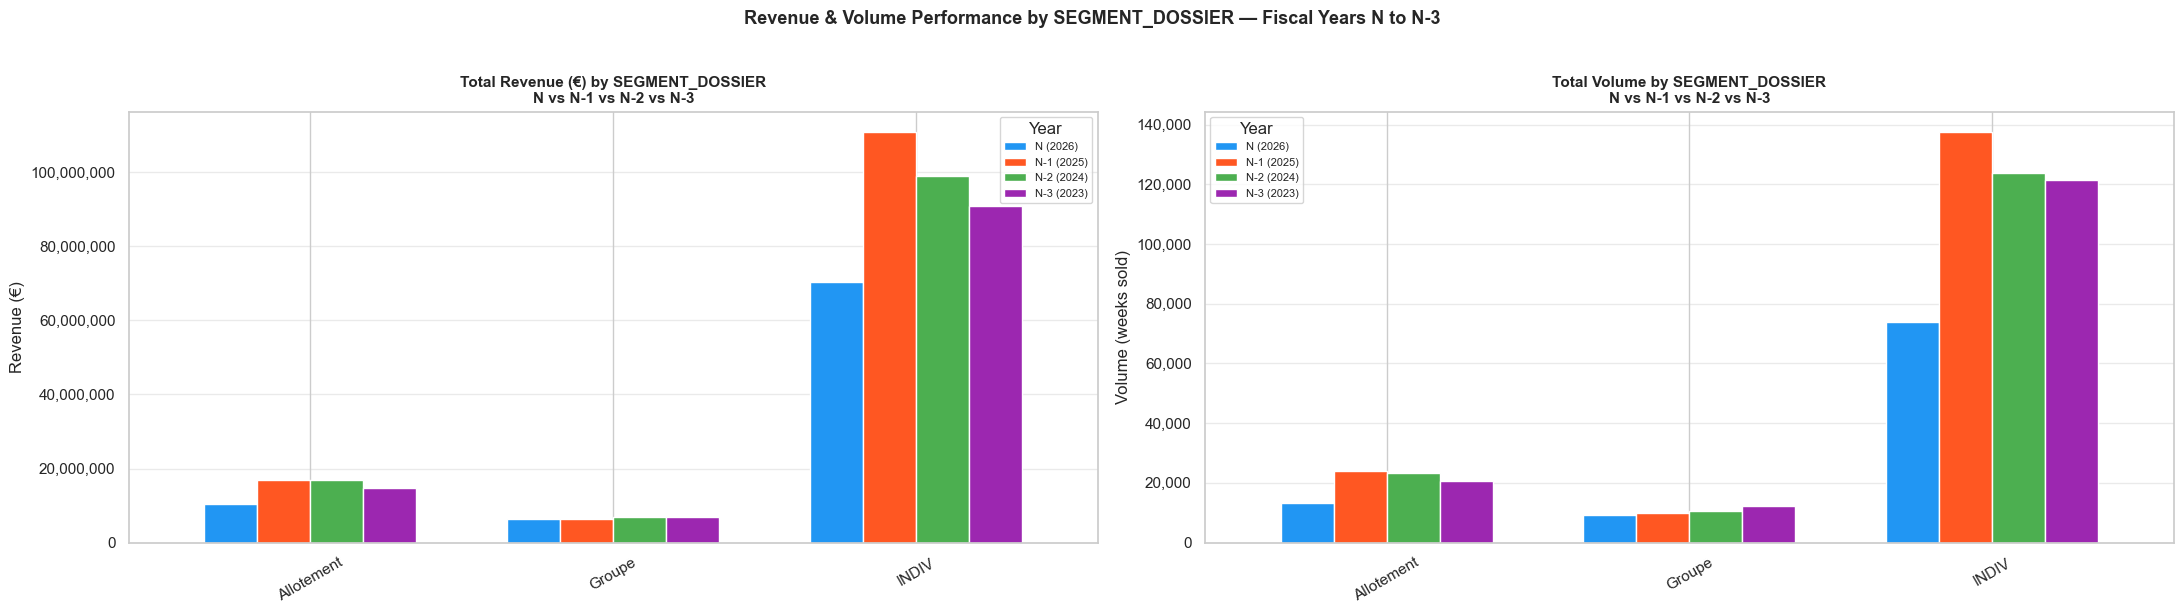

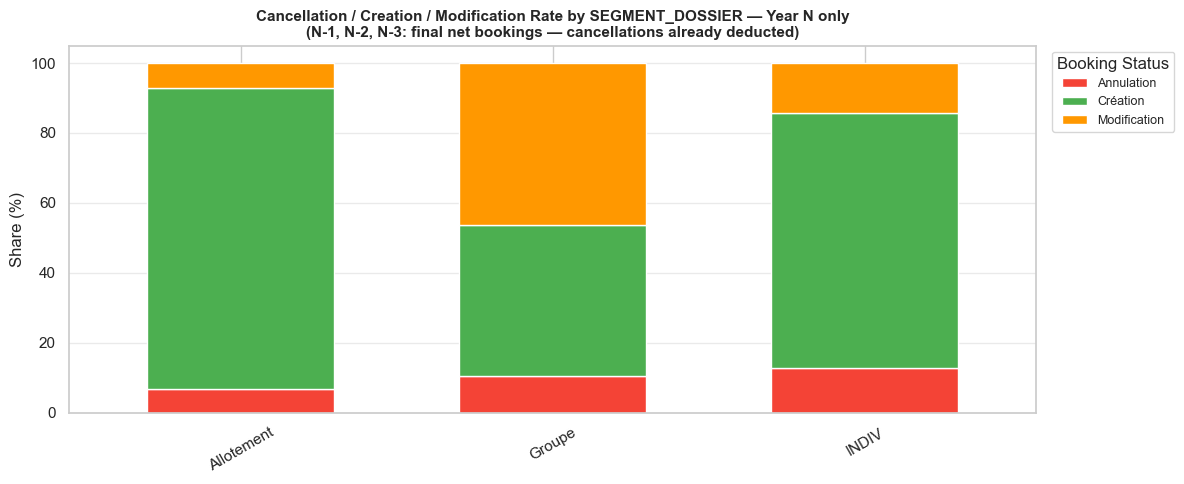

--------------------------------------------------------------------------------


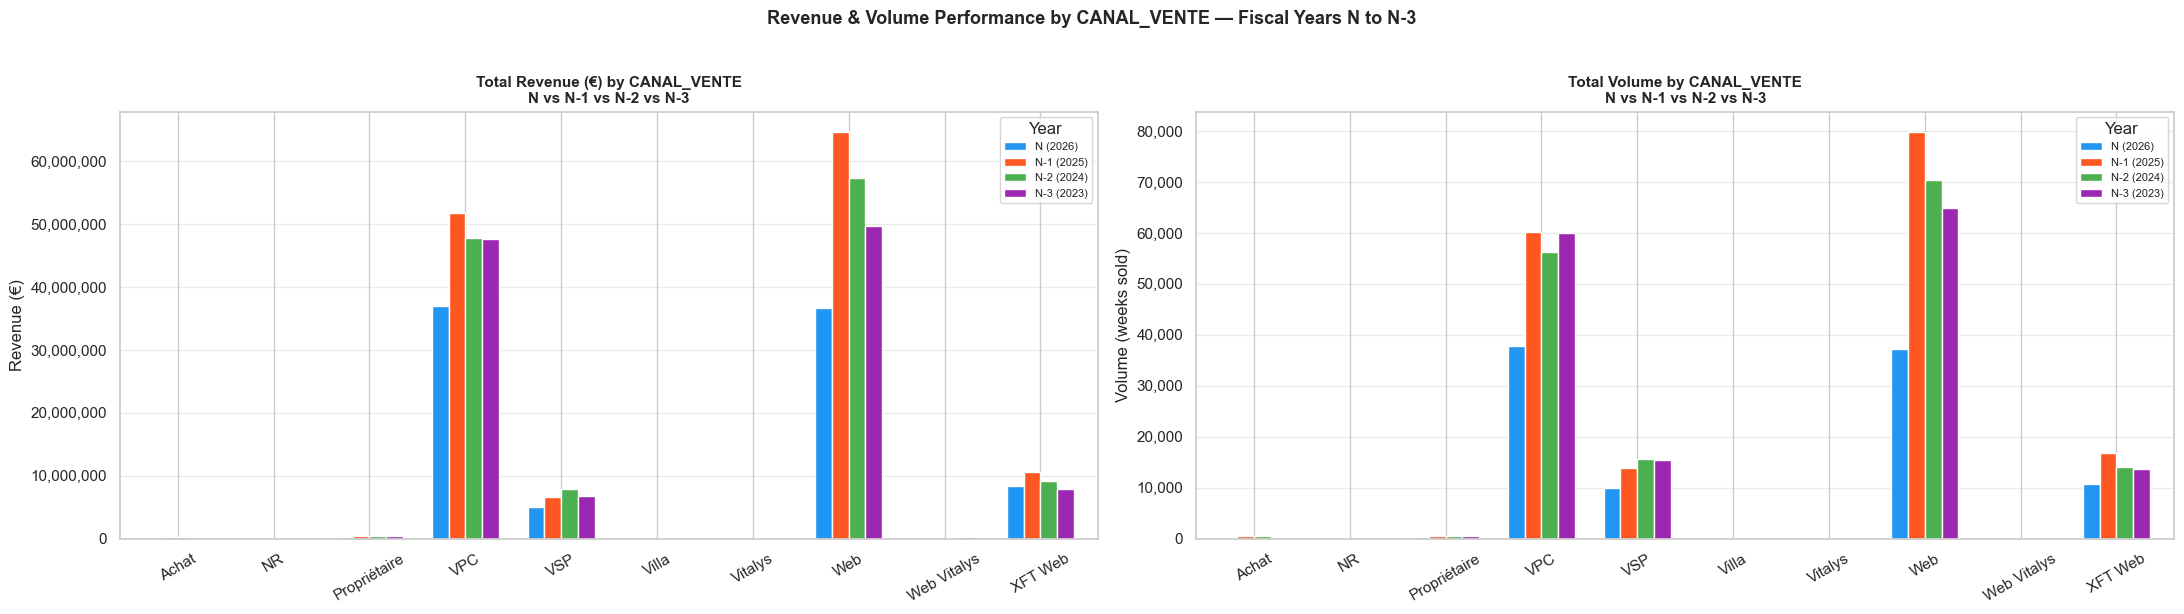

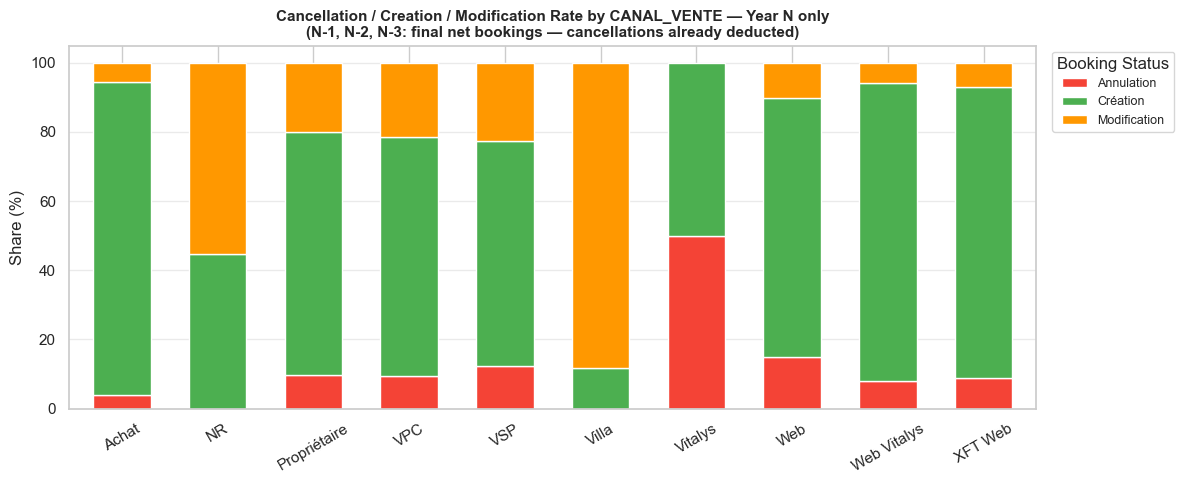

--------------------------------------------------------------------------------


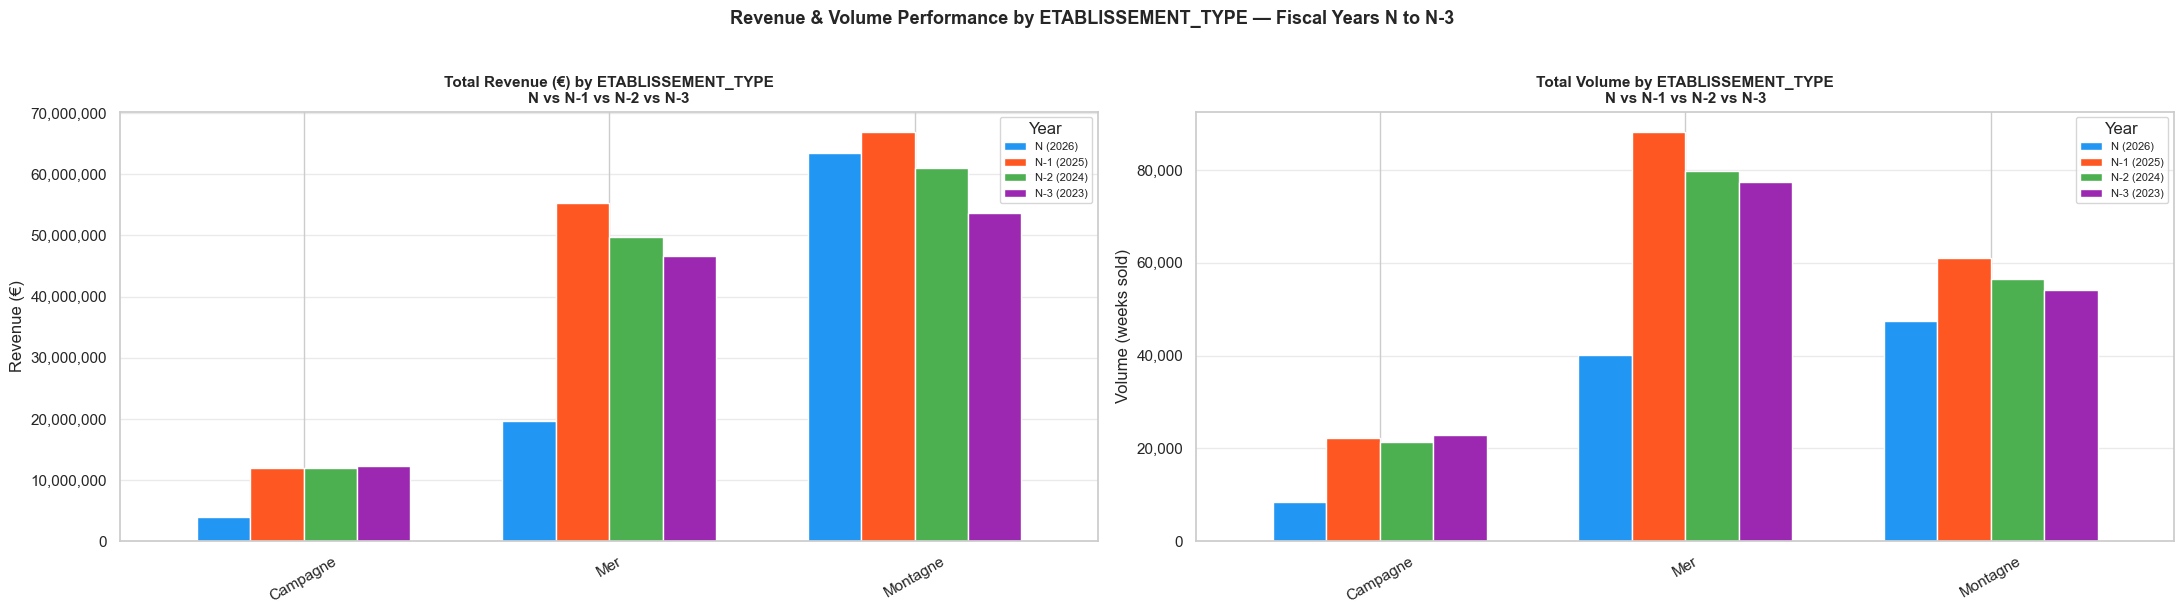

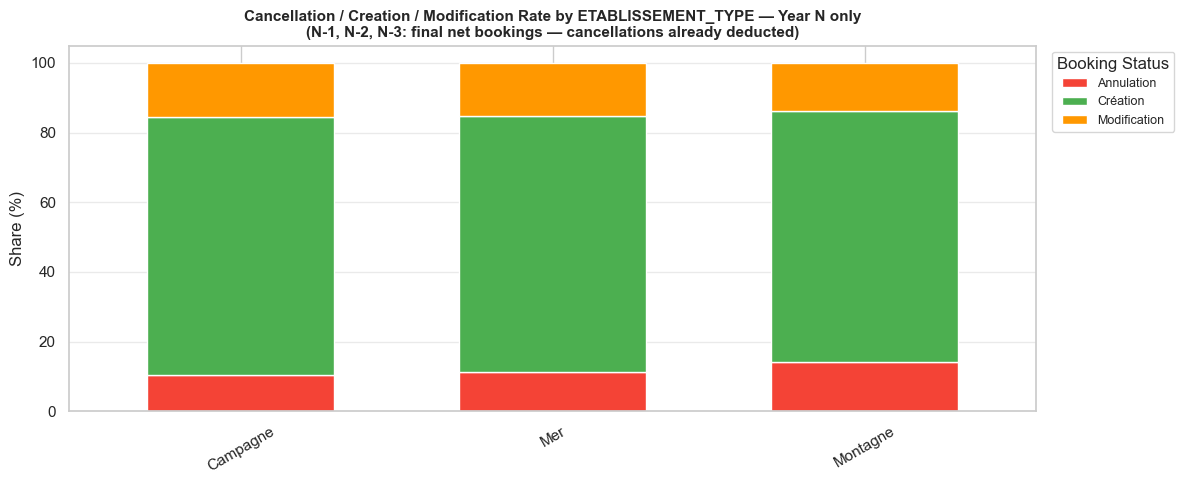

--------------------------------------------------------------------------------


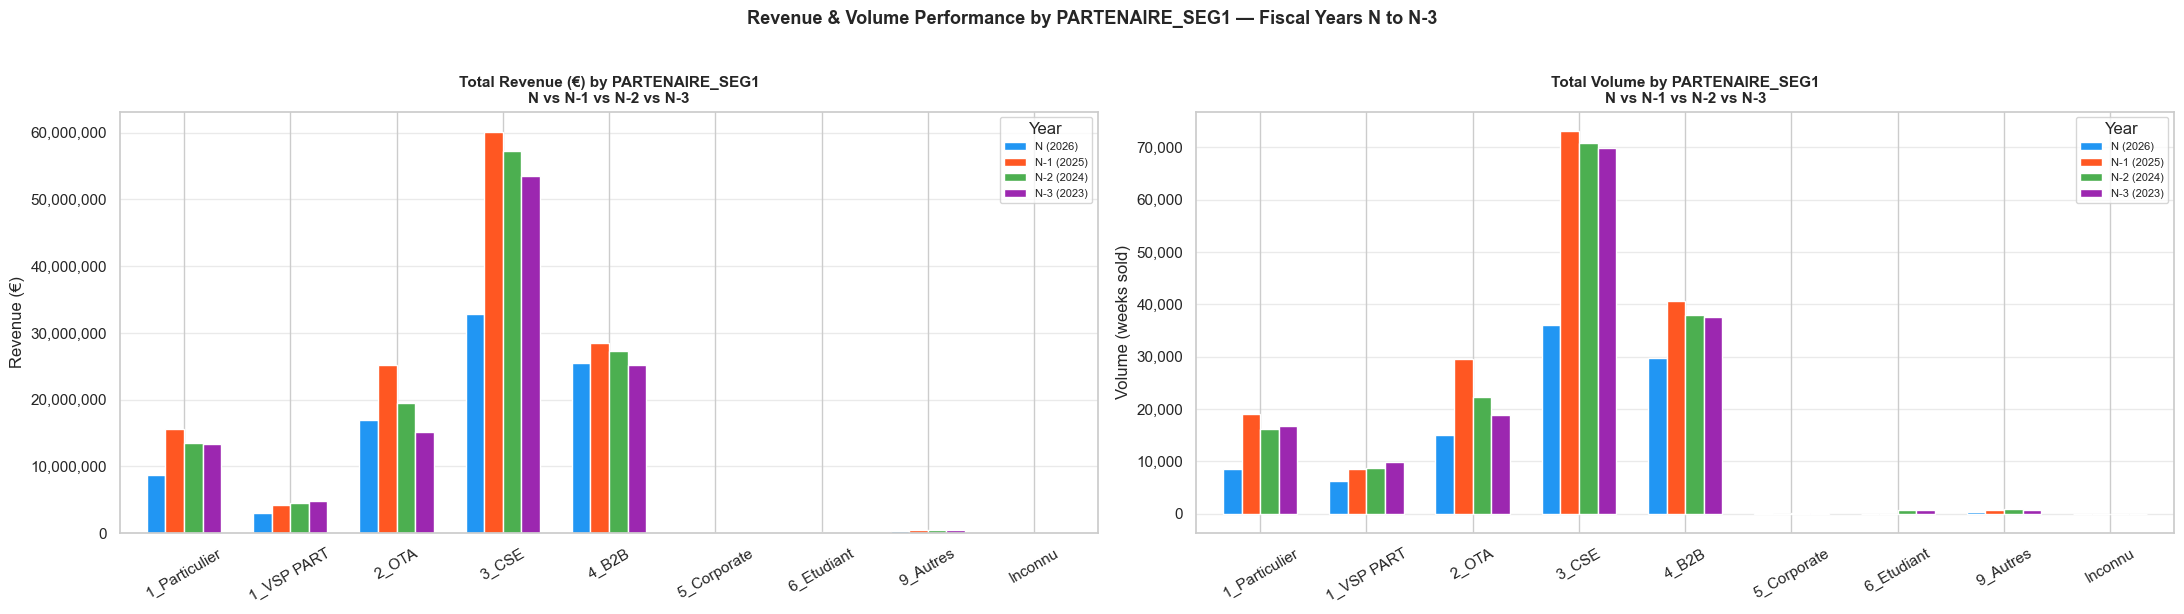

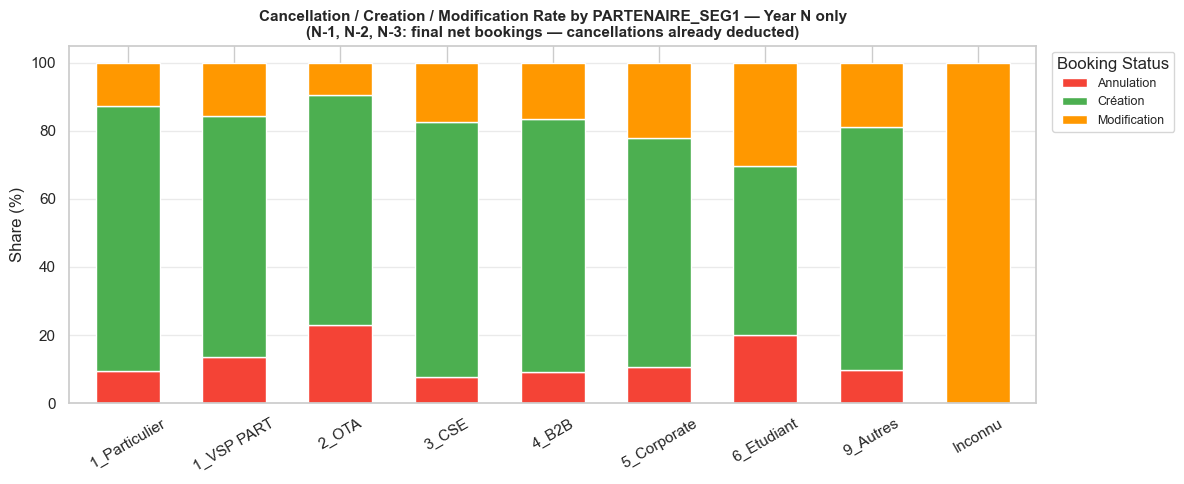

--------------------------------------------------------------------------------


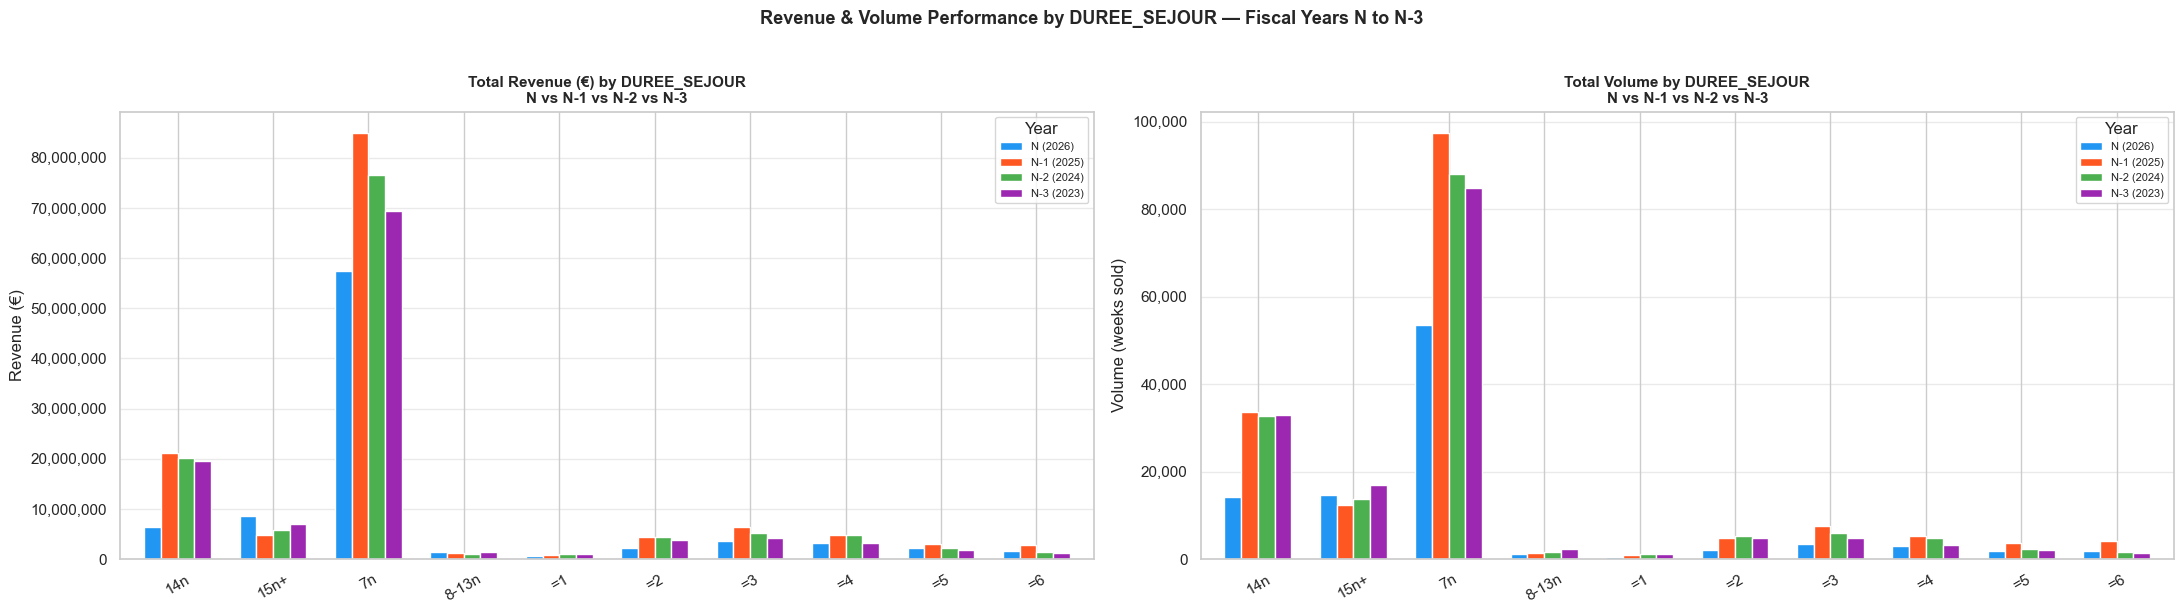

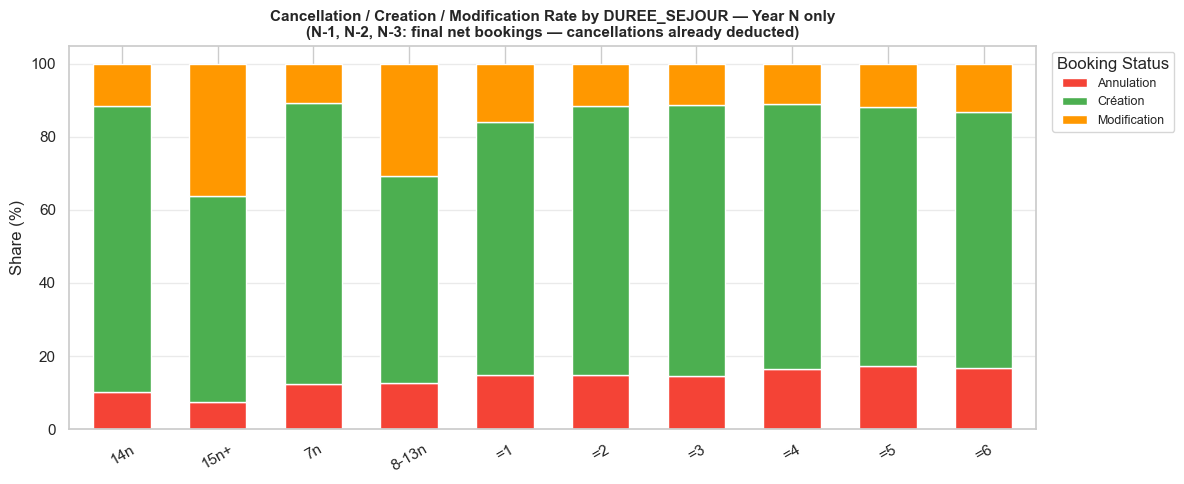

--------------------------------------------------------------------------------


In [32]:
# ============================================================
# CA, Volume & Annulation Rate — N vs N-1 vs N-2 vs N-3
# By key categorical variables
# ============================================================

cat_to_cross = ['SEGMENT_DOSSIER', 'CANAL_VENTE', 'ETABLISSEMENT_TYPE', 'PARTENAIRE_SEG1','DUREE_SEJOUR']

""" 
ca_cols  = ['CA_N', 'CA_N1FDS', 'CA_N2FDS', 'CA_N3FDS']
vol_cols = ['VOLUME_N', 'VOLUME_N1FDS', 'VOLUME_N2FDS', 'VOLUME_N3FDS']
year_labels = ['N (2026)', 'N-1 (2025)', 'N-2 (2024)', 'N-3 (2023)'] 
"""

# Palettes explicites — visibles sur fond blanc
COLORS_YEAR  = ['#2196F3', '#FF5722', '#4CAF50', '#9C27B0']  # bleu, orange, vert, violet
COLORS_STATE = ['#F44336', '#4CAF50', '#FF9800', '#9E9E9E']  # rouge, vert, orange, gris

for col in cat_to_cross:

    fig, axes = plt.subplots(1, 2, figsize=(22, 6))

    # --- 1. Total CA by year ---
    ca_agg = data.groupby(col, observed=True)[ca_cols].sum()
    ca_agg.columns = year_labels
    ca_agg.plot(kind='bar', ax=axes[0], color=COLORS_YEAR, edgecolor='white', width=0.7)
    axes[0].set_title(f'Total Revenue (€) by {col}\nN vs N-1 vs N-2 vs N-3', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('')
    axes[0].set_ylabel('Revenue (€)')
    axes[0].tick_params(axis='x', rotation=30)
    axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
    axes[0].legend(title='Year', fontsize=8)
    axes[0].grid(axis='y', alpha=0.4)

    # --- 2. Total Volume by year ---
    vol_agg = data.groupby(col, observed=True)[vol_cols].sum()
    vol_agg.columns = year_labels
    vol_agg.plot(kind='bar', ax=axes[1], color=COLORS_YEAR, edgecolor='white', width=0.7)
    axes[1].set_title(f'Total Volume by {col}\nN vs N-1 vs N-2 vs N-3', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('')
    axes[1].set_ylabel('Volume (weeks sold)')
    axes[1].tick_params(axis='x', rotation=30)
    axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
    axes[1].legend(title='Year', fontsize=8)
    axes[1].grid(axis='y', alpha=0.4)

    plt.suptitle(
        f'Revenue & Volume Performance by {col} — Fiscal Years N to N-3',
        fontsize=13, fontweight='bold', y=1.02
    )
    plt.tight_layout()
    plt.show()

    # --- Annulation rate for N only ---
    if 'ETAT_DOSSIER' in data.columns:
        ann = data.groupby([col, 'ETAT_DOSSIER'], observed=True).size().unstack(fill_value=0)
        ann_rate = ann.div(ann.sum(axis=1), axis=0) * 100

        fig2, ax2 = plt.subplots(figsize=(12, 5))
        ann_rate.plot(kind='bar', stacked=True, ax=ax2,
                      color=COLORS_STATE[:len(ann_rate.columns)],
                      edgecolor='white', width=0.6)
        ax2.set_title(
            f'Cancellation / Creation / Modification Rate by {col} — Year N only\n'
            f'(N-1, N-2, N-3: final net bookings — cancellations already deducted)',
            fontsize=11, fontweight='bold'
        )
        ax2.set_xlabel('')
        ax2.set_ylabel('Share (%)')
        ax2.tick_params(axis='x', rotation=30)
        ax2.legend(title='Booking Status', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
        ax2.grid(axis='y', alpha=0.4)
        plt.tight_layout()
        plt.show()

    print('-' * 80)

### 3.3 Distribution temporelle — Semaines de séjour

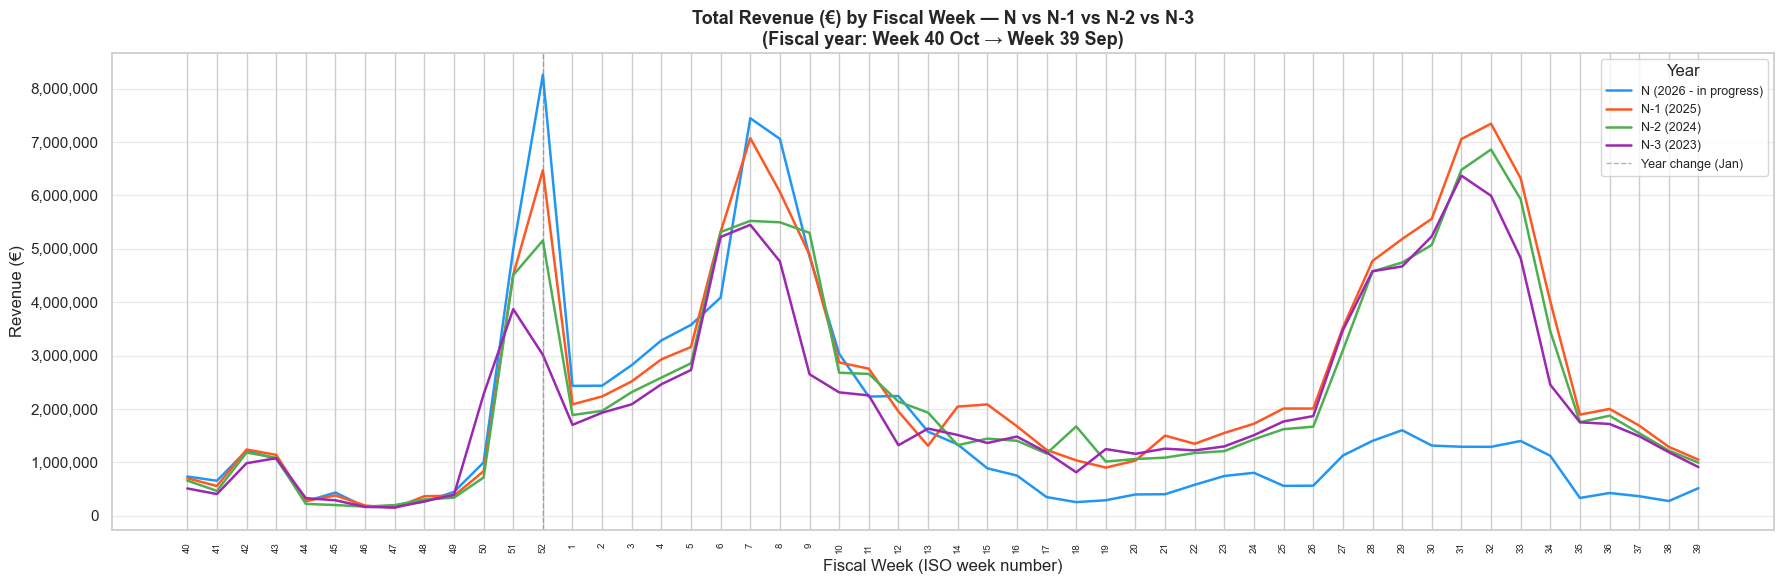

In [33]:
ca_cols_fds = ['CA_N', 'CA_N1FDS', 'CA_N2FDS', 'CA_N3FDS']
year_labels_fds = ['N (2026 - in progress)', 'N-1 (2025)', 'N-2 (2024)', 'N-3 (2023)']
COLORS_YEAR = ['#2196F3', '#FF5722', '#4CAF50', '#9C27B0']

weekly_ca = data.groupby('SEMAINE_SEJOUR')[ca_cols_fds].sum().reset_index()
weekly_ca['SEMAINE_NUM'] = weekly_ca['SEMAINE_SEJOUR'].dt.isocalendar().week.astype(int)
weekly_ca = weekly_ca.groupby('SEMAINE_NUM')[ca_cols_fds].sum().reset_index()
weekly_ca.columns = ['SEMAINE_NUM'] + year_labels_fds

# Réordonner : semaine 40 → 52 puis 1 → 39 (ordre exercice fiscal Oct → Sep)
fiscal_order = list(range(40, 53)) + list(range(1, 40))
weekly_ca['FISCAL_ORDER'] = weekly_ca['SEMAINE_NUM'].map({w: i for i, w in enumerate(fiscal_order)})
weekly_ca = weekly_ca.sort_values('FISCAL_ORDER')

plt.figure(figsize=(18, 6))

for label, color in zip(year_labels_fds, COLORS_YEAR):
    plt.plot(range(len(weekly_ca)), weekly_ca[label],
             color=color, linewidth=1.8, label=label)

# Axe X avec labels semaines
plt.xticks(
    ticks=range(len(weekly_ca)),
    labels=weekly_ca['SEMAINE_NUM'].astype(str),
    rotation=90, fontsize=7
)

# Séparateur visuel semaine 52 → semaine 1 (changement d'année civile)
sep_idx = fiscal_order.index(52)
plt.axvline(x=sep_idx, color='grey', linestyle='--', linewidth=1, alpha=0.6, label='Year change (Jan)')

plt.title('Total Revenue (€) by Fiscal Week — N vs N-1 vs N-2 vs N-3\n'
          '(Fiscal year: Week 40 Oct → Week 39 Sep)', fontsize=13, fontweight='bold')
plt.xlabel('Fiscal Week (ISO week number)')
plt.ylabel('Revenue (€)')
plt.legend(title='Year', fontsize=9)
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

---
## 4. Analyse Bivariée

### 4.1 CA & Volume par segment

In [34]:
seg_stats = data.groupby('SEGMENT_DOSSIER', observed=True).agg(
    CA_total=('CA_N', 'sum'),
    Volume_total=('VOLUME_N', 'sum'),
).reset_index()
seg_stats['PMV'] = seg_stats['CA_total'] / seg_stats['Volume_total'].replace(0, np.nan)

display(seg_stats)


,SEGMENT_DOSSIER,CA_total,Volume_total,PMV
0,Allotement,10295539.23,13157.59,782.48
1,Groupe,6470750.20,9120.71,709.46
2,INDIV,70406842.63,73783.95,954.23


### 4.2 CA & Volume par type d'établissement et saison

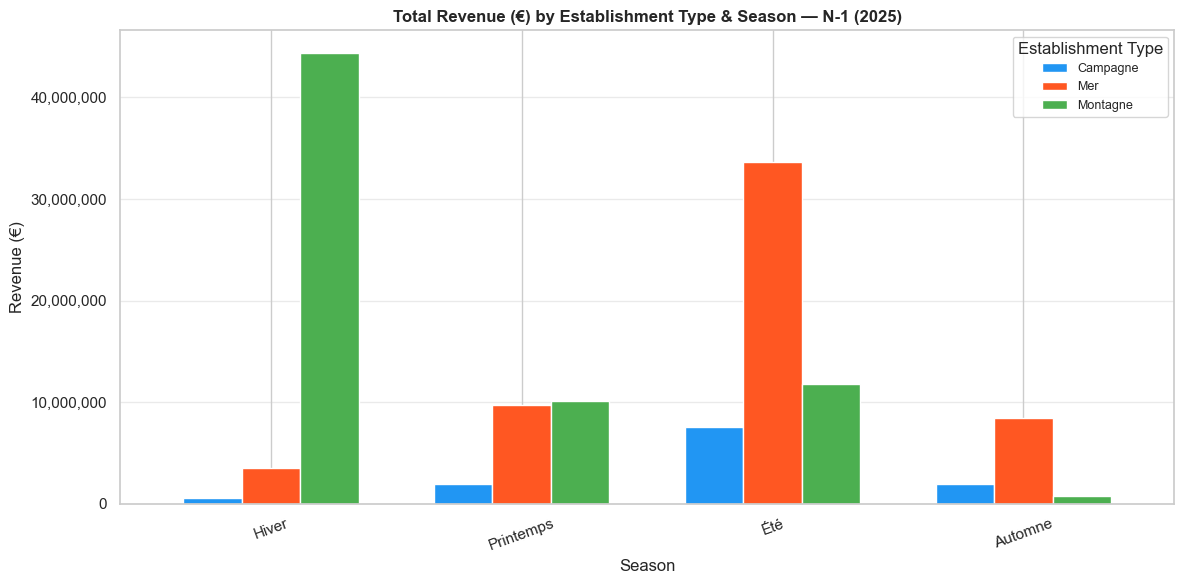

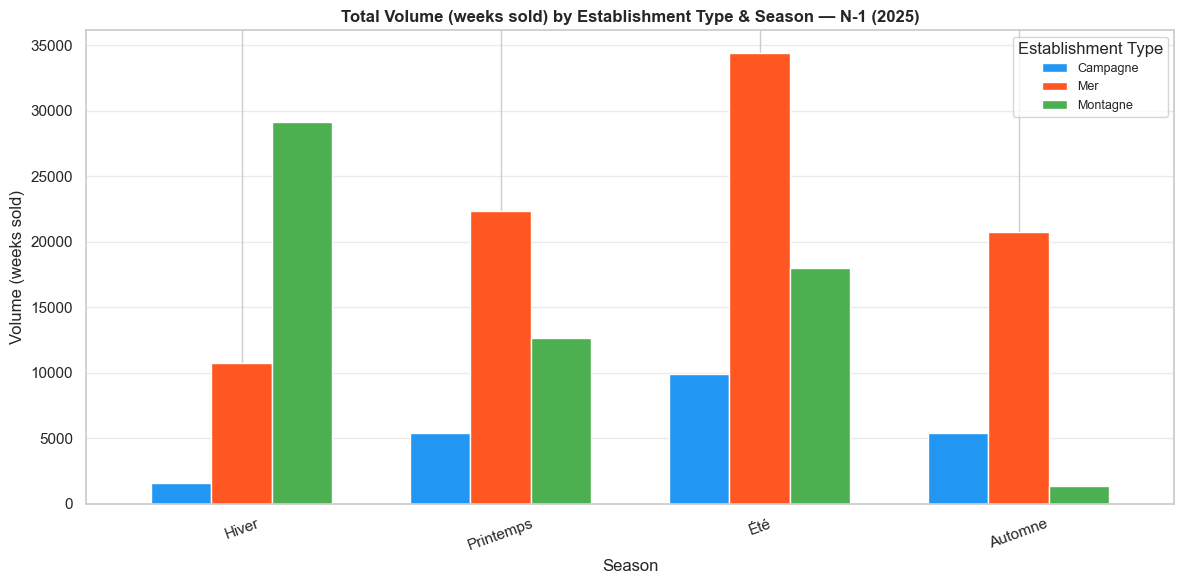

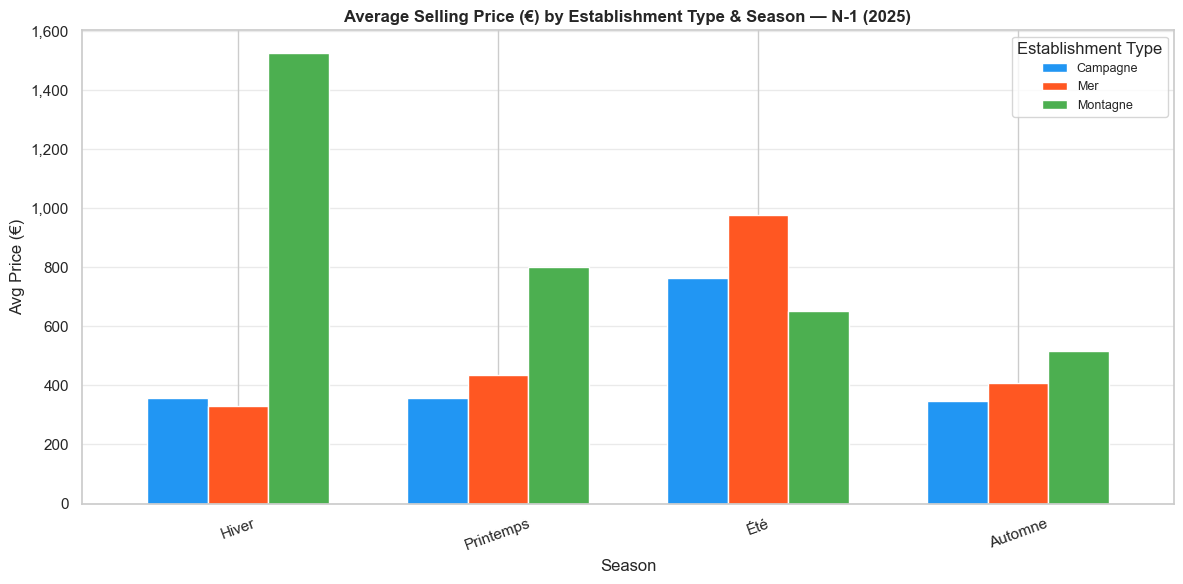

In [35]:

# Création d'une variable saison approximative
data['MOIS_SEJOUR'] = data['SEMAINE_SEJOUR'].dt.month
data['SAISON'] = data['MOIS_SEJOUR'].map({
    9: 'Automne', 10: 'Automne', 11: 'Automne', 
    12: 'Hiver', 1: 'Hiver', 2: 'Hiver', 
    3: 'Printemps', 4: 'Printemps', 5: 'Printemps',
    6: 'Été', 7: 'Été', 8: 'Été'
})

type_saison = data.groupby(['ETABLISSEMENT_TYPE', 'SAISON'], observed=True).agg(
    CA=('CA_N1FDS', 'sum'),
    Volume=('VOLUME_N1FDS', 'sum')
).reset_index()
type_saison['PMV'] = type_saison['CA'] / type_saison['Volume'].replace(0, np.nan)

COLORS_TYPE = ['#2196F3', '#FF5722', '#4CAF50']
saison_order = ['Hiver', 'Printemps', 'Été', 'Automne']

for metric, label, ylabel in [
    ('CA',     'Total Revenue (€) by Establishment Type & Season — N-1 (2025)',      'Revenue (€)'),
    ('Volume', 'Total Volume (weeks sold) by Establishment Type & Season — N-1 (2025)', 'Volume (weeks sold)'),
    ('PMV',    'Average Selling Price (€) by Establishment Type & Season — N-1 (2025)', 'Avg Price (€)')
]:
    pivot = type_saison.pivot(index='SAISON', columns='ETABLISSEMENT_TYPE', values=metric)
    pivot = pivot.reindex(saison_order)

    fig, ax = plt.subplots(figsize=(12, 6))
    pivot.plot(kind='bar', ax=ax, color=COLORS_TYPE, edgecolor='white', width=0.7)
    ax.set_title(label, fontsize=12, fontweight='bold')
    ax.set_xlabel('Season')
    ax.set_ylabel(ylabel)
    ax.tick_params(axis='x', rotation=20)
    ax.legend(title='Establishment Type', fontsize=9)
    ax.grid(axis='y', alpha=0.4)
    if metric in ['CA', 'PMV']:
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
    plt.tight_layout()
    plt.show()

# Saison binaire (Hiver = Oct-Mars, Ete = Avr-Sep) — pour analyses N vs historique
data['SAISON_SEJOUR'] = np.where(data['MOIS_SEJOUR'].isin([10, 11, 12, 1, 2, 3]), 'Hiver', 'Ete')


### 4.5 Top établissements par CA

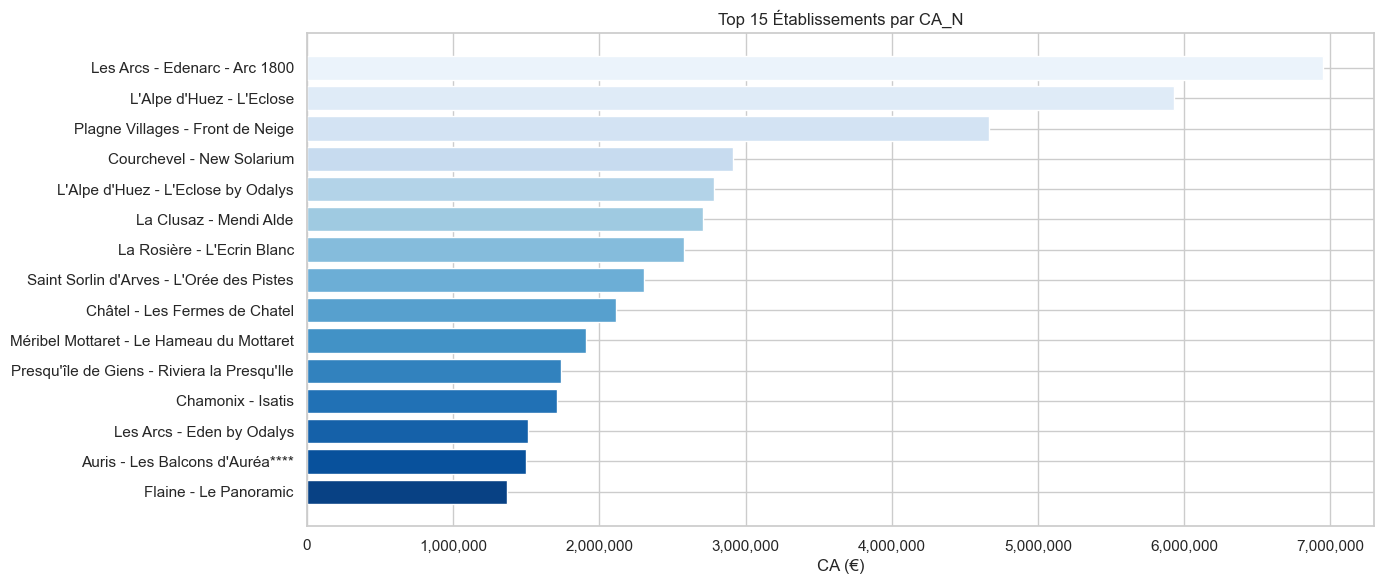

In [36]:
top_etab = data.groupby('ETABLISSEMENT_NOM', observed=True)['CA_N'].sum()\
               .sort_values(ascending=False).head(15).reset_index()

plt.figure(figsize=(14, 6))
plt.barh(top_etab['ETABLISSEMENT_NOM'][::-1], top_etab['CA_N'][::-1],
         color=sns.color_palette('Blues_r', 15))
plt.title('Top 15 Établissements par CA_N', fontsize=12)
plt.xlabel('CA (€)')
plt.gca().xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()

---
## 5. Analyse Avancée

### 5.1 Construction de la table agrégée de référence

> **Justification** — *Transcript métier & Bandalouski et al. (2018)* : La granularité retenue est **Établissement × Semaine de séjour**. On utilise les valeurs **FDS (Fin de Saison)** pour N-1, N-2, N-3 (historique complet), et les valeurs **à date** pour N uniquement (saison en cours). Le stock est une valeur fixe par résidence, non à prédire.

In [37]:
# Table agrégée par Établissement × Semaine de séjour
agg_dict = {
    'CA_N': 'sum',
    'CA_N1FDS': 'sum',
    'CA_N2FDS': 'sum',
    'CA_N3FDS': 'sum',
    'VOLUME_N': 'sum',
    'VOLUME_N1FDS': 'sum',
    'VOLUME_N2FDS': 'sum',
    'VOLUME_N3FDS': 'sum',
}

df_agg = data.groupby(
    ['SEMAINE_SEJOUR'],
    observed=True
).agg(agg_dict).reset_index()

print(f'Table agrégée : {df_agg.shape}')
df_agg.head(5)

Table agrégée : (53, 9)


,SEMAINE_SEJOUR,CA_N,CA_N1FDS,CA_N2FDS,CA_N3FDS,VOLUME_N,VOLUME_N1FDS,VOLUME_N2FDS,VOLUME_N3FDS
0,2025-09-27,396335.06,410272.30,351475.95,277580.11,1092.29,1149.57,1076.29,892.29
1,2025-10-04,734508.10,702968.49,659122.40,511510.30,2171.29,2054.00,1978.43,1688.57
2,2025-10-11,655578.10,557004.52,465550.48,406535.35,1924.00,1676.29,1359.71,1331.43
3,2025-10-18,1219764.61,1240555.21,1183616.20,984459.84,2920.71,3089.43,2911.14,2645.29
4,2025-10-25,1066390.43,1140727.14,1086785.68,1078071.96,2583.71,2890.57,2799.43,2741.57


In [38]:
# Table agrégée par Établissement × Semaine de séjour
agg_dict = {
    'CA_N': 'sum',
    'CA_N1FDS': 'sum',
    'CA_N2FDS': 'sum',
    'CA_N3FDS': 'sum',
    'VOLUME_N': 'sum',
    'VOLUME_N1FDS': 'sum',
    'VOLUME_N2FDS': 'sum',
    'VOLUME_N3FDS': 'sum',
    'ETABLISSEMENT_TYPE': 'first',
    'ETABLISSEMENT_LOCALISATION': 'first'
}

df_agg = data.groupby(
    ['ID_ETABLISSEMENT', 'ETABLISSEMENT_NOM', 'SEMAINE_SEJOUR'],
    observed=True
).agg(agg_dict).reset_index()

print(f'Table agrégée : {df_agg.shape}')
df_agg.head(5)

Table agrégée : (3988, 13)


,ID_ETABLISSEMENT,ETABLISSEMENT_NOM,SEMAINE_SEJOUR,CA_N,CA_N1FDS,CA_N2FDS,CA_N3FDS,VOLUME_N,VOLUME_N1FDS,VOLUME_N2FDS,VOLUME_N3FDS,ETABLISSEMENT_TYPE,ETABLISSEMENT_LOCALISATION
0,1,Cap d'Agde - Saint Loup,2025-09-27,9232.99,9862.01,10947.13,11449.59,26.57,44.86,50.43,44.00,Mer,Languedoc Roussillon
1,1,Cap d'Agde - Saint Loup,2025-10-04,14440.65,12857.60,17387.71,18403.19,44.14,73.29,85.29,76.00,Mer,Languedoc Roussillon
2,1,Cap d'Agde - Saint Loup,2025-10-11,11332.16,11331.80,9593.98,16658.55,34.14,54.57,53.57,80.43,Mer,Languedoc Roussillon
3,1,Cap d'Agde - Saint Loup,2025-10-18,92296.90,80039.63,144696.91,59470.07,183.00,191.00,266.00,188.00,Mer,Languedoc Roussillon
4,1,Cap d'Agde - Saint Loup,2025-10-25,23728.64,24706.20,25405.47,33663.95,63.14,84.29,93.86,119.86,Mer,Languedoc Roussillon


### 5.2 Analyse du Pickup (montée en charge)

> **Justification** — *Transcript métier & Ampountolas & Legg (2025)* : La `DATE_OBSERVATION` est l'axe temporel central du pickup. Pour chaque semaine de séjour, on reconstitue l'évolution du CA cumulé au fur et à mesure que les réservations arrivent. Cette courbe de pickup est fondamentale pour décider **quand** déclencher le pricing dynamique.

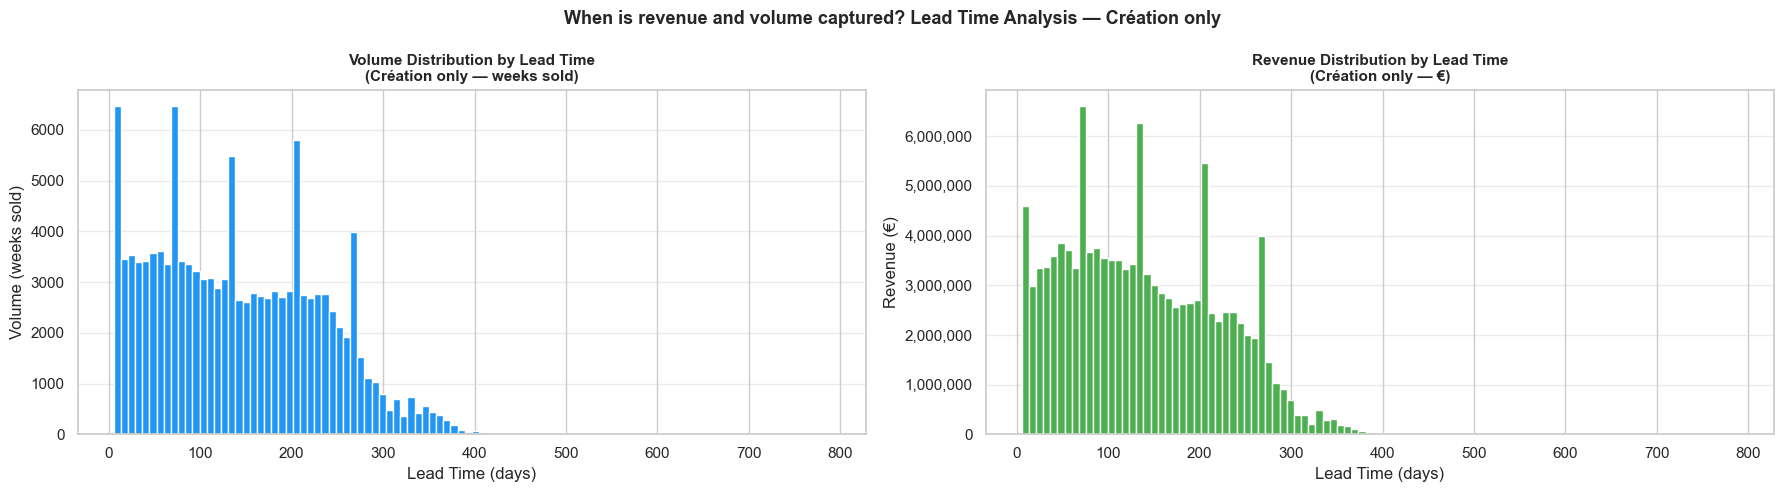

In [39]:
# Calcul de la booking window (lead time en jours)
data['LEAD_TIME_JOURS'] = (data['SEMAINE_SEJOUR'] - data['DATE_OBSERVATION']).dt.days
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

"""     (data['LEAD_TIME_JOURS'] >= 0) &
    (data['LEAD_TIME_JOURS'] <= 365) """
lead_filtre = data[
    (data['ETAT_DOSSIER'] == 'Création') 
].copy()

# --- Volume (semaines vendues) ---
axes[0].hist(
    lead_filtre['LEAD_TIME_JOURS'],
    bins=100, 
    weights=lead_filtre['VOLUME_N'],
    color='#2196F3', edgecolor='white'
)
axes[0].set_title('Volume Distribution by Lead Time\n(Création only — weeks sold)',
                  fontsize=11, fontweight='bold')
axes[0].set_xlabel('Lead Time (days)')
axes[0].set_ylabel('Volume (weeks sold)')
axes[0].grid(axis='y', alpha=0.4)

# --- CA ---
axes[1].hist(
    lead_filtre['LEAD_TIME_JOURS'],
    bins=100,
    weights=lead_filtre['CA_N'],
    color='#4CAF50', edgecolor='white'
)
axes[1].set_title('Revenue Distribution by Lead Time\n(Création only — €)',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('Lead Time (days)')
axes[1].set_ylabel('Revenue (€)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[1].grid(axis='y', alpha=0.4)

plt.suptitle('When is revenue and volume captured? Lead Time Analysis — Création only',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


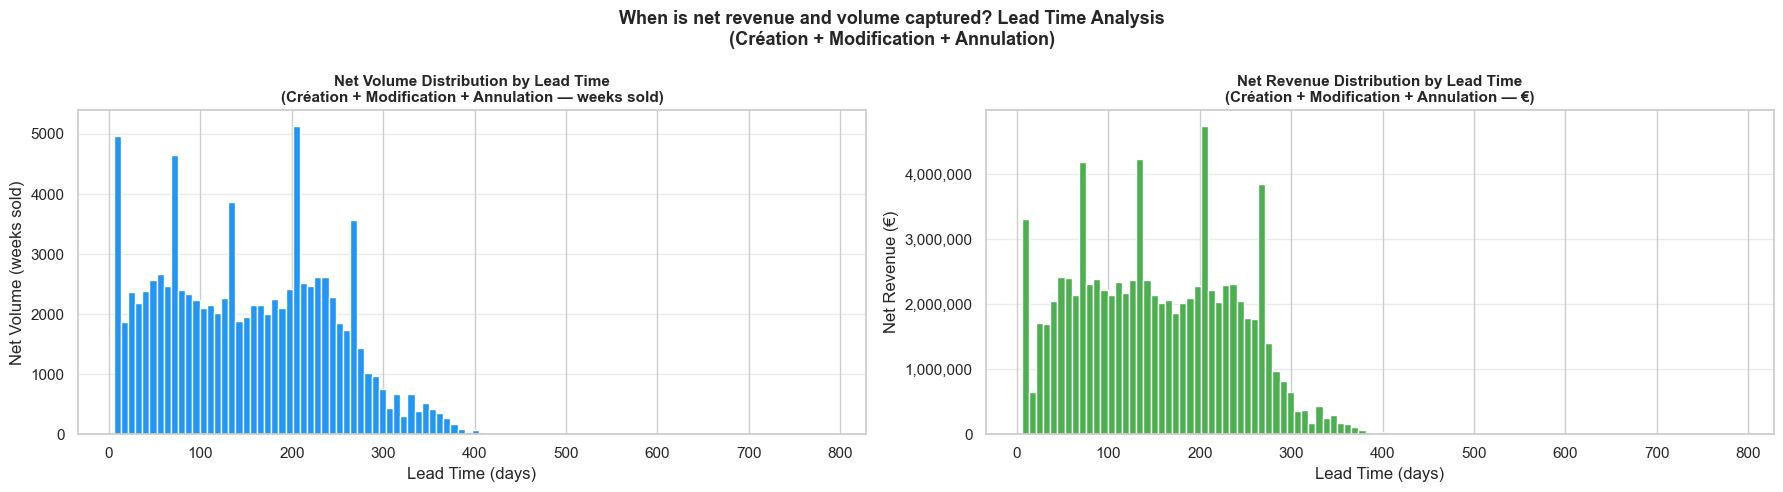

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

lead_filtre = data.copy()

# --- Volume net : Création + Modification + Annulation ---
axes[0].hist(
    lead_filtre['LEAD_TIME_JOURS'],
    bins=100,
    weights=lead_filtre['VOLUME_N'],
    color='#2196F3', edgecolor='white'
)
axes[0].set_title('Net Volume Distribution by Lead Time\n(Création + Modification + Annulation — weeks sold)',
                  fontsize=11, fontweight='bold')
axes[0].set_xlabel('Lead Time (days)')
axes[0].set_ylabel('Net Volume (weeks sold)')
axes[0].grid(axis='y', alpha=0.4)

# --- CA net : Création + Modification + Annulation ---
axes[1].hist(
    lead_filtre['LEAD_TIME_JOURS'],
    bins=100,
    weights=lead_filtre['CA_N'],
    color='#4CAF50', edgecolor='white'
)
axes[1].set_title('Net Revenue Distribution by Lead Time\n(Création + Modification + Annulation — €)',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('Lead Time (days)')
axes[1].set_ylabel('Net Revenue (€)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[1].grid(axis='y', alpha=0.4)

plt.suptitle('When is net revenue and volume captured? Lead Time Analysis\n(Création + Modification + Annulation)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

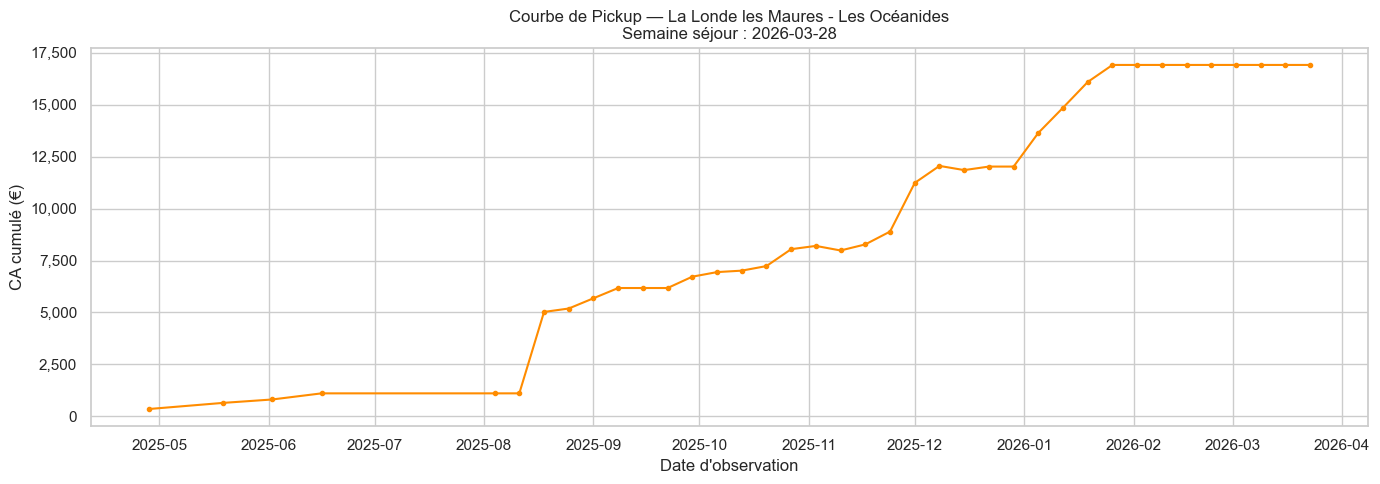

In [41]:
# Exemple de courbe de pickup pour un établissement et une semaine donnée
# ⚠️ Adapter l'établissement et la semaine selon les données
etab_exemple = data['ETABLISSEMENT_NOM'].value_counts().index[0]  # Top établissement
semaines_dispo = data[data['ETABLISSEMENT_NOM'] == etab_exemple]['SEMAINE_SEJOUR'].unique()

if len(semaines_dispo) > 0:
    semaine_exemple = sorted(semaines_dispo)[len(semaines_dispo)//2]  # semaine médiane

    pickup_df = data[
        (data['ETABLISSEMENT_NOM'] == etab_exemple) &
        (data['SEMAINE_SEJOUR'] == semaine_exemple)
    ].groupby('DATE_OBSERVATION')['CA_N'].sum().cumsum().reset_index()

    plt.figure(figsize=(14, 5))
    plt.plot(pickup_df['DATE_OBSERVATION'], pickup_df['CA_N'], marker='o', markersize=3, color='darkorange')
    plt.title(f'Courbe de Pickup — {etab_exemple}\nSemaine séjour : {semaine_exemple.date()}', fontsize=12)
    plt.xlabel('Date d\'observation')
    plt.ylabel('CA cumulé (€)')
    plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
    plt.tight_layout()
    plt.show()

In [42]:
data['LEAD_TIME_JOURS'].describe()

count   1003364.00
mean         87.13
std          75.97
min           5.00
25%          26.00
50%          68.00
75%         131.00
max         789.00
Name: LEAD_TIME_JOURS, dtype: float64

### 5.3 Booking Windows — Catégorisation du lead time

> **Justification — Transcript métier** : Le regroupement du lead time en fenêtres de réservation (booking windows) permet de savoir **à quelle période de la courbe de montée en charge** on se situe, et donc **quand agir** sur le prix. Les catégories sont définies en cohérence avec les pratiques du Revenue Management hôtelier.

In [43]:
bins   = [0, 7, 21, 60, 120, 180, 365, 789]
labels = ['0-7j', '8-21j', '22-60j', '61-120j', '121-180j', '181-365j','365+']

data['BOOKING_WINDOW'] = pd.cut(data['LEAD_TIME_JOURS'], bins=bins, labels=labels)

pickup_table = data.groupby(
    ['ID_ETABLISSEMENT', 'ETABLISSEMENT_NOM', 'SEMAINE_SEJOUR', 'BOOKING_WINDOW'],
    observed=True
).agg(
    CA_PICKUP=('CA_N', 'sum'),
    VOLUME_PICKUP=('VOLUME_N', 'sum')
).reset_index()

# Pivot pour avoir une colonne par booking window
pickup_pivot = pickup_table.pivot_table(
    index=['ID_ETABLISSEMENT', 'ETABLISSEMENT_NOM', 'SEMAINE_SEJOUR'],
    columns='BOOKING_WINDOW',
    values=['CA_PICKUP', 'VOLUME_PICKUP'],
    fill_value=0
).reset_index()

print(f'Shape table pickup : {pickup_pivot.shape}')

Shape table pickup : (3988, 17)


In [44]:
pickup_pivot.head(50)

ID_ETABLISSEMENT        ETABLISSEMENT_NOM SEMAINE_SEJOUR  \
BOOKING_WINDOW                                                            
0                             1  Cap d'Agde - Saint Loup     2025-09-27   
1                             1  Cap d'Agde - Saint Loup     2025-10-04   
2                             1  Cap d'Agde - Saint Loup     2025-10-11   
3                             1  Cap d'Agde - Saint Loup     2025-10-18   
4                             1  Cap d'Agde - Saint Loup     2025-10-25   
5                             1  Cap d'Agde - Saint Loup     2025-11-01   
6                             1  Cap d'Agde - Saint Loup     2025-11-08   
7                             1  Cap d'Agde - Saint Loup     2025-11-15   
8                             1  Cap d'Agde - Saint Loup     2025-11-22   
9                             1  Cap d'Agde - Saint Loup     2025-11-29   
10                            1  Cap d'Agde - Saint Loup     2025-12-06   
11                            1  Cap d'Agde - Saint Loup     2025-12-13   
12                            1  Cap d'Agde - Saint Loup     2025-12-20   
13                            1  Cap d'Agde - Saint Loup     2025-12-27   
14                            1  Cap d'Agde - Saint Loup     2026-01-03   
15                            1  Cap d'Agde - Saint Loup     2026-01-10   
16                            1  Cap d'Agde - Saint Loup     2026-01-17   
17                            1  Cap d'Agde - Saint Loup     2026-01-24   
18                            1  Cap d'Agde - Saint Loup     2026-01-31   
19                            1  Cap d'Agde - Saint Loup     2026-02-07   
20                            1  Cap d'Agde - Saint Loup     2026-02-14   
21                            1  Cap d'Agde - Saint Loup     2026-02-21   
22                            1  Cap d'Agde - Saint Loup     2026-02-28   
23                            1  Cap d'Agde - Saint Loup     2026-03-07   
24                            1  Cap d'Agde - Saint Loup     2026-03-14   
25                            1  Cap d'Agde - Saint Loup     2026-03-21   
26                            1  Cap d'Agde - Saint Loup     2026-03-28   
27                            1  Cap d'Agde - Saint Loup     2026-04-04   
28                            1  Cap d'Agde - Saint Loup     2026-04-11   
29                            1  Cap d'Agde - Saint Loup     2026-04-18   
30                            1  Cap d'Agde - Saint Loup     2026-04-25   
31                            1  Cap d'Agde - Saint Loup     2026-05-02   
32                            1  Cap d'Agde - Saint Loup     2026-05-09   
33                            1  Cap d'Agde - Saint Loup     2026-05-16   
34                            1  Cap d'Agde - Saint Loup     2026-05-23   
35                            1  Cap d'Agde - Saint Loup     2026-05-30   
36                            1  Cap d'Agde - Saint Loup     2026-06-06   
37                            1  Cap d'Agde - Saint Loup     2026-06-13   
38                            1  Cap d'Agde - Saint Loup     2026-06-20   
39                            1  Cap d'Agde - Saint Loup     2026-06-27   
40                            1  Cap d'Agde - Saint Loup     2026-07-04   
41                            1  Cap d'Agde - Saint Loup     2026-07-11   
42                            1  Cap d'Agde - Saint Loup     2026-07-18   
43                            1  Cap d'Agde - Saint Loup     2026-07-25   
44                            1  Cap d'Agde - Saint Loup     2026-08-01   
45                            1  Cap d'Agde - Saint Loup     2026-08-08   
46                            1  Cap d'Agde - Saint Loup     2026-08-15   
47                            1  Cap d'Agde - Saint Loup     2026-08-22   
48                            1  Cap d'Agde - Saint Loup     2026-08-29   
49                            1  Cap d'Agde - Saint Loup     2026-09-05   

               CA_PICKUP                                                     \
BOOKING_WINDOW      0-7j   8-21j   

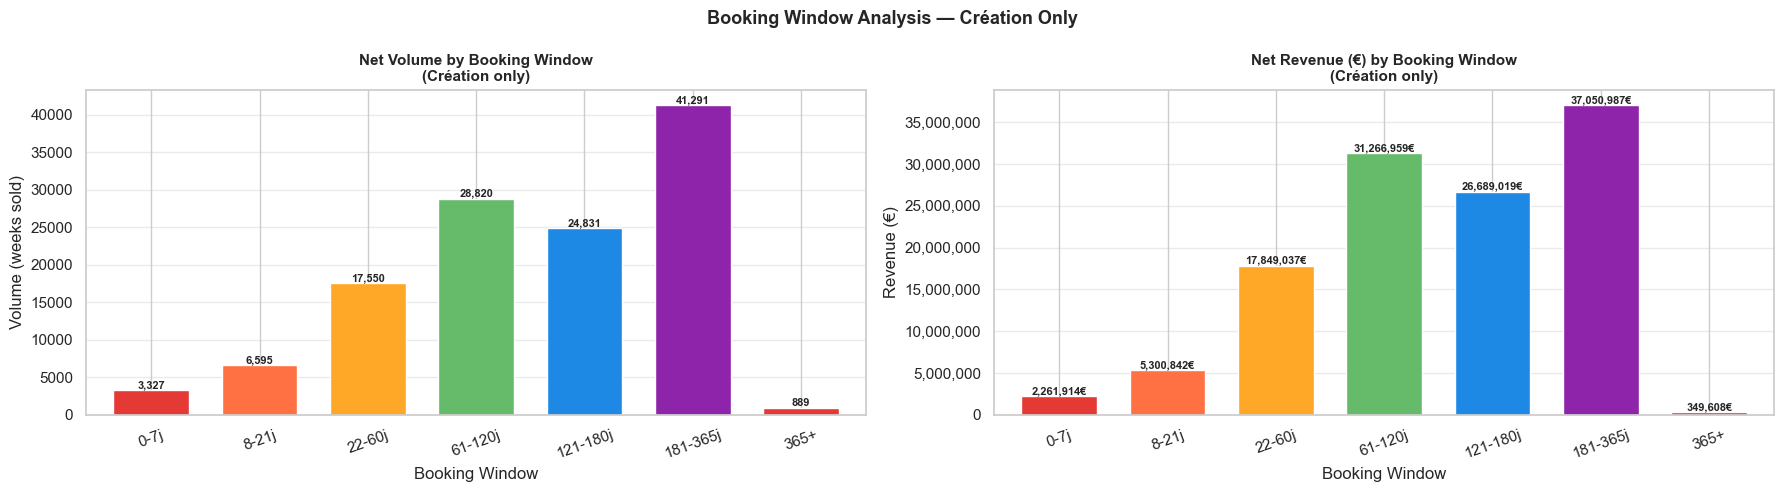

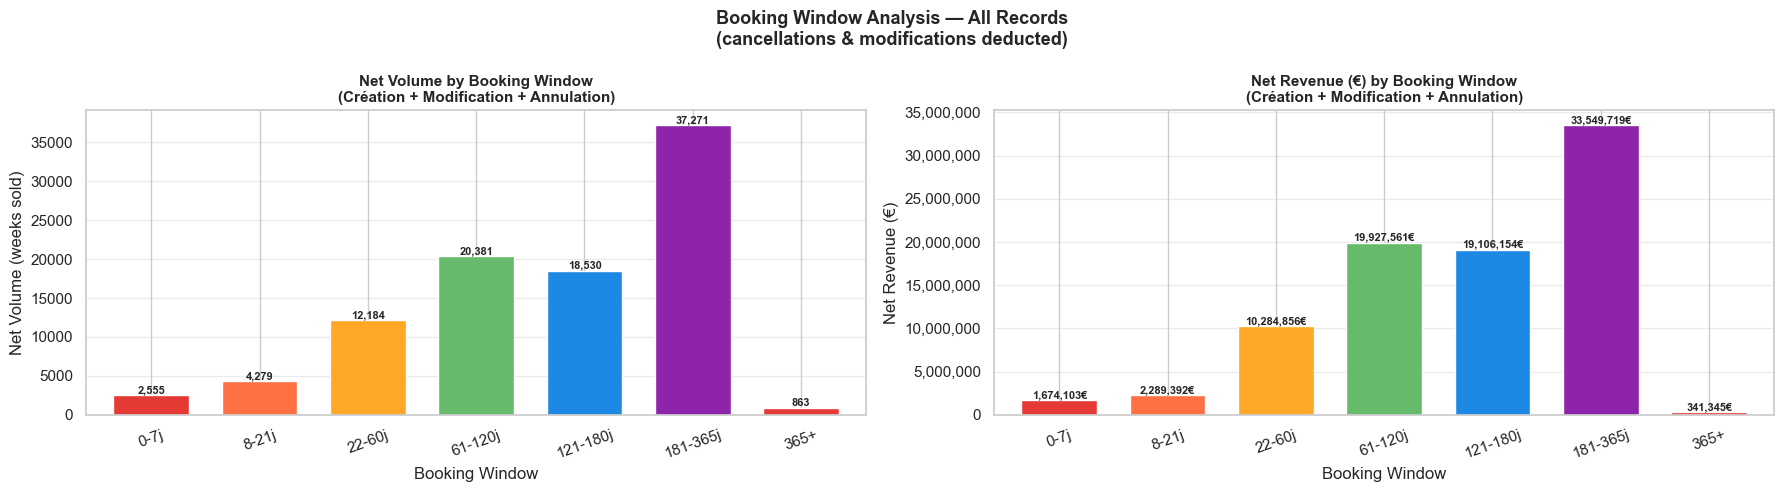

In [45]:
# --- Graphique 1 : Création uniquement ---


lead_filtre = data.copy()

creations_bw = lead_filtre[lead_filtre['ETAT_DOSSIER'] == 'Création']

COLORS_BW = ['#E53935', '#FF7043', '#FFA726', '#66BB6A', '#1E88E5', '#8E24AA']

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

creations_bw.groupby('BOOKING_WINDOW', observed=True)['VOLUME_N'].sum()\
    .plot(kind='bar', ax=axes[0], color=COLORS_BW, edgecolor='white', width=0.7)
axes[0].set_title('Net Volume by Booking Window\n(Création only)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Booking Window')
axes[0].set_ylabel('Volume (weeks sold)')
axes[0].tick_params(axis='x', rotation=20)
axes[0].grid(axis='y', alpha=0.4)
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():,.0f}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom' if p.get_height() >= 0 else 'top', fontsize=8, fontweight='bold')

creations_bw.groupby('BOOKING_WINDOW', observed=True)['CA_N'].sum()\
    .plot(kind='bar', ax=axes[1], color=COLORS_BW, edgecolor='white', width=0.7)
axes[1].set_title('Net Revenue (€) by Booking Window\n(Création only)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Booking Window')
axes[1].set_ylabel('Revenue (€)')
axes[1].tick_params(axis='x', rotation=20)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[1].grid(axis='y', alpha=0.4)
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():,.0f}€',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom' if p.get_height() >= 0 else 'top', fontsize=8, fontweight='bold')

plt.suptitle('Booking Window Analysis — Création Only', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Graphique 2 : Tout ---
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

lead_filtre.groupby('BOOKING_WINDOW', observed=True)['VOLUME_N'].sum()\
    .plot(kind='bar', ax=axes[0], color=COLORS_BW, edgecolor='white', width=0.7)
axes[0].set_title('Net Volume by Booking Window\n(Création + Modification + Annulation)',
                  fontsize=11, fontweight='bold')
axes[0].set_xlabel('Booking Window')
axes[0].set_ylabel('Net Volume (weeks sold)')
axes[0].tick_params(axis='x', rotation=20)
axes[0].grid(axis='y', alpha=0.4)
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():,.0f}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom' if p.get_height() >= 0 else 'top', fontsize=8, fontweight='bold')

lead_filtre.groupby('BOOKING_WINDOW', observed=True)['CA_N'].sum()\
    .plot(kind='bar', ax=axes[1], color=COLORS_BW, edgecolor='white', width=0.7)
axes[1].set_title('Net Revenue (€) by Booking Window\n(Création + Modification + Annulation)',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('Booking Window')
axes[1].set_ylabel('Net Revenue (€)')
axes[1].tick_params(axis='x', rotation=20)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[1].grid(axis='y', alpha=0.4)
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():,.0f}€',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom' if p.get_height() >= 0 else 'top', fontsize=8, fontweight='bold')

plt.suptitle('Booking Window Analysis — All Records\n(cancellations & modifications deducted)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [46]:
creations_bw = lead_filtre[lead_filtre['ETAT_DOSSIER'] == 'Création'].groupby(
    'BOOKING_WINDOW', observed=True).agg(
    CA_Creations=('CA_N', 'sum'),
    Vol_Creations=('VOLUME_N', 'sum')
).reset_index()

annulations_bw = lead_filtre[lead_filtre['ETAT_DOSSIER'] == 'Annulation'].groupby(
    'BOOKING_WINDOW', observed=True).agg(
    CA_Annulations=('CA_N', 'sum'),
    Vol_Annulations=('VOLUME_N', 'sum')
).reset_index()

modifs_bw = lead_filtre[lead_filtre['ETAT_DOSSIER'] == 'Modification'].groupby(
    'BOOKING_WINDOW', observed=True).agg(
    CA_Modifications=('CA_N', 'sum'),
    Vol_Modifications=('VOLUME_N', 'sum')
).reset_index()

bw_stats = creations_bw\
    .merge(annulations_bw, on='BOOKING_WINDOW', how='left')\
    .merge(modifs_bw, on='BOOKING_WINDOW', how='left')

num_cols = ['CA_Annulations', 'Vol_Annulations', 'CA_Modifications', 'Vol_Modifications']
bw_stats[num_cols] = bw_stats[num_cols].fillna(0)

bw_stats['CA_Net']  = bw_stats['CA_Creations'] + bw_stats['CA_Annulations'] + bw_stats['CA_Modifications']
bw_stats['Vol_Net'] = bw_stats['Vol_Creations'] + bw_stats['Vol_Annulations'] + bw_stats['Vol_Modifications']

bw_stats['Taux_Annulation_CA']     = (bw_stats['CA_Annulations'].abs()   / bw_stats['CA_Creations']  * 100).round(2)
bw_stats['Taux_Annulation_Volume'] = (bw_stats['Vol_Annulations'].abs()  / bw_stats['Vol_Creations'] * 100).round(2)
bw_stats['Taux_Modif_CA']          = (bw_stats['CA_Modifications'].abs() / bw_stats['CA_Creations']  * 100).round(2)
bw_stats['PMV']                    = (bw_stats['CA_Net'] / bw_stats['Vol_Net'].replace(0, np.nan)).round(2)

print('Booking Window Analysis :')
display(bw_stats)

Booking Window Analysis :


,BOOKING_WINDOW,CA_Creations,Vol_Creations,CA_Annulations,Vol_Annulations,CA_Modifications,Vol_Modifications,CA_Net,Vol_Net,Taux_Annulation_CA,Taux_Annulation_Volume,Taux_Modif_CA,PMV
0,0-7j,2261913.75,3327.14,-465733.01,-657.29,-122077.44,-115.14,1674103.31,2554.71,20.59,19.76,5.40,655.30
1,8-21j,5300841.54,6595.43,-2755387.65,-2040.71,-256061.48,-276.00,2289392.41,4278.71,51.98,30.94,4.83,535.07
2,22-60j,17849037.29,17549.71,-6350473.81,-4108.43,-1213707.03,-1257.57,10284856.46,12183.71,35.58,23.41,6.80,844.15
3,61-120j,31266958.99,28819.56,-6677723.18,-4714.14,-4661674.45,-3724.28,19927561.36,20381.14,21.36,16.36,14.91,977.75
4,121-180j,26689019.07,24830.85,-4143886.86,-3546.57,-3438977.87,-2754.28,19106154.34,18530.00,15.53,14.28,12.89,1031.09
5,181-365j,37050987.46,41290.83,-3163088.62,-3302.14,-338179.36,-717.99,33549719.48,37270.70,8.54,8.00,0.91,900.16
6,365+,349608.30,888.85,-9314.82,-29.43,1051.22,3.86,341344.70,863.28,2.66,3.31,0.30,395.40


### 5.4 Analyse de la saisonnalité — N vs N-1 FDS

> **Justification — Transcript métier** : La comparaison CA_N vs CA_N1FDS permet de mesurer la performance de l'année en cours par rapport à l'historique finalisé. CA_N1FDS est la **référence** car c'est le CA final de l'exercice précédent (100% des réservations réalisées).

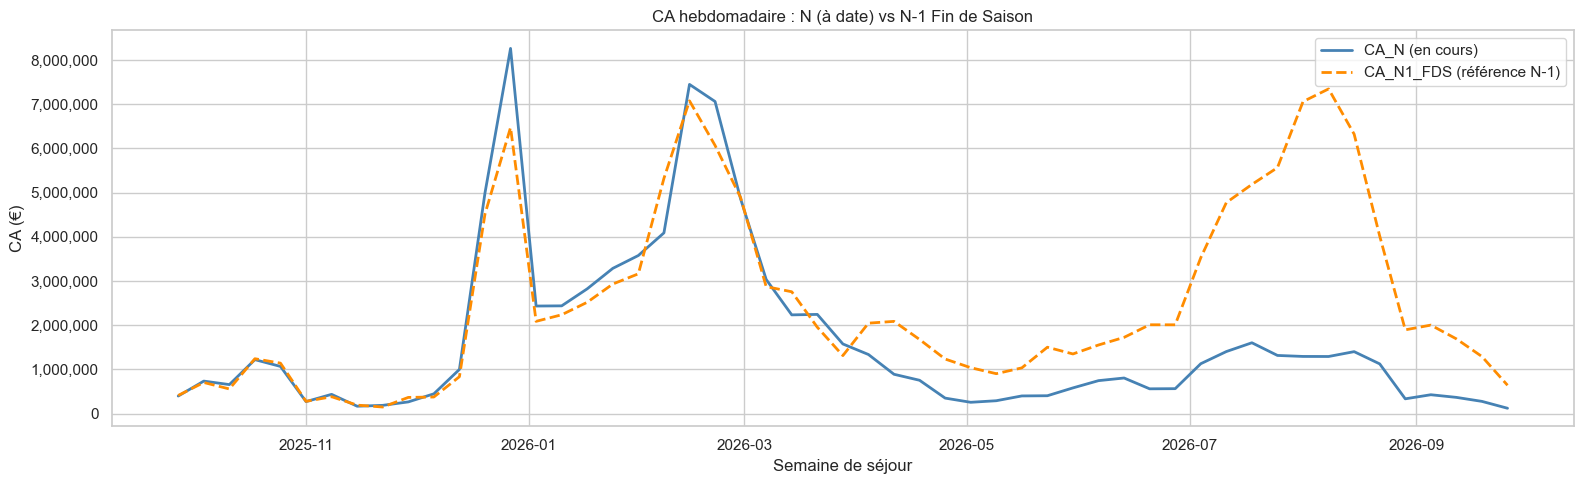

In [47]:
# Évolution hebdomadaire CA_N vs CA_N1FDS
weekly_comp = data.groupby('SEMAINE_SEJOUR').agg(
    CA_N=('CA_N', 'sum'),
    CA_N1FDS=('CA_N1FDS', 'sum')
).reset_index()

plt.figure(figsize=(16, 5))
plt.plot(weekly_comp['SEMAINE_SEJOUR'], weekly_comp['CA_N'], label='CA_N (en cours)', color='steelblue', linewidth=2)
plt.plot(weekly_comp['SEMAINE_SEJOUR'], weekly_comp['CA_N1FDS'], label='CA_N1_FDS (référence N-1)', color='darkorange', linewidth=2, linestyle='--')
plt.title('CA hebdomadaire : N (à date) vs N-1 Fin de Saison', fontsize=12)
plt.xlabel('Semaine de séjour')
plt.ylabel('CA (€)')
plt.legend()
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()

### 5.6 Analyse des annulations

> **Référence — Ampountolas & Legg (2025)** : Les annulations représentent un signal fort pour le revenue management. Près d'un tiers des annulations sont last-minute. Leur analyse par segment, canal et booking window permet de mieux calibrer les stratégies de yield.

In [48]:
creations_seg = data[data['ETAT_DOSSIER'] == 'Création'].groupby(
    'SEGMENT_DOSSIER', observed=True).agg(
    CA_Creations=('CA_N', 'sum'),
    Vol_Creations=('VOLUME_N', 'sum')
).reset_index()

annulations_seg = data[data['ETAT_DOSSIER'] == 'Annulation'].groupby(
    'SEGMENT_DOSSIER', observed=True).agg(
    CA_Annulations=('CA_N', 'sum'),
    Vol_Annulations=('VOLUME_N', 'sum')
).reset_index()

modifs_seg = data[data['ETAT_DOSSIER'] == 'Modification'].groupby(
    'SEGMENT_DOSSIER', observed=True).agg(
    CA_Modifications=('CA_N', 'sum'),
    Vol_Modifications=('VOLUME_N', 'sum')
).reset_index()

ann_seg = creations_seg\
    .merge(annulations_seg, on='SEGMENT_DOSSIER', how='left')\
    .merge(modifs_seg, on='SEGMENT_DOSSIER', how='left')

num_cols = ['CA_Annulations', 'Vol_Annulations', 'CA_Modifications', 'Vol_Modifications']
ann_seg[num_cols] = ann_seg[num_cols].fillna(0)

ann_seg['CA_Net']  = ann_seg['CA_Creations'] + ann_seg['CA_Annulations'] + ann_seg['CA_Modifications']
ann_seg['Vol_Net'] = ann_seg['Vol_Creations'] + ann_seg['Vol_Annulations'] + ann_seg['Vol_Modifications']

ann_seg['Taux_Annulation_CA']     = (ann_seg['CA_Annulations'].abs()   / ann_seg['CA_Creations']  * 100).round(2)
ann_seg['Taux_Annulation_Volume'] = (ann_seg['Vol_Annulations'].abs()  / ann_seg['Vol_Creations'] * 100).round(2)
ann_seg['Taux_Modif_CA']          = (ann_seg['CA_Modifications'].abs() / ann_seg['CA_Creations']  * 100).round(2)

print('Cancellation & Modification Analysis by Segment :')
display(ann_seg)

Cancellation & Modification Analysis by Segment :


,SEGMENT_DOSSIER,CA_Creations,Vol_Creations,CA_Annulations,Vol_Annulations,CA_Modifications,Vol_Modifications,CA_Net,Vol_Net,Taux_Annulation_CA,Taux_Annulation_Volume,Taux_Modif_CA
0,Allotement,11010932.02,13844.45,-705778.93,-687.14,-9613.85,0.29,10295539.23,13157.59,6.41,4.96,0.09
1,Groupe,8583800.10,12769.14,-2278397.51,-2806.86,165347.61,-841.57,6470750.20,9120.71,26.54,21.98,1.93
2,INDIV,101173634.29,96688.79,-20581431.51,-14904.72,-10185360.16,-8000.12,70406842.63,73783.95,20.34,15.42,10.07


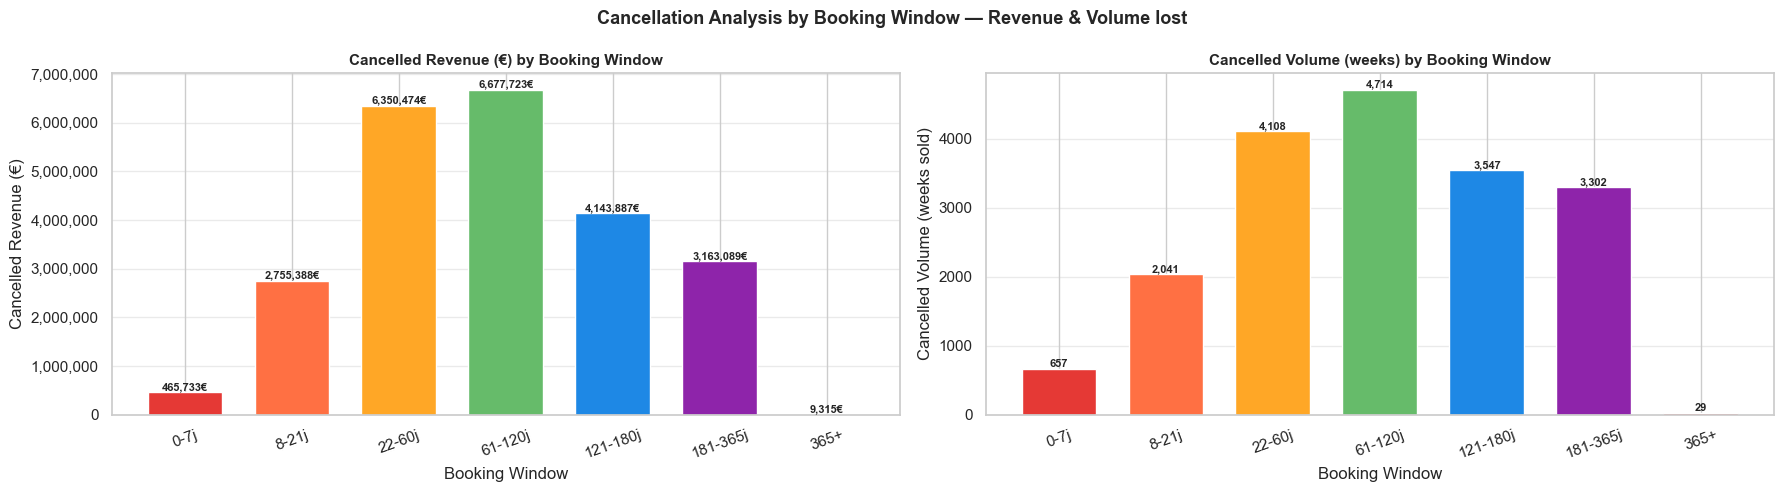

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# --- CA annulé par booking window ---
ann_bw_ca = lead_filtre[lead_filtre['ETAT_DOSSIER'] == 'Annulation'].groupby(
    'BOOKING_WINDOW', observed=True)['CA_N'].sum().abs().reset_index()

axes[0].bar(ann_bw_ca['BOOKING_WINDOW'].astype(str), ann_bw_ca['CA_N'],
            color=COLORS_BW, edgecolor='white', width=0.7)
axes[0].set_title('Cancelled Revenue (€) by Booking Window', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Booking Window')
axes[0].set_ylabel('Cancelled Revenue (€)')
axes[0].tick_params(axis='x', rotation=20)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[0].grid(axis='y', alpha=0.4)
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():,.0f}€',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=8, fontweight='bold')

# --- Volume annulé par booking window ---
ann_bw_vol = lead_filtre[lead_filtre['ETAT_DOSSIER'] == 'Annulation'].groupby(
    'BOOKING_WINDOW', observed=True)['VOLUME_N'].sum().abs().reset_index()

axes[1].bar(ann_bw_vol['BOOKING_WINDOW'].astype(str), ann_bw_vol['VOLUME_N'],
            color=COLORS_BW, edgecolor='white', width=0.7)
axes[1].set_title('Cancelled Volume (weeks) by Booking Window', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Booking Window')
axes[1].set_ylabel('Cancelled Volume (weeks sold)')
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(axis='y', alpha=0.4)
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():,.0f}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.suptitle('Cancellation Analysis by Booking Window — Revenue & Volume lost',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

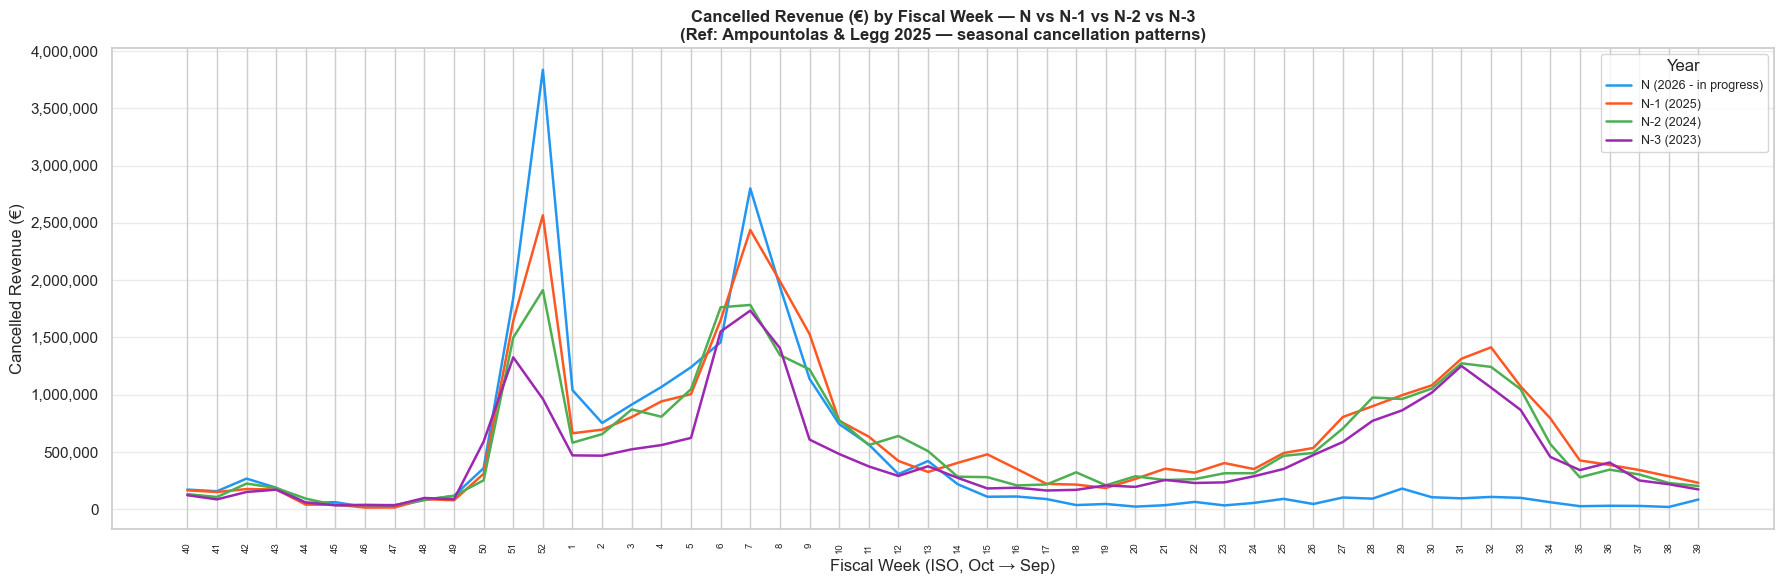

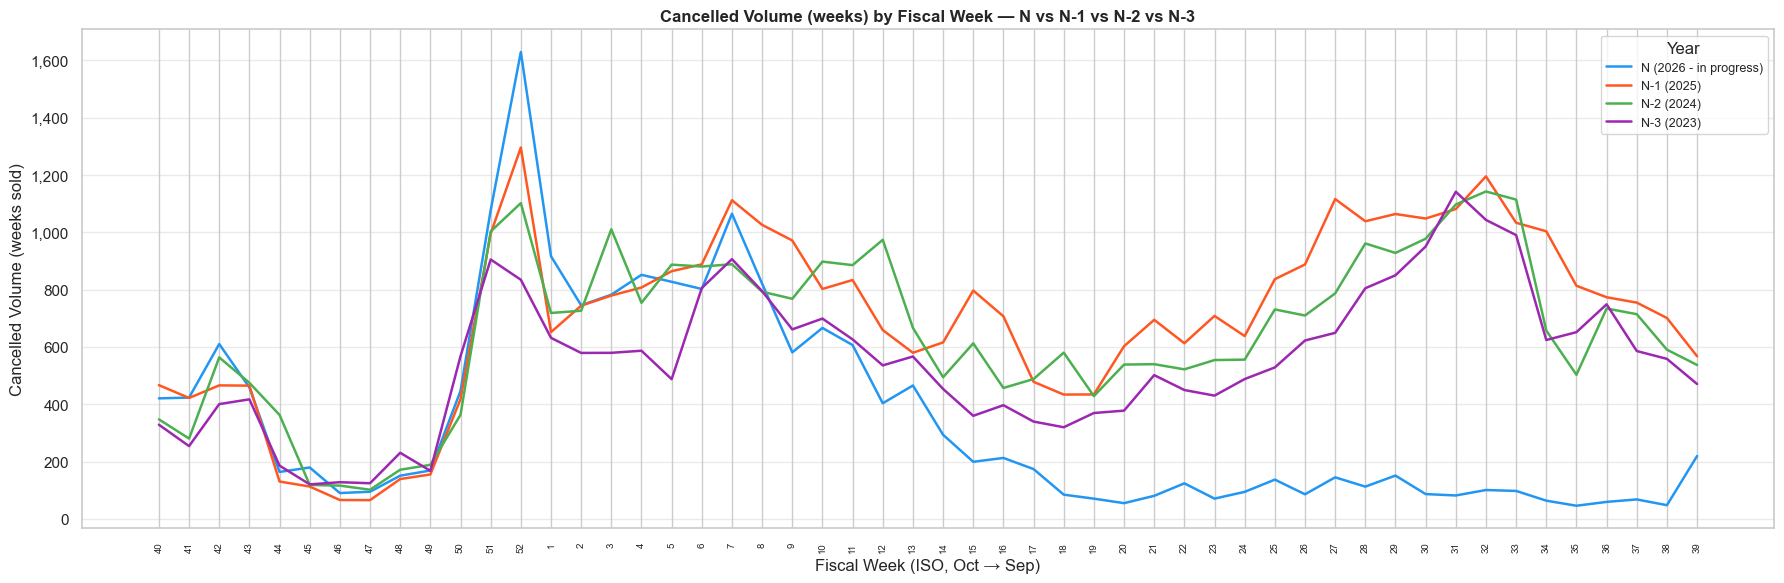

In [50]:
ca_map_ann = {
    'N (2026)':   'CA_N',
    'N-1 (2025)': 'CA_N1FDS',
    'N-2 (2024)': 'CA_N2FDS',
    'N-3 (2023)': 'CA_N3FDS'
}
vol_map_ann = {
    'N (2026)':   'VOLUME_N',
    'N-1 (2025)': 'VOLUME_N1FDS',
    'N-2 (2024)': 'VOLUME_N2FDS',
    'N-3 (2023)': 'VOLUME_N3FDS'
}
COLORS_YEAR = ['#2196F3', '#FF5722', '#4CAF50', '#9C27B0']

annulations_data = data[data['ETAT_DOSSIER'] == 'Annulation'].copy()
annulations_data['SEMAINE_NUM'] = annulations_data['SEMAINE_SEJOUR'].dt.isocalendar().week.astype(int)

fiscal_order = list(range(40, 53)) + list(range(1, 40))

# --- Graphique 1 : CA annulé par semaine fiscale ---
fig, ax = plt.subplots(figsize=(18, 6))

for (year, ca_col), color in zip(ca_map_ann.items(), COLORS_YEAR):
    weekly_ann = annulations_data.groupby('SEMAINE_NUM')[ca_col].sum().abs().reset_index()
    weekly_ann['FISCAL_ORDER'] = weekly_ann['SEMAINE_NUM'].map({w: i for i, w in enumerate(fiscal_order)})
    weekly_ann = weekly_ann.sort_values('FISCAL_ORDER')

    label = year if year != 'N (2026)' else 'N (2026 - in progress)'
    ax.plot(weekly_ann['FISCAL_ORDER'], weekly_ann[ca_col],
            color=color, linewidth=1.8, label=label)

ax.set_xticks(range(0, 52, 1))
ax.set_xticklabels([str(fiscal_order[i]) for i in range(0, 52)], rotation=90, fontsize=7)
ax.set_title('Cancelled Revenue (€) by Fiscal Week — N vs N-1 vs N-2 vs N-3\n'
             '(Ref: Ampountolas & Legg 2025 — seasonal cancellation patterns)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Fiscal Week (ISO, Oct → Sep)')
ax.set_ylabel('Cancelled Revenue (€)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.legend(title='Year', fontsize=9)
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

# --- Graphique 2 : Volume annulé par semaine fiscale ---
fig, ax = plt.subplots(figsize=(18, 6))

for (year, vol_col), color in zip(vol_map_ann.items(), COLORS_YEAR):
    weekly_ann_vol = annulations_data.groupby('SEMAINE_NUM')[vol_col].sum().abs().reset_index()
    weekly_ann_vol['FISCAL_ORDER'] = weekly_ann_vol['SEMAINE_NUM'].map({w: i for i, w in enumerate(fiscal_order)})
    weekly_ann_vol = weekly_ann_vol.sort_values('FISCAL_ORDER')

    label = year if year != 'N (2026)' else 'N (2026 - in progress)'
    ax.plot(weekly_ann_vol['FISCAL_ORDER'], weekly_ann_vol[vol_col],
            color=color, linewidth=1.8, label=label)

ax.set_xticks(range(0, 52, 1))
ax.set_xticklabels([str(fiscal_order[i]) for i in range(0, 52)], rotation=90, fontsize=7)
ax.set_title('Cancelled Volume (weeks) by Fiscal Week — N vs N-1 vs N-2 vs N-3',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Fiscal Week (ISO, Oct → Sep)')
ax.set_ylabel('Cancelled Volume (weeks sold)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.legend(title='Year', fontsize=9)
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

### 5.7 Analyses multivariées complémentaires

> *Source : exploration v1.* On complète l'analyse avancée par :
> - Le **V de Cramér** entre variables catégorielles (force d'association).
> - La **matrice de corrélation** des variables numériques (CA / Volume / Stock).
> - Des **tableaux croisés** CA/Volume par type d'établissement × durée de séjour.


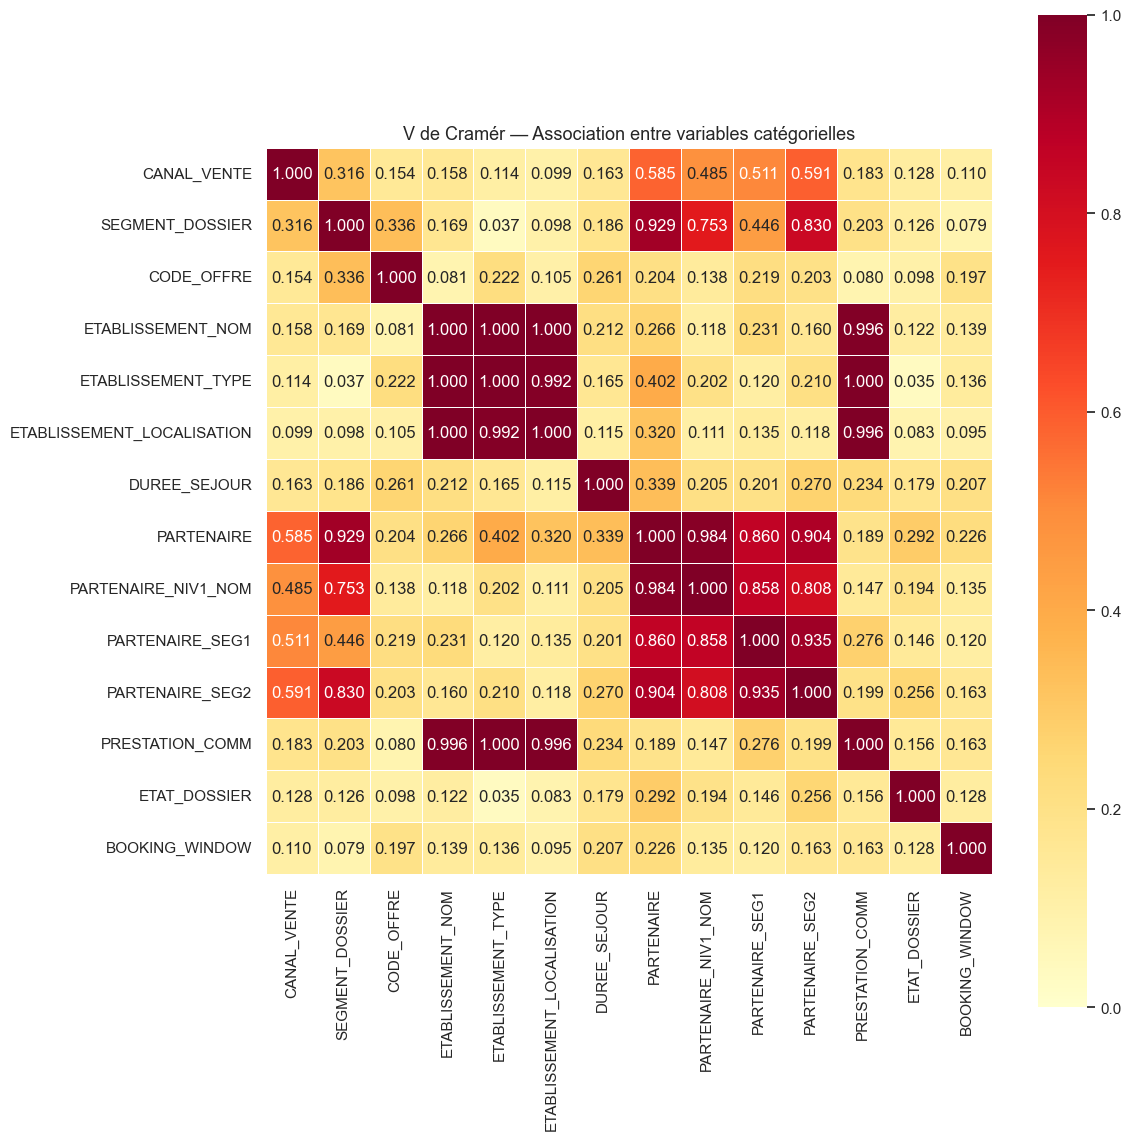

In [51]:
## Calcul du V de Cramér entre deux variables catégorielles.
def cramers_v(x, y):
    """Calcul du V de Cramér entre deux variables catégorielles."""
    confusion_matrix = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    min_dim = min(confusion_matrix.shape) - 1
    return np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0

# Variables catégorielles à tester
cat_vars = data.select_dtypes(include='category').columns.tolist()

# Filtrer les NaN pour le calcul
data_cat = data[cat_vars].dropna()

# Matrice du V de Cramér
n_vars = len(cat_vars)
cramer_matrix = pd.DataFrame(np.zeros((n_vars, n_vars)), index=cat_vars, columns=cat_vars)

for i in range(n_vars):
    for j in range(i, n_vars):
        if i == j:
            cramer_matrix.iloc[i, j] = 1.0
        else:
            v = cramers_v(data_cat[cat_vars[i]], data_cat[cat_vars[j]])
            cramer_matrix.iloc[i, j] = v
            cramer_matrix.iloc[j, i] = v

fig, ax = plt.subplots(figsize=(12, 12))
sns.heatmap(cramer_matrix.astype(float), annot=True, fmt='.3f', cmap='YlOrRd',
            ax=ax, vmin=0, vmax=1, square=True, linewidths=0.5)
ax.set_title('V de Cramér — Association entre variables catégorielles', fontsize=13)
plt.tight_layout()
plt.show()

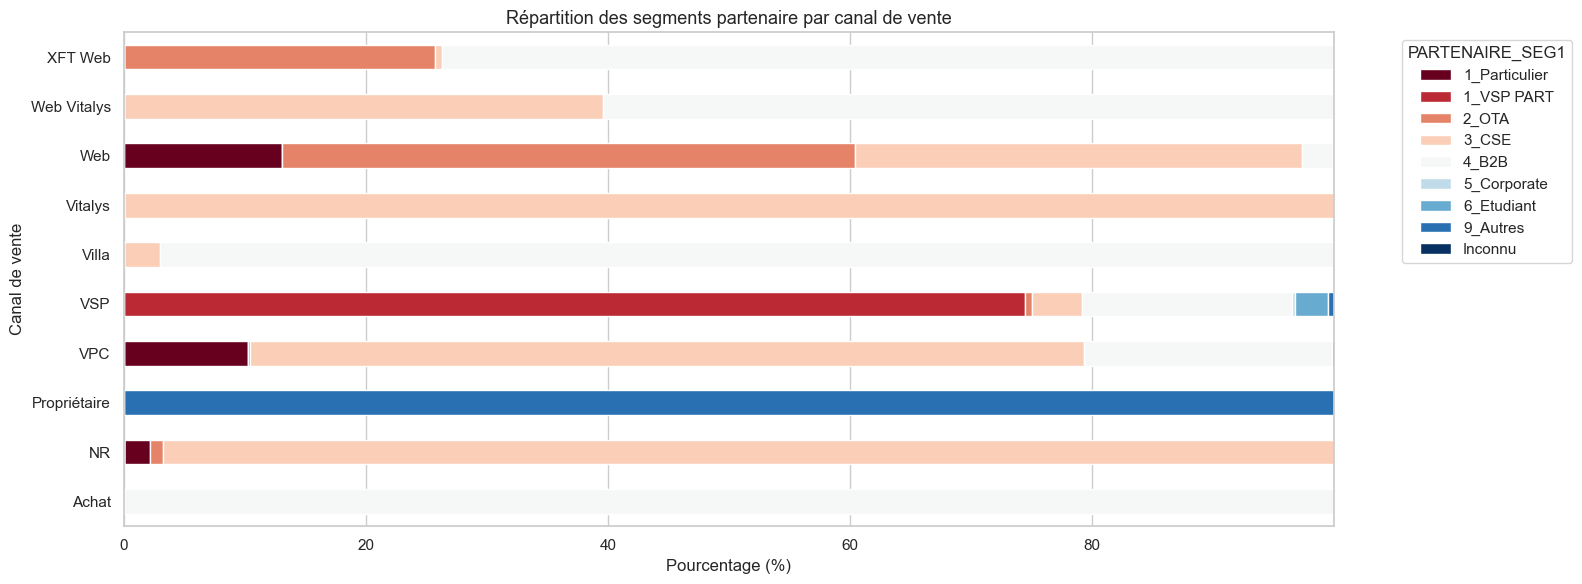

In [52]:
# Profils lignes : répartition (%) des segments partenaire par canal de vente
cross_pct = pd.crosstab(data['CANAL_VENTE'], data['PARTENAIRE_SEG1'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(16, 6))
cross_pct.plot(kind='barh', stacked=True, ax=ax, colormap='RdBu')
ax.set_title('Répartition des segments partenaire par canal de vente', fontsize=13)
ax.set_xlabel('Pourcentage (%)')
ax.set_ylabel('Canal de vente')
ax.legend(title='PARTENAIRE_SEG1', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

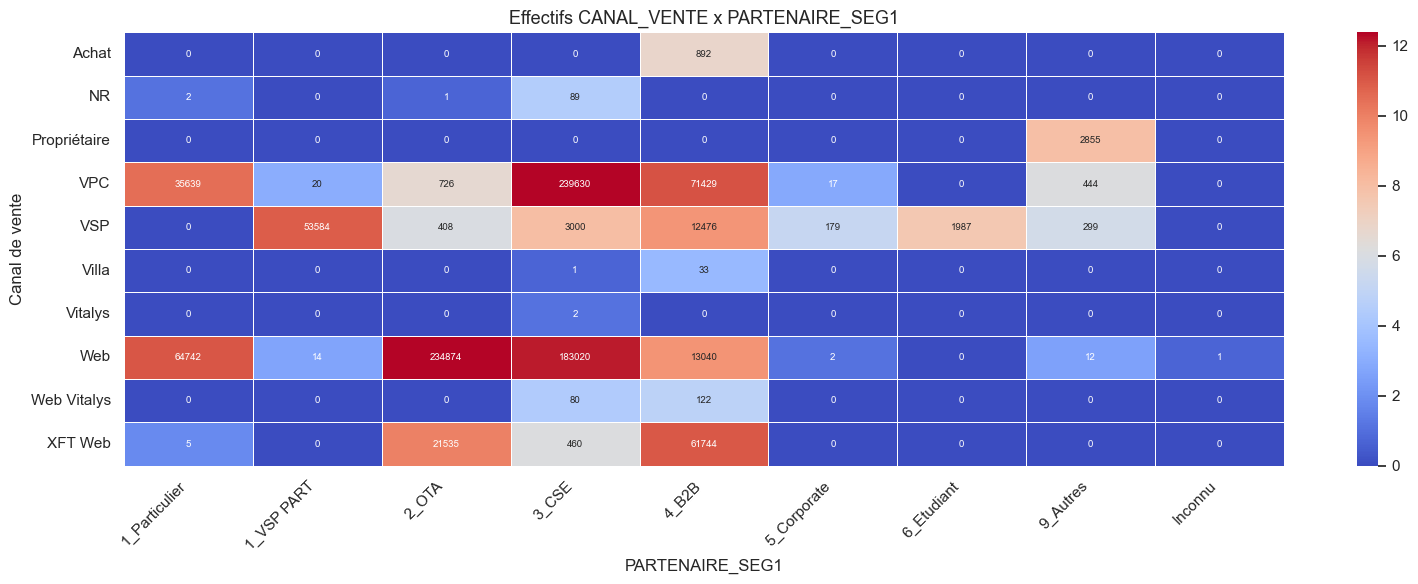

In [53]:
# Tableau croisé plus détaillé : CANAL_VENTE x PARTENAIRE_SEG1
cross_canal_seg2 = pd.crosstab(data['CANAL_VENTE'], data['PARTENAIRE_SEG1'])

# Heatmap des effectifs (log scale pour lisibilité)
fig, ax = plt.subplots(figsize=(16, 6))
sns.heatmap(np.log1p(cross_canal_seg2), annot=cross_canal_seg2.values, fmt='d',
            cmap='coolwarm', ax=ax, linewidths=0.5, annot_kws={'size': 7})
ax.set_title('Effectifs CANAL_VENTE x PARTENAIRE_SEG1', fontsize=13)
ax.set_ylabel('Canal de vente')
ax.set_xlabel('PARTENAIRE_SEG1')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

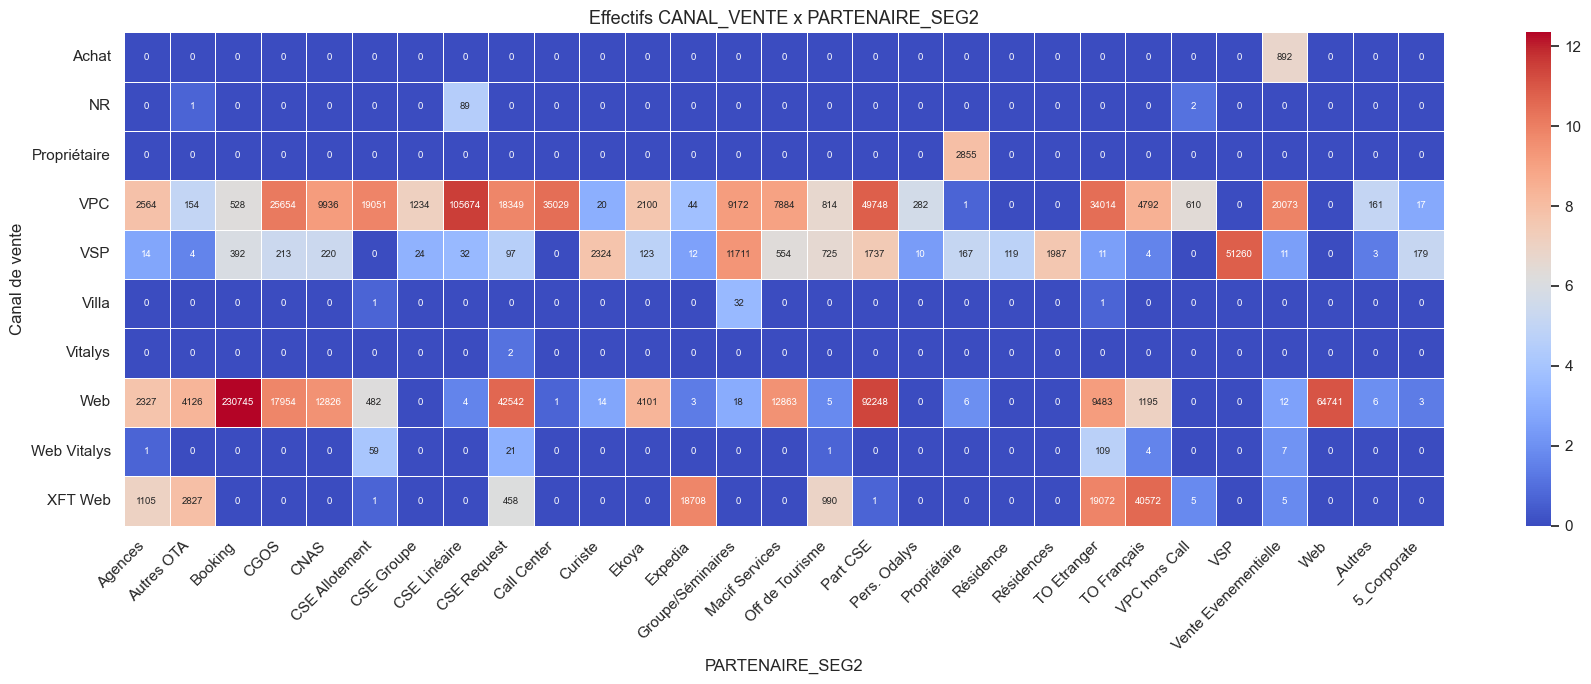

In [54]:
# Tableau croisé plus détaillé : CANAL_VENTE x PARTENAIRE_SEG2
cross_canal_seg2 = pd.crosstab(data['CANAL_VENTE'], data['PARTENAIRE_SEG2'])

# Heatmap des effectifs (log scale pour lisibilité)
fig, ax = plt.subplots(figsize=(18, 7))
sns.heatmap(np.log1p(cross_canal_seg2), annot=cross_canal_seg2.values, fmt='d',
            cmap='coolwarm', ax=ax, linewidths=0.5, annot_kws={'size': 7})
ax.set_title('Effectifs CANAL_VENTE x PARTENAIRE_SEG2', fontsize=13)
ax.set_ylabel('Canal de vente')
ax.set_xlabel('PARTENAIRE_SEG2')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [55]:
import plotly.graph_objects as go

flux = data.groupby(['PARTENAIRE_SEG1', 'PARTENAIRE_SEG2']).size().reset_index(name='count')
labels = list(flux['PARTENAIRE_SEG1'].unique()) + list(flux['PARTENAIRE_SEG2'].unique())

source = flux['PARTENAIRE_SEG1'].map({v: i for i, v in enumerate(labels)})
target = flux['PARTENAIRE_SEG2'].map({v: i for i, v in enumerate(labels)})

fig = go.Figure(go.Sankey(
    node=dict(
        label=labels,
        pad=30,
        thickness=25
    ),
    link=dict(
        source=source,
        target=target,
        value=flux['count'],
        color='rgba(33, 150, 243, 0.3)',
    )
))

fig.update_layout(
    title='PARTENAIRE_SEG1 → PARTENAIRE_SEG2',
    font=dict(size=13),
    height=700,
    width=1100,
)

fig.show()

In [56]:
# Sankey multi-niveaux : PARTENAIRE_SEG1 → PARTENAIRE_SEG2 → PARTENAIRE_NIV1_NOM (top 15)
import plotly.graph_objects as go

data_part = data[['PARTENAIRE_SEG1', 'PARTENAIRE_SEG2', 'PARTENAIRE_NIV1_NOM']].dropna()

# Niveau 1 → 2
flux_12 = data_part.groupby(['PARTENAIRE_SEG1', 'PARTENAIRE_SEG2'], observed=True).size().reset_index(name='count')

# Niveau 2 → NIV1 (top 15 par volume pour lisibilité)
top_niv1 = data_part['PARTENAIRE_NIV1_NOM'].value_counts().head(15).index
data_part_top = data_part[data_part['PARTENAIRE_NIV1_NOM'].isin(top_niv1)]
flux_23 = data_part_top.groupby(['PARTENAIRE_SEG2', 'PARTENAIRE_NIV1_NOM'], observed=True).size().reset_index(name='count')

# Construire les labels uniques
seg1_labels = list(flux_12['PARTENAIRE_SEG1'].unique())
seg2_labels = list(flux_12['PARTENAIRE_SEG2'].unique())
niv1_labels = list(flux_23['PARTENAIRE_NIV1_NOM'].unique())
all_labels = seg1_labels + seg2_labels + niv1_labels

# Index mapping
label_to_idx = {label: i for i, label in enumerate(all_labels)}

# Liens SEG1 → SEG2
sources_12 = [label_to_idx[s] for s in flux_12['PARTENAIRE_SEG1']]
targets_12 = [label_to_idx[t] for t in flux_12['PARTENAIRE_SEG2']]
values_12 = flux_12['count'].tolist()

# Liens SEG2 → NIV1
sources_23 = [label_to_idx[s] for s in flux_23['PARTENAIRE_SEG2']]
targets_23 = [label_to_idx[t] for t in flux_23['PARTENAIRE_NIV1_NOM']]
values_23 = flux_23['count'].tolist()

fig = go.Figure(go.Sankey(
    node=dict(
        label=all_labels,
        pad=20,
        thickness=20
    ),
    link=dict(
        source=sources_12 + sources_23,
        target=targets_12 + targets_23,
        value=values_12 + values_23,
        color='rgba(33, 150, 243, 0.25)',
    )
))

fig.update_layout(
    title='Hiérarchie partenaires : SEG1 → SEG2 → NIV1_NOM',
    font=dict(size=12),
    height=700,
    width=1200,
)
fig.show()

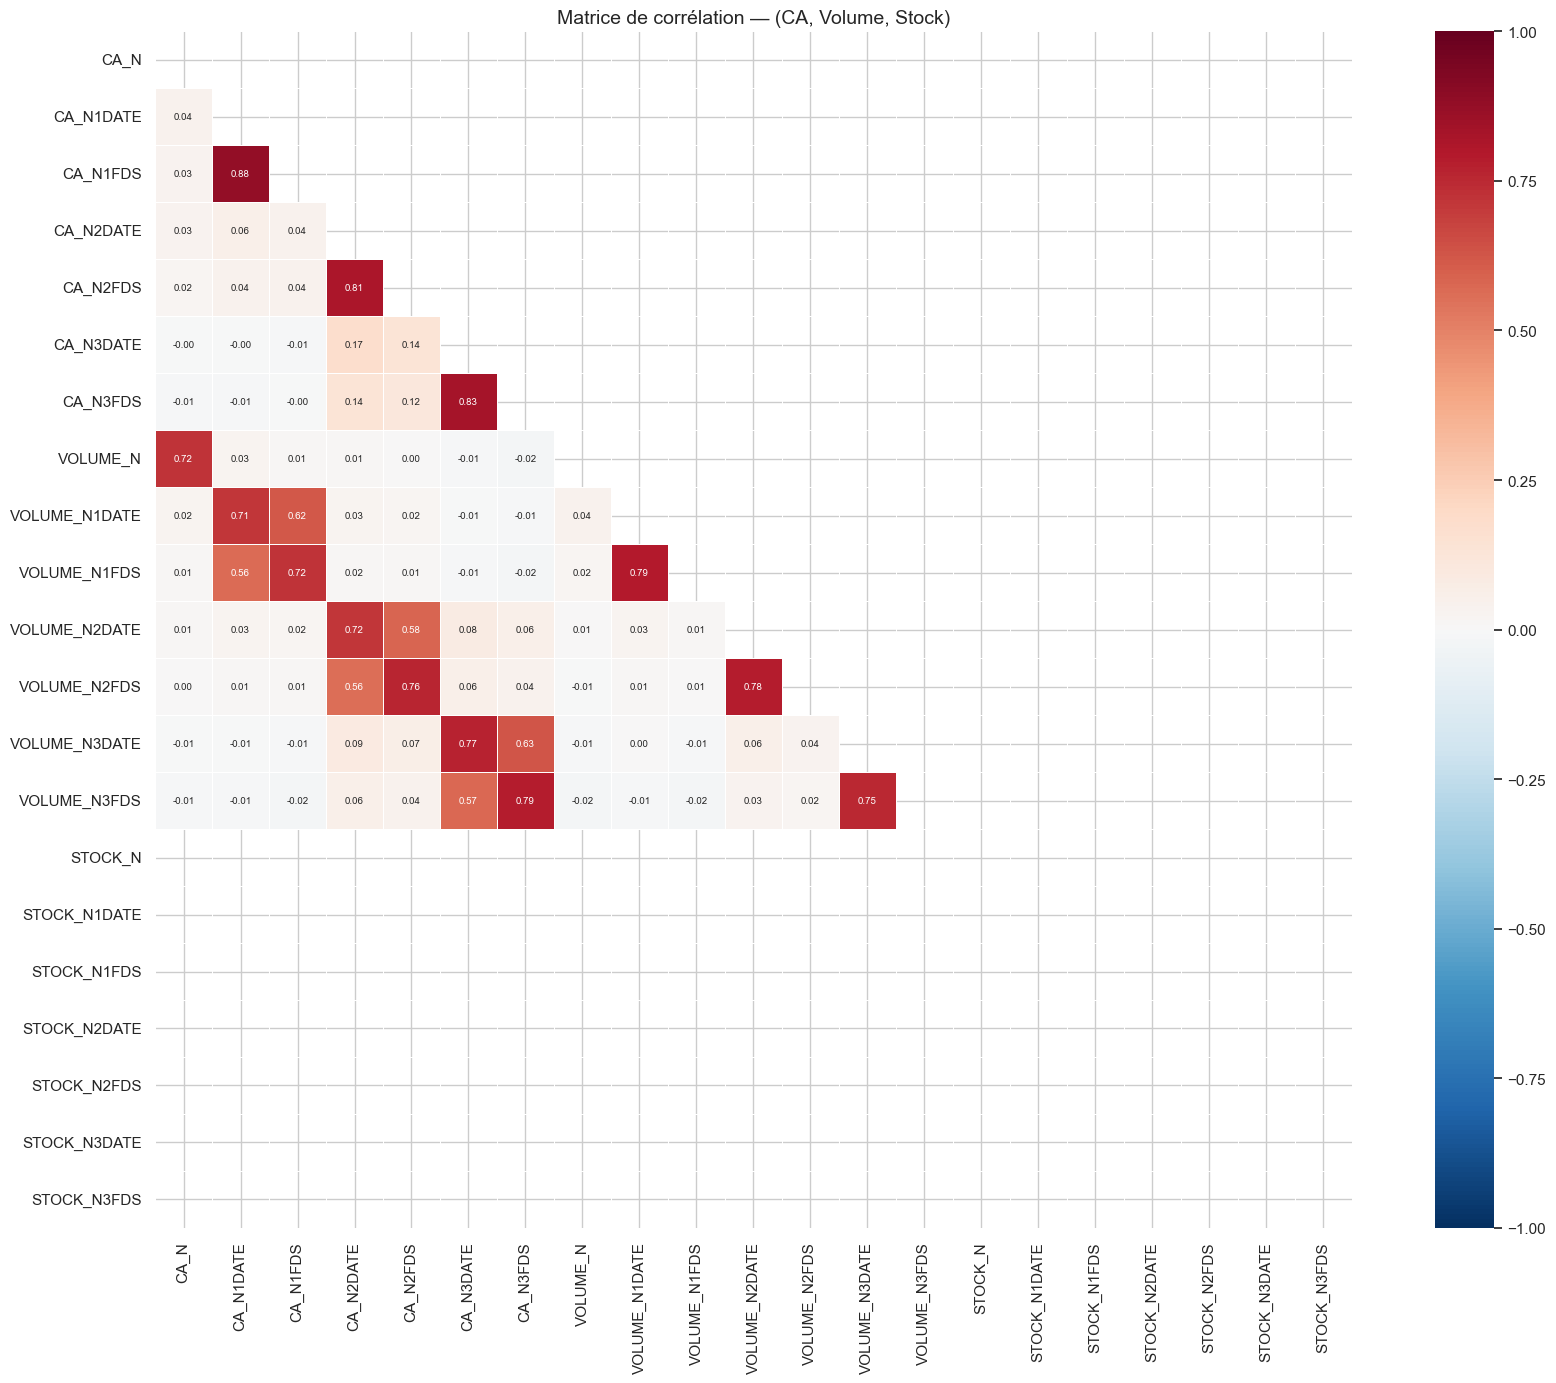

In [57]:
# Variables numériques d'intérêt
num_cols = ['CA_N', 'CA_N1DATE', 'CA_N1FDS', 'CA_N2DATE', 'CA_N2FDS', 'CA_N3DATE', 'CA_N3FDS',
            'VOLUME_N', 'VOLUME_N1DATE', 'VOLUME_N1FDS', 'VOLUME_N2DATE', 'VOLUME_N2FDS', 'VOLUME_N3DATE', 'VOLUME_N3FDS',
            'STOCK_N', 'STOCK_N1DATE', 'STOCK_N1FDS', 'STOCK_N2DATE', 'STOCK_N2FDS', 'STOCK_N3DATE', 'STOCK_N3FDS']

corr_matrix = data[num_cols].corr()

fig, ax = plt.subplots(figsize=(18, 14))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, ax=ax, vmin=-1, vmax=1, annot_kws={'size': 7})
ax.set_title('Matrice de corrélation — (CA, Volume, Stock)', fontsize=14)
plt.tight_layout()
plt.show()

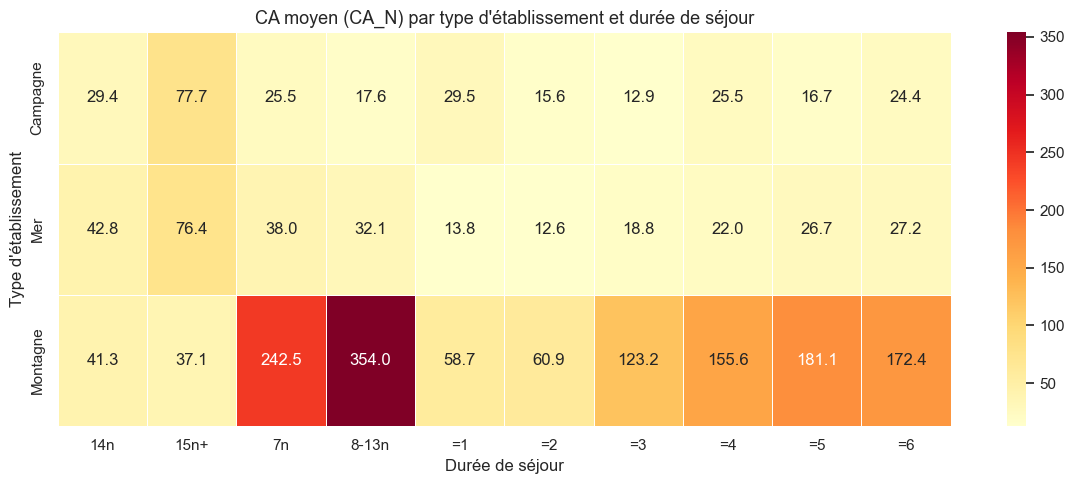

In [58]:
# Tableau croisé CA moyen par type d'établissement et durée de séjour
cross_ca = pd.pivot_table(data, values='CA_N', index='ETABLISSEMENT_TYPE',
                          columns='DUREE_SEJOUR', aggfunc='mean')

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(cross_ca, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax, linewidths=0.5)
ax.set_title('CA moyen (CA_N) par type d\'établissement et durée de séjour', fontsize=13)
ax.set_ylabel('Type d\'établissement')
ax.set_xlabel('Durée de séjour')
plt.tight_layout()
plt.show()

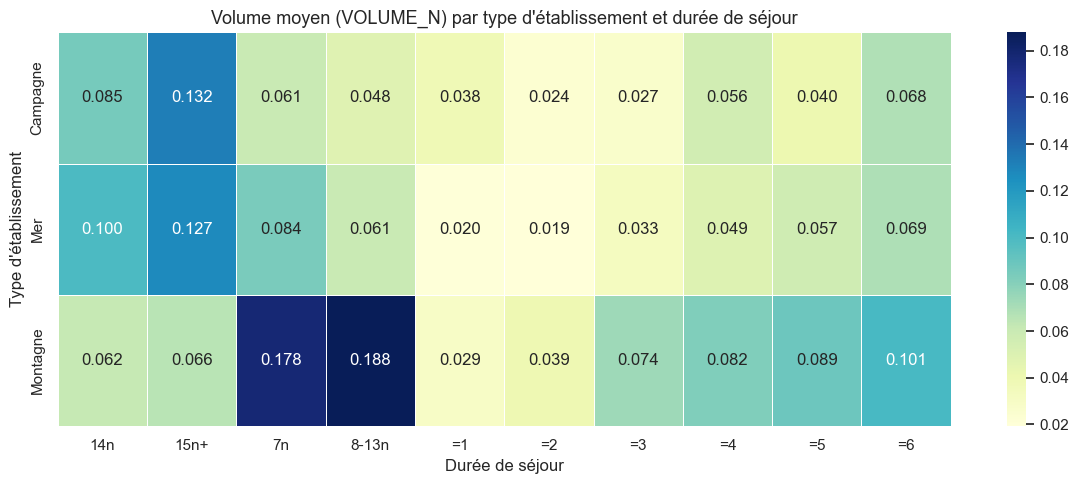

In [59]:
# Même analyse pour le volume
cross_vol = pd.pivot_table(data, values='VOLUME_N', index='ETABLISSEMENT_TYPE',
                           columns='DUREE_SEJOUR', aggfunc='mean')

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(cross_vol, annot=True, fmt='.3f', cmap='YlGnBu', ax=ax, linewidths=0.5)
ax.set_title('Volume moyen (VOLUME_N) par type d\'établissement et durée de séjour', fontsize=13)
ax.set_ylabel('Type d\'établissement')
ax.set_xlabel('Durée de séjour')
plt.tight_layout()
plt.show()

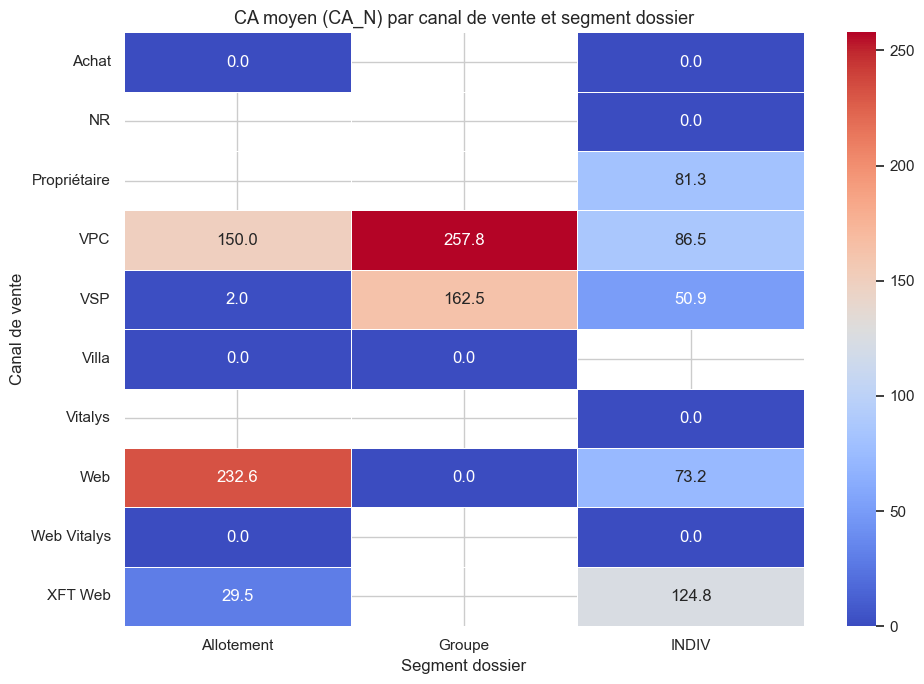

In [60]:
# Tableau croisé CA moyen par canal de vente et segment dossier
cross_canal = pd.pivot_table(data, values='CA_N', index='CANAL_VENTE',
                             columns='SEGMENT_DOSSIER', aggfunc='mean')

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(cross_canal, annot=True, fmt='.1f', cmap='coolwarm', ax=ax, linewidths=0.5)
ax.set_title('CA moyen (CA_N) par canal de vente et segment dossier', fontsize=13)
ax.set_ylabel('Canal de vente')
ax.set_xlabel('Segment dossier')
plt.tight_layout()
plt.show()

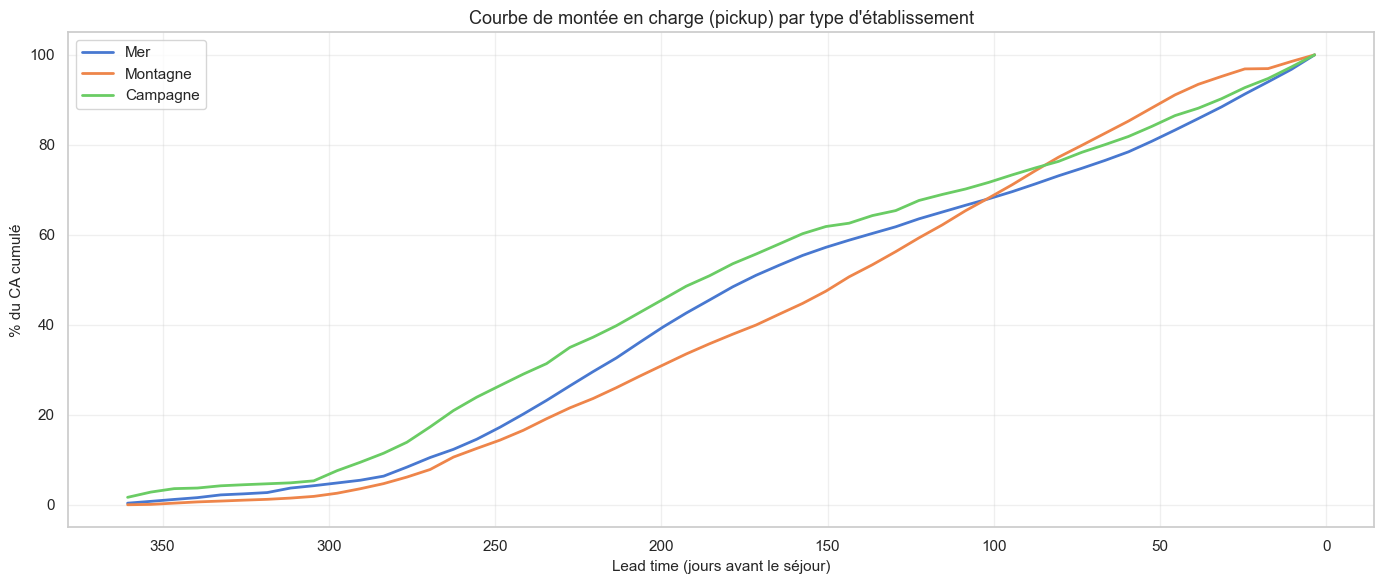

In [61]:
# Montée en charge : CA cumulé par lead time et type d'établissement
# On se restreint aux observations avec lead time positif et raisonnable
data_pickup = data[(data['LEAD_TIME_JOURS'] >= 0) & (data['LEAD_TIME_JOURS'] <= 365) & (data['CA_N'] != 0)].copy()

# Créer des tranches de lead time (bins de 7 jours)
data_pickup['LT_BIN'] = pd.cut(data_pickup['LEAD_TIME_JOURS'], bins=range(0, 371, 7), right=False)

# CA moyen par tranche et type d'établissement
pickup_curve = data_pickup.groupby(['LT_BIN', 'ETABLISSEMENT_TYPE'], observed=True)['CA_N'].sum().reset_index()
pickup_curve['LT_MID'] = pickup_curve['LT_BIN'].apply(lambda x: x.mid)

fig, ax = plt.subplots(figsize=(14, 6))
for etab_type in ['Mer', 'Montagne', 'Campagne']:
    subset = pickup_curve[pickup_curve['ETABLISSEMENT_TYPE'] == etab_type].sort_values('LT_MID', ascending=False)
    subset['CA_CUMUL'] = subset['CA_N'].cumsum()
    # Normaliser pour comparer les profils
    subset['CA_CUMUL_PCT'] = subset['CA_CUMUL'] / subset['CA_CUMUL'].max() * 100
    ax.plot(subset['LT_MID'], subset['CA_CUMUL_PCT'], label=etab_type, linewidth=2)

ax.set_xlabel('Lead time (jours avant le séjour)', fontsize=11)
ax.set_ylabel('% du CA cumulé', fontsize=11)
ax.set_title('Courbe de montée en charge (pickup) par type d\'établissement', fontsize=13)
ax.legend(fontsize=11)
ax.invert_xaxis()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

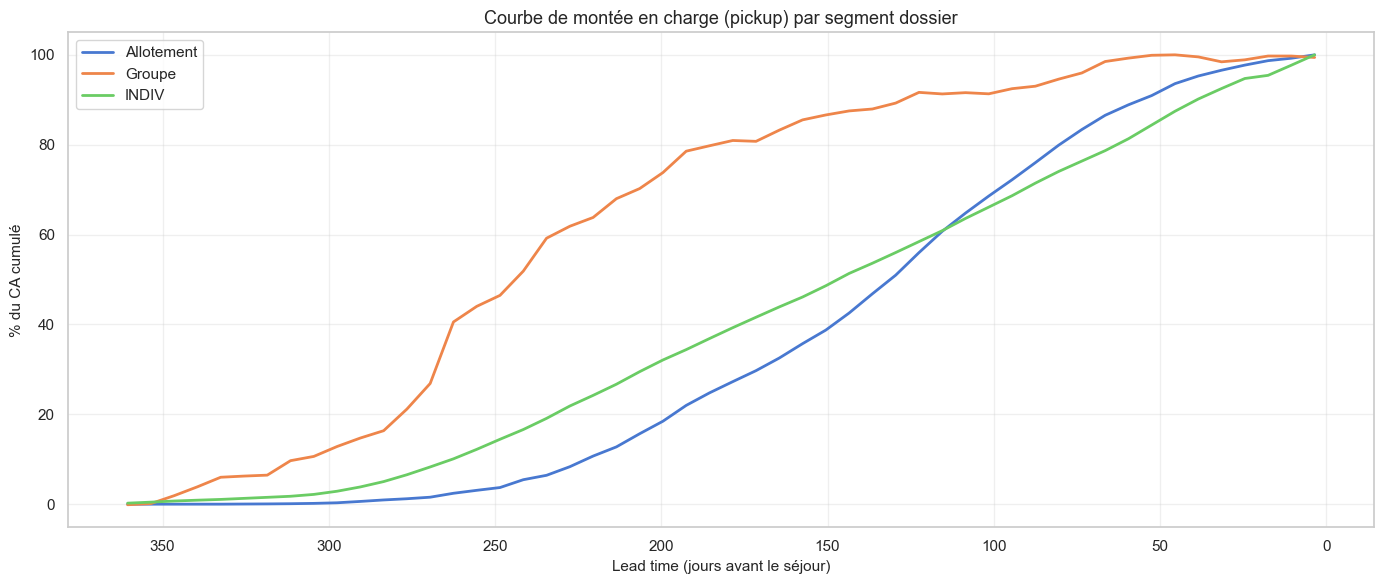

In [62]:
# Même analyse par SEGMENT_DOSSIER
fig, ax = plt.subplots(figsize=(14, 6))
for seg in data_pickup['SEGMENT_DOSSIER'].cat.categories:
    subset = data_pickup[data_pickup['SEGMENT_DOSSIER'] == seg]
    pickup_seg = subset.groupby('LT_BIN', observed=True)['CA_N'].sum().reset_index()
    pickup_seg['LT_MID'] = pickup_seg['LT_BIN'].apply(lambda x: x.mid)
    pickup_seg = pickup_seg.sort_values('LT_MID', ascending=False)
    pickup_seg['CA_CUMUL'] = pickup_seg['CA_N'].cumsum()
    pickup_seg['CA_CUMUL_PCT'] = pickup_seg['CA_CUMUL'] / pickup_seg['CA_CUMUL'].max() * 100
    ax.plot(pickup_seg['LT_MID'], pickup_seg['CA_CUMUL_PCT'], label=seg, linewidth=2)

ax.set_xlabel('Lead time (jours avant le séjour)', fontsize=11)
ax.set_ylabel('% du CA cumulé', fontsize=11)
ax.set_title('Courbe de montée en charge (pickup) par segment dossier', fontsize=13)
ax.legend(fontsize=11)
ax.invert_xaxis()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 5.8 Vue globale des volumes — N vs N-1/N-2/N-3 (à date & FDS)

> *Source : exploration v1.* Comparaison synthétique des volumes hebdomadaires de la saison N (en cours) avec les saisons précédentes (N-1, N-2, N-3) en valeurs **à date** et en **fin de saison**.


In [63]:

# ──────────────────────────────────────────────────────────────────────────────
# TABLEAU RÉCAPITULATIF — VOLUMES N vs N-1/N-2/N-3 (à date & FDS) par saison
# ──────────────────────────────────────────────────────────────────────────────

vol_cols = {
    'N (actuel)'  : 'VOLUME_N',
    'N-1 à date'  : 'VOLUME_N1DATE',
    'N-1 FDS'     : 'VOLUME_N1FDS',
    'N-2 à date'  : 'VOLUME_N2DATE',
    'N-2 FDS'     : 'VOLUME_N2FDS',
    'N-3 à date'  : 'VOLUME_N3DATE',
    'N-3 FDS'     : 'VOLUME_N3FDS',
}

# -- Totaux globaux
rows_global = []
for label, col in vol_cols.items():
    total = data[col].sum()
    rows_global.append({'Période': label, 'Volume total': total})

df_global = pd.DataFrame(rows_global).set_index('Période')
df_global['Évol. vs N-1 FDS (%)'] = (
    (df_global['Volume total'] / df_global.loc['N-1 FDS', 'Volume total'] - 1) * 100
).round(1)
df_global['Évol. vs N-2 FDS (%)'] = (
    (df_global['Volume total'] / df_global.loc['N-2 FDS', 'Volume total'] - 1) * 100
).round(1)
df_global['Évol. vs N-3 FDS (%)'] = (
    (df_global['Volume total'] / df_global.loc['N-3 FDS', 'Volume total'] - 1) * 100
).round(1)

# -- Détail par saison
rows_saison = []
for saison in ['Ete', 'Hiver']:
    mask = data['SAISON_SEJOUR'] == saison
    for label, col in vol_cols.items():
        rows_saison.append({
            'Saison' : saison,
            'Période': label,
            'Volume' : data.loc[mask, col].sum()
        })

df_saison = (
    pd.DataFrame(rows_saison)
    .pivot(index='Période', columns='Saison', values='Volume')
    .reindex(list(vol_cols.keys()))
)
df_saison.columns.name = None

# -- Assemblage final
df_recap = df_global.join(df_saison)
df_recap.insert(1, 'Été',   df_recap.pop('Ete'))
df_recap.insert(2, 'Hiver', df_recap.pop('Hiver'))

# Formatage
def fmt_vol(v):
    return f"{v:,.0f}".replace(",", " ")

def fmt_pct(v):
    if pd.isna(v):
        return "—"
    sign = "+" if v > 0 else ""
    return f"{sign}{v:.1f}%"

styled = df_recap.style \
    .format({
        'Volume total'        : fmt_vol,
        'Été'                 : fmt_vol,
        'Hiver'               : fmt_vol,
        'Évol. vs N-1 FDS (%)': fmt_pct,
        'Évol. vs N-2 FDS (%)': fmt_pct,
        'Évol. vs N-3 FDS (%)': fmt_pct,
    }) \
    .set_caption("Volumes de ventes — vue comparative N / N-1 / N-2 / N-3") \
    .set_table_styles([
        {'selector': 'caption', 'props': [('font-size', '14px'), ('font-weight', 'bold'), ('padding-bottom', '8px')]},
        {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('text-align', 'center')]},
        {'selector': 'td', 'props': [('text-align', 'right'), ('padding', '6px 12px')]},
    ]) \
    .apply(lambda col: [
        'background-color: #d4edda; color: #155724' if isinstance(v, float) and v > 0
        else 'background-color: #f8d7da; color: #721c24' if isinstance(v, float) and v < 0
        else ''
        for v in col
    ], subset=['Évol. vs N-1 FDS (%)', 'Évol. vs N-2 FDS (%)', 'Évol. vs N-3 FDS (%)']) \
    .set_properties(**{'background-color': '#f0f4f8'}, subset=pd.IndexSlice[['N (actuel)'], :]) \
    .highlight_null(color='#eeeeee')

display(styled)
print("\n📌 FDS = Fin De Saison (volume définitif à clôture de saison) | À date = volume observé à la même période")


,Volume total,Été,Hiver,Évol. vs N-1 FDS (%),Évol. vs N-2 FDS (%),Évol. vs N-3 FDS (%)
Période,,,,,,
N (actuel),96 062,29 509,66 553,-44.0%,-39.0%,-37.8%
N-1 à date,92 791,28 894,63 897,-45.9%,-41.1%,-39.9%
N-1 FDS,171 517,102 302,69 216,0.0%,+8.9%,+11.1%
N-2 à date,86 479,25 860,60 619,-49.6%,-45.1%,-44.0%
N-2 FDS,157 473,92 247,65 225,-8.2%,0.0%,+2.0%
N-3 à date,82 253,24 785,57 467,-52.0%,-47.8%,-46.7%
N-3 FDS,154 415,92 175,62 240,-10.0%,-1.9%,0.0%



📌 FDS = Fin De Saison (volume définitif à clôture de saison) | À date = volume observé à la même période


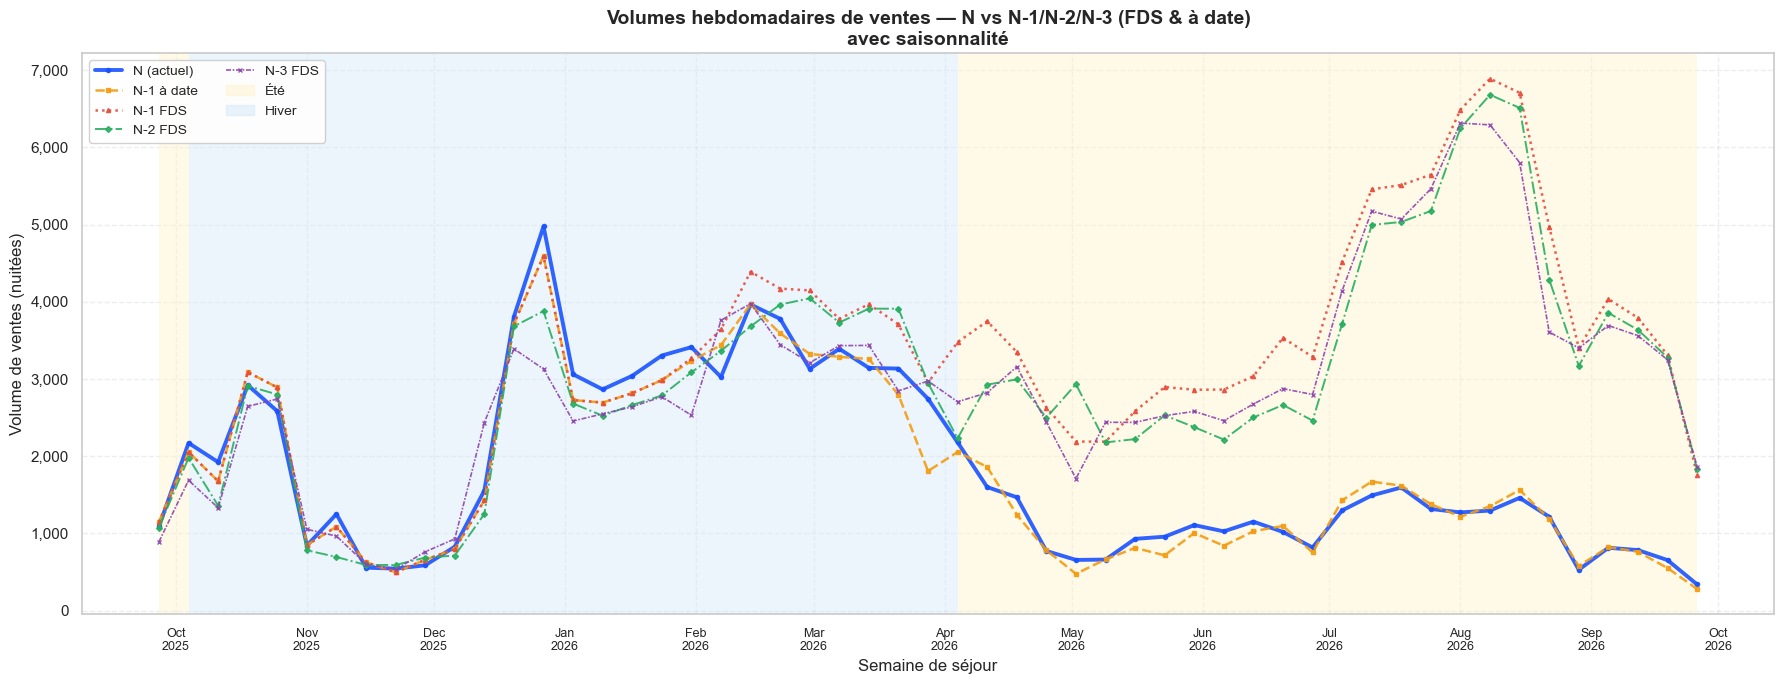

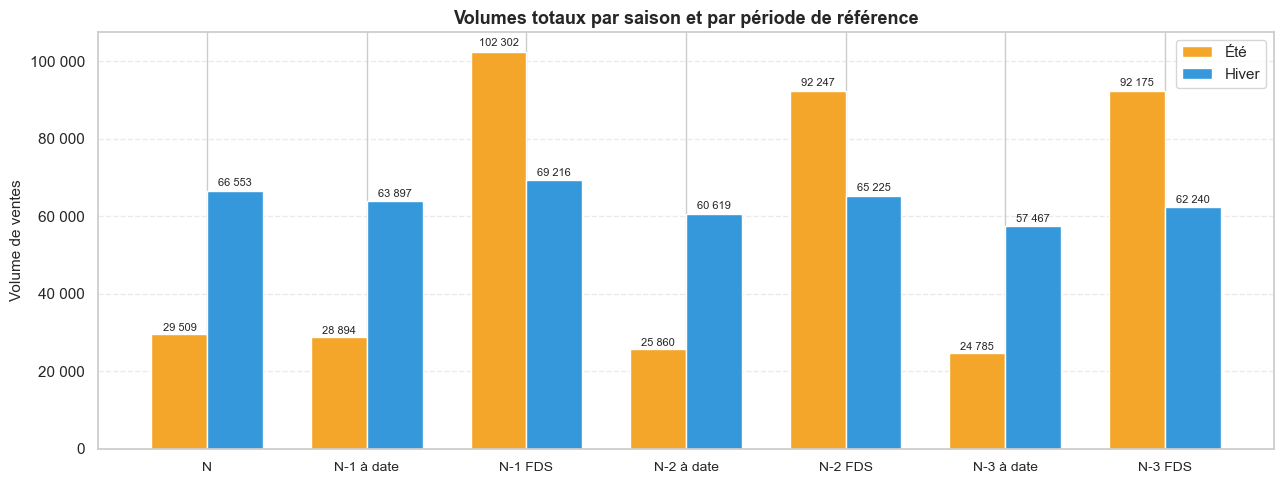

In [66]:

# ──────────────────────────────────────────────────────────────────────────────
# GRAPHIQUE — VOLUMES HEBDOMADAIRES DANS LE TEMPS (N vs N-1 FDS vs N-2 FDS vs N-3 FDS)
#             avec shading saisonnier
# ──────────────────────────────────────────────────────────────────────────────

data['SEMAINE_SEJOUR'] = pd.to_datetime(data['SEMAINE_SEJOUR'])

# Agréger par semaine de séjour
agg = (
    data
    .groupby('SEMAINE_SEJOUR', as_index=False)
    .agg(
        VOL_N      =('VOLUME_N',     'sum'),
        VOL_N1DATE =('VOLUME_N1DATE','sum'),
        VOL_N1FDS  =('VOLUME_N1FDS', 'sum'),
        VOL_N2FDS  =('VOLUME_N2FDS', 'sum'),
        VOL_N3FDS  =('VOLUME_N3FDS', 'sum'),
        SAISON     =('SAISON_SEJOUR', lambda x: x.mode()[0]),  # saison majoritaire de la semaine
    )
    .sort_values('SEMAINE_SEJOUR')
    .reset_index(drop=True)
)

# ── Figure principale ──────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(18, 7))

# Shading saisonnier (alterné Été / Hiver)
prev_saison = None
start_idx   = agg.index[0]
saison_colors = {'Ete': '#FFF3CD', 'Hiver': '#D6EAF8'}

for i, row in agg.iterrows():
    if row['SAISON'] != prev_saison:
        if prev_saison is not None:
            ax.axvspan(agg.loc[start_idx, 'SEMAINE_SEJOUR'],
                       row['SEMAINE_SEJOUR'],
                       color=saison_colors.get(prev_saison, '#eeeeee'),
                       alpha=0.45, lw=0, label=f'_nolegend_{prev_saison}')
        start_idx  = i
        prev_saison = row['SAISON']
# Dernier bloc
ax.axvspan(agg.loc[start_idx, 'SEMAINE_SEJOUR'],
           agg['SEMAINE_SEJOUR'].iloc[-1],
           color=saison_colors.get(prev_saison, '#eeeeee'),
           alpha=0.45, lw=0)

# -- Patches légende saisons
import matplotlib.patches as mpatches
patch_ete   = mpatches.Patch(color=saison_colors['Ete'],   alpha=0.55, label='Été')
patch_hiver = mpatches.Patch(color=saison_colors['Hiver'], alpha=0.55, label='Hiver')

# -- Courbes
line_styles = [
    ('VOL_N',      'N (actuel)',  '#1a53ff', 2.8, '-',  'o'),
    ('VOL_N1DATE', 'N-1 à date', '#f39c12', 1.8, '--', 's'),
    ('VOL_N1FDS',  'N-1 FDS',    '#e74c3c', 1.8, ':',  '^'),
    ('VOL_N2FDS',  'N-2 FDS',    '#27ae60', 1.4, '-.',  'D'),
    ('VOL_N3FDS',  'N-3 FDS',    '#8e44ad', 1.2, (0,(3,1,1,1)), 'x'),
]

for col, label, color, lw, ls, marker in line_styles:
    ax.plot(agg['SEMAINE_SEJOUR'], agg[col],
            label=label, color=color, linewidth=lw,
            linestyle=ls, marker=marker, markersize=3, alpha=0.9)

# -- Axe x : un tick par mois
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
ax.tick_params(axis='x', labelsize=9)

# -- Axe y
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.set_ylabel('Volume de ventes (nuitées)', fontsize=12)
ax.set_xlabel('Semaine de séjour', fontsize=12)
ax.set_title('Volumes hebdomadaires de ventes — N vs N-1/N-2/N-3 (FDS & à date)\navec saisonnalité', fontsize=14, fontweight='bold')

# -- Légende combinée (courbes + saisons)
handles_lines, labels_lines = ax.get_legend_handles_labels()
ax.legend(handles=handles_lines + [patch_ete, patch_hiver],
          labels =labels_lines  + ['Été',     'Hiver'],
          loc='upper left', fontsize=10, framealpha=0.9, ncol=2)

ax.grid(True, linestyle='--', alpha=0.35)
plt.tight_layout()
plt.show()

# ── Figure zoom : Été vs Hiver en barres groupées ─────────────────────────────
df_bar = (
    data
    .groupby('SAISON_SEJOUR', observed=True, as_index=False)
    .agg({col: 'sum' for col in ['VOLUME_N','VOLUME_N1DATE','VOLUME_N1FDS',
                                  'VOLUME_N2DATE','VOLUME_N2FDS',
                                  'VOLUME_N3DATE','VOLUME_N3FDS']})
)
df_bar = df_bar.set_index('SAISON_SEJOUR').rename(index={'Ete':'Été'}).T
df_bar.index = ['N', 'N-1 à date', 'N-1 FDS', 'N-2 à date', 'N-2 FDS', 'N-3 à date', 'N-3 FDS']

fig2, ax2 = plt.subplots(figsize=(13, 5))
x = np.arange(len(df_bar))
w = 0.35
bars_ete   = ax2.bar(x - w/2, df_bar['Été'],   width=w, label='Été',   color='#F4A62A', edgecolor='white')
bars_hiver = ax2.bar(x + w/2, df_bar['Hiver'], width=w, label='Hiver', color='#3498DB', edgecolor='white')

# Étiquettes valeurs
for bar in list(bars_ete) + list(bars_hiver):
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h * 1.01,
             f'{h:,.0f}'.replace(',', ' '), ha='center', va='bottom', fontsize=8)

ax2.set_xticks(x)
ax2.set_xticklabels(df_bar.index, fontsize=10)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'.replace(',', ' ')))
ax2.set_ylabel('Volume de ventes', fontsize=11)
ax2.set_title('Volumes totaux par saison et par période de référence', fontsize=13, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(axis='y', linestyle='--', alpha=0.4)
ax2.set_axisbelow(True)
plt.tight_layout()
plt.show()


### 5.9 Montée en charge & pickup par saison

> *Source : exploration v1.* Vue d'ensemble de la dynamique d'une saison entière (Hiver ou Été) du début à la fin :
> - **Pickup hebdomadaire** : nouveaux CA/Volume réservés par semaine d'observation.
> - **Montée en charge** : courbe cumulative jusqu'à la fin de saison.


In [68]:
# Wrap section dans une fonction pour garder le scope propre et gérer le cas où la saison ciblée est absente
def afficher_montee_en_charge_saison(data, SAISON_TYPE='Hiver', ANNEE_REF=2025, METRIQUE='CA_N'):
    # ══════════════════════════════════════════════════════════════════════════════
    # MONTÉE EN CHARGE & PICKUP — Vue complète d'une saison du début à la fin
    #
    # Définition :
    #   - On choisit une saison cible (ex : Hiver 2024-2025 ou Eté 2024)
    #   - Pour tous les séjours appartenant à cette saison (SEMAINE_SEJOUR dans
    #     la plage de la saison), on trace :
    #       1) le PICKUP hebdomadaire  : nouveaux CA / Volume réservés par semaine
    #          d'observation (DATE_OBSERVATION)
    #       2) la MONTÉE EN CHARGE     : courbe cumulée du CA / Volume réservé
    # ══════════════════════════════════════════════════════════════════════════════

    import matplotlib.patches as mpatches
    import matplotlib.ticker as mticker

    LABEL_METRIQUE = "CA (€)" if METRIQUE == "CA_N" else "Volume (nuitées)"

    # ── Bornes de la saison ────────────────────────────────────────────────────────
    if SAISON_TYPE == 'Hiver':
        debut_saison = pd.Timestamp(f'{ANNEE_REF-1}-10-01')
        fin_saison   = pd.Timestamp(f'{ANNEE_REF}-03-31')
        label_saison = f'Hiver {ANNEE_REF-1}-{str(ANNEE_REF)[2:]}'
    else:
        debut_saison = pd.Timestamp(f'{ANNEE_REF}-04-01')
        fin_saison   = pd.Timestamp(f'{ANNEE_REF}-09-30')
        label_saison = f'Ete {ANNEE_REF}'

    # ── Filtrage : séjours dans la saison cible ───────────────────────────────────
    data['SEMAINE_SEJOUR']   = pd.to_datetime(data['SEMAINE_SEJOUR'])
    data['DATE_OBSERVATION'] = pd.to_datetime(data['DATE_OBSERVATION'])

    mask_saison = (
        (data['SEMAINE_SEJOUR'] >= debut_saison) &
        (data['SEMAINE_SEJOUR'] <= fin_saison)   &
        (data[METRIQUE] != 0)
    )
    df_saison = data.loc[mask_saison].copy()

    if df_saison.empty:
        print(f"⚠️  Aucune donnée pour {label_saison}. Vérifiez SAISON_TYPE/ANNEE_REF.")
        return


    print(f"Saison ciblée  : {label_saison}  ({debut_saison.date()} → {fin_saison.date()})")
    print(f"Nb réservations: {len(df_saison):,}")
    print(f"Plage obs      : {df_saison['DATE_OBSERVATION'].min().date()} → {df_saison['DATE_OBSERVATION'].max().date()}")

    # ── Agrégation par semaine d'observation ──────────────────────────────────────
    pickup_weekly = (
        df_saison
        .groupby(df_saison['DATE_OBSERVATION'].dt.to_period('W'))[METRIQUE]
        .sum()
        .reset_index()
    )
    pickup_weekly.columns = ['SEMAINE_OBS', 'VALEUR']
    pickup_weekly['SEMAINE_OBS'] = pickup_weekly['SEMAINE_OBS'].dt.start_time
    pickup_weekly = pickup_weekly.sort_values('SEMAINE_OBS').reset_index(drop=True)

    # Cumul et %
    pickup_weekly['VALEUR_CUM'] = pickup_weekly['VALEUR'].cumsum()
    pickup_weekly['PCT_CUM']    = pickup_weekly['VALEUR_CUM'] / pickup_weekly['VALEUR_CUM'].iloc[-1] * 100

    # ── Formatters ────────────────────────────────────────────────────────────────
    def fmt_val(x, _):
        if METRIQUE == 'CA_N':
            return f'{x/1_000_000:.2f}M €' if abs(x) >= 1_000_000 else f'{x/1_000:.0f}k €'
        return f'{x:,.0f}'

    fmt_pct = mticker.FuncFormatter(lambda x, _: f'{x:.0f} %')

    # ── FIGURE ────────────────────────────────────────────────────────────────────
    COLOR_BAR  = '#5B9BD5'
    COLOR_CUM  = '#E05C2A'
    COLOR_PCT  = '#27AE60'

    fig, axes = plt.subplots(3, 1, figsize=(16, 14),
                              gridspec_kw={'height_ratios': [2, 2, 1], 'hspace': 0.5})

    # ── Subplot 1 : Pickup hebdomadaire ───────────────────────────────────────────
    ax1 = axes[0]
    ax1.bar(pickup_weekly['SEMAINE_OBS'], pickup_weekly['VALEUR'],
            width=6, color=COLOR_BAR, alpha=0.8, edgecolor='white', linewidth=0.4)

    ma4 = pickup_weekly['VALEUR'].rolling(4, center=True).mean()
    ax1.plot(pickup_weekly['SEMAINE_OBS'], ma4,
             color='navy', linewidth=1.8, linestyle='--', label='Moy. mobile 4 sem.', zorder=3)

    ax1.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_val))
    ax1.set_ylabel(f'Pickup — {LABEL_METRIQUE}', fontsize=11)
    ax1.set_title(f'Pickup hebdomadaire — Saison {label_saison}', fontsize=13, fontweight='bold')
    ax1.legend(fontsize=10)
    ax1.grid(axis='y', linestyle='--', alpha=0.35)
    ax1.xaxis.set_major_locator(mdates.MonthLocator())
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.setp(ax1.xaxis.get_majorticklabels(), rotation=30, ha='right', fontsize=9)

    # ── Subplot 2 : Montée en charge cumulée ─────────────────────────────────────
    ax2 = axes[1]
    ax2.fill_between(pickup_weekly['SEMAINE_OBS'], pickup_weekly['VALEUR_CUM'],
                     alpha=0.18, color=COLOR_CUM)
    ax2.plot(pickup_weekly['SEMAINE_OBS'], pickup_weekly['VALEUR_CUM'],
             color=COLOR_CUM, linewidth=2.2, marker='o', markersize=3.5, label='Cumulé')

    # Jalons 25 / 50 / 75 / 90 %
    for pct_jalon in [25, 50, 75, 90]:
        rows = pickup_weekly[pickup_weekly['PCT_CUM'] >= pct_jalon]
        if len(rows) > 0:
            row = rows.iloc[0]
            ax2.axvline(row['SEMAINE_OBS'], color='gray', linestyle=':', linewidth=1, alpha=0.7)
            ax2.annotate(f'{pct_jalon}%',
                         xy=(row['SEMAINE_OBS'], row['VALEUR_CUM']),
                         xytext=(6, -14), textcoords='offset points',
                         fontsize=8.5, color='gray',
                         arrowprops=dict(arrowstyle='->', color='gray', lw=0.8))

    ax2.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_val))
    ax2.set_ylabel(f'Cumulé — {LABEL_METRIQUE}', fontsize=11)
    ax2.set_title(f'Montée en charge cumulée — {label_saison}', fontsize=13, fontweight='bold')
    ax2.legend(fontsize=10)
    ax2.grid(axis='y', linestyle='--', alpha=0.35)
    ax2.xaxis.set_major_locator(mdates.MonthLocator())
    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.setp(ax2.xaxis.get_majorticklabels(), rotation=30, ha='right', fontsize=9)

    # ── Subplot 3 : Avancement % ─────────────────────────────────────────────────
    ax3 = axes[2]
    ax3.fill_between(pickup_weekly['SEMAINE_OBS'], pickup_weekly['PCT_CUM'],
                     alpha=0.18, color=COLOR_PCT)
    ax3.plot(pickup_weekly['SEMAINE_OBS'], pickup_weekly['PCT_CUM'],
             color=COLOR_PCT, linewidth=2)
    ax3.axhline(50, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
    ax3.axhline(90, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
    ax3.text(pickup_weekly['SEMAINE_OBS'].iloc[-1], 51, '50%', ha='right', fontsize=8, color='gray')
    ax3.text(pickup_weekly['SEMAINE_OBS'].iloc[-1], 91, '90%', ha='right', fontsize=8, color='gray')
    ax3.yaxis.set_major_formatter(fmt_pct)
    ax3.set_ylim(0, 105)
    ax3.set_ylabel('% cumulé', fontsize=10)
    ax3.set_title('Avancement de la montée en charge (%)', fontsize=11, fontweight='bold')
    ax3.grid(axis='y', linestyle='--', alpha=0.35)
    ax3.xaxis.set_major_locator(mdates.MonthLocator())
    ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.setp(ax3.xaxis.get_majorticklabels(), rotation=30, ha='right', fontsize=9)

    plt.suptitle(f'Montée en charge & Pickup — Saison {label_saison}',
                 fontsize=15, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig('../figures/montee_en_charge_pickup_saison.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Figure sauvegardée : figures/montee_en_charge_pickup_saison.png")


# Appel : Hiver 2024-2025
afficher_montee_en_charge_saison(data, SAISON_TYPE="Hiver", ANNEE_REF=2025, METRIQUE="CA_N")


⚠️  Aucune donnée pour Hiver 2024-25. Vérifiez SAISON_TYPE/ANNEE_REF.


---
## 6. Feature Engineering

> **Références** :
> - *Rojas & Jatowt (2025)* : encodages cycliques, lead time, vacances scolaires, variables statiques (hôtel, type de chambre)
> - *Ampountolas & Legg (2025)* : lags temporels, réduction de dimensionnalité, variables OTA/BAR
> - *Bandalouski et al. (2018)* : catégories de demande (saison, durée, lead time, type chambre)

### 6.1 Variables temporelles

In [69]:
import numpy as np
import pandas as pd

def add_temporal_features(df, date_col="SEMAINE_SEJOUR", drop_redundant=False):
    """
    Ajoute des features temporelles basées sur la date de séjour.

    - Utilise ISO year + ISO week (plus cohérent pour Vacances et l'alignement N/N-1).
    - Encodage cyclique robuste (52/53 semaines).
    - Convertit date_col en datetime si nécessaire.

    Params
    ------
    df : pd.DataFrame
    date_col : str
        Colonne date (datetime) représentant la semaine de séjour.
    drop_redundant : bool
        Si True, retire MOIS_SEJOUR / TRIMESTRE_SEJOUR (utile si tu gardes sin/cos uniquement).

    Returns
    -------
    pd.DataFrame
    """
    out = df.copy()

    # 1) S'assurer que c'est bien une date
    out[date_col] = pd.to_datetime(out[date_col], errors="coerce", dayfirst=True)
    dt = out[date_col]

    # 2) ISO calendar (meilleur pour Vacances)
    iso = dt.dt.isocalendar()
    out["ISO_ANNEE_SEJOUR"] = iso.year.astype("Int64")
    out["ISO_SEMAINE_NUM"] = iso.week.astype("Int64")

    # 3) Calendrier standard (optionnel mais parfois utile)
    out["MOIS_SEJOUR"] = dt.dt.month.astype("Int64")
    out["TRIMESTRE_SEJOUR"] = dt.dt.quarter.astype("Int64")

    # 4) Encodages cycliques (mois)
    # (si tu utilises déjà ISO semaine, mois est optionnel)
    out["MOIS_SIN"] = np.sin(2 * np.pi * out["MOIS_SEJOUR"].astype(float) / 12.0)
    out["MOIS_COS"] = np.cos(2 * np.pi * out["MOIS_SEJOUR"].astype(float) / 12.0)

    # 5) Encodages cycliques (semaine ISO)
    # Robustesse: certaines années ont 53 semaines ISO
    # On encode sur 52.1775 (approx) ou sur 53 si tu veux discret.
    # Ici, on encode sur 52 (standard) MAIS on "wrap" la semaine 53 vers 52.
    week = out["ISO_SEMAINE_NUM"].astype("Int64")
    week_wrapped = week.where(week <= 52, 52).astype(float)

    out["SEMAINE_SIN"] = np.sin(2 * np.pi * week_wrapped / 52.0)
    out["SEMAINE_COS"] = np.cos(2 * np.pi * week_wrapped / 52.0)

    # 6) Option : supprimer redondances
    if drop_redundant:
        out = out.drop(columns=["MOIS_SEJOUR", "TRIMESTRE_SEJOUR"], errors="ignore")

    return out

In [70]:
df_agg = add_temporal_features(df_agg, date_col="SEMAINE_SEJOUR", drop_redundant=False)
df_agg[[
    "SEMAINE_SEJOUR", "ISO_ANNEE_SEJOUR", "ISO_SEMAINE_NUM",
    "MOIS_SEJOUR", "SEMAINE_SIN", "SEMAINE_COS", "MOIS_SIN", "MOIS_COS"
]].head()

,SEMAINE_SEJOUR,ISO_ANNEE_SEJOUR,ISO_SEMAINE_NUM,MOIS_SEJOUR,SEMAINE_SIN,SEMAINE_COS,MOIS_SIN,MOIS_COS
0,2025-09-27,2025,39,9,-1.00,-0.00,-1.00,-0.00
1,2025-10-04,2025,40,10,-0.99,0.12,-0.87,0.50
2,2025-10-11,2025,41,10,-0.97,0.24,-0.87,0.50
3,2025-10-18,2025,42,10,-0.94,0.35,-0.87,0.50
4,2025-10-25,2025,43,10,-0.89,0.46,-0.87,0.50


### 6.2 Vacances scolaires & Jours fériés

> **Référence — Rojas & Jatowt (2025)** : *"Holidays are pivotal in predicting hotel demand due to their significant impact on travel patterns."* Les vacances scolaires sont identifiées comme des pics de demande récurrents et doivent être encodées comme features binaires.

> **Transcript métier** : *"est-ce que la semaine est incluse dans une vacance scolaire ? ça peut être intéressant"*

In [71]:
cols_stock = ['STOCK_N', 'STOCK_N1FDS', 'STOCK_N1DATE','STOCK_N2FDS', 'STOCK_N3FDS']

stock = (
    data_stocks
    .groupby('ID_ETABLISSEMENT', as_index=False)[cols_stock]
    .max()
)  

In [72]:
# Vacances scolaires françaises (zones A, B, C) — exercice 2025-2026
# Source : education.gouv.fr
# ⚠️ À compléter / mettre à jour si nécessaire

vacances_2026 = [
    # (debut, fin, label)
    ('2025-10-18', '2025-11-03', 'Toussaint'),
    ('2025-12-20', '2026-01-05', 'Noel'),
    ('2026-02-07', '2026-02-23', 'Hiver_ZA'),
    ('2026-02-14', '2026-03-02', 'Hiver_ZB'),
    ('2026-02-21', '2026-03-09', 'Hiver_ZC'),
    ('2026-04-04', '2026-04-20', 'Printemps_ZA'),
    ('2026-04-11', '2026-04-27', 'Printemps_ZB'),
    ('2026-04-18', '2026-05-04', 'Printemps_ZC'),
    ('2026-07-04', '2026-08-31', 'Grandes_Vacances'),
]

def is_vacances(date, vacances_list):
    """Retourne 1 si la date est dans une période de vacances scolaires."""
    for debut, fin, _ in vacances_list:
        if pd.Timestamp(debut) <= date <= pd.Timestamp(fin):
            return 1
    return 0

df_agg['VACANCES_SCOLAIRES'] = df_agg['SEMAINE_SEJOUR'].apply(
    lambda x: is_vacances(x, vacances_2026)
)

print(f'Semaines en vacances scolaires : {df_agg["VACANCES_SCOLAIRES"].sum():,}')
print(f'Semaines hors vacances : {(df_agg["VACANCES_SCOLAIRES"]==0).sum():,}')

Semaines en vacances scolaires : 2,092
Semaines hors vacances : 1,896


In [73]:
# Jours fériés français — 2026
jours_feries_2026 = pd.to_datetime([
    '2026-01-01',  # Jour de l'An
    '2026-04-06',  # Lundi de Pâques
    '2026-05-01',  # Fête du Travail
    '2026-05-08',  # Victoire 1945
    '2026-05-14',  # Ascension
    '2026-05-25',  # Lundi de Pentecôte
    '2026-07-14',  # Fête Nationale
    '2026-08-15',  # Assomption
    '2026-11-01',  # Toussaint
    '2026-11-11',  # Armistice
    '2026-12-25',  # Noël
])

def has_ferie_in_week(semaine_debut, feries):
    """Retourne 1 si la semaine (samedi→samedi) contient un jour férié."""
    fin_semaine = semaine_debut + pd.Timedelta(days=6)
    return int(any((feries >= semaine_debut) & (feries <= fin_semaine)))

df_agg['CONTIENT_FERIE'] = df_agg['SEMAINE_SEJOUR'].apply(
    lambda x: has_ferie_in_week(x, jours_feries_2026)
)

print(f'Semaines avec jour férié : {df_agg["CONTIENT_FERIE"].sum():,}')

Semaines avec jour férié : 640


### 6.3 Variables de Booking Window & Lead Time

In [74]:
# Sur la table brute (data), on enrichit avec lead time & booking window
# puis on agrège pour la table modèle

# Déjà calculé dans section 5.3 :
# data['LEAD_TIME_JOURS']
# data['BOOKING_WINDOW']

# Agrégation du lead time moyen, médian, std par établissement × semaine
# Ref: Rojas & Jatowt (2025) — Table 1 : Lead time (mean, median, std)

lead_time_agg = data.groupby(
    ['ID_ETABLISSEMENT', 'SEMAINE_SEJOUR'],
    observed=True
)['LEAD_TIME_JOURS'].agg(
    LEAD_TIME_MEAN='mean',
    LEAD_TIME_MEDIAN='median',
    LEAD_TIME_STD='std'
).reset_index()

df_agg = df_agg.merge(lead_time_agg, on=['ID_ETABLISSEMENT', 'SEMAINE_SEJOUR'], how='left')

print('Lead time features ajoutées.')
df_agg[['LEAD_TIME_MEAN', 'LEAD_TIME_MEDIAN', 'LEAD_TIME_STD']].describe()

Lead time features ajoutées.


,LEAD_TIME_MEAN,LEAD_TIME_MEDIAN,LEAD_TIME_STD
count,3988.00,3988.00,3927.00
mean,84.99,71.41,63.69
std,37.80,43.52,21.33
min,5.00,5.00,0.00
25%,58.14,40.00,51.60
50%,81.42,61.00,63.76
75%,107.28,96.00,75.50
max,366.67,362.00,176.51


### 6.4 Prix Moyen de Vente (PMV)

> **Justification — Transcript métier** : *"tu prends ton CA tu divises par volume, c'est que en moyenne en gros tu l'as vendu à tel prix."* Le PMV est le proxy du prix unitaire en l'absence du prix affiché paramétré.

In [75]:
# PMV pour N et N-1 FDS
df_agg['PMV_N'] = np.where(
    df_agg['VOLUME_N'] > 0,
    df_agg['CA_N'] / df_agg['VOLUME_N'],
    np.nan
)

df_agg['PMV_N1FDS'] = np.where(
    df_agg['VOLUME_N1FDS'] > 0,
    df_agg['CA_N1FDS'] / df_agg['VOLUME_N1FDS'],
    np.nan
)

# Évolution du PMV (N vs N-1)
df_agg['EVOL_PMV_N_N1'] = (df_agg['PMV_N'] - df_agg['PMV_N1FDS']) / df_agg['PMV_N1FDS'].replace(0, np.nan)

print('PMV features ajoutées.')
df_agg[['PMV_N', 'PMV_N1FDS', 'EVOL_PMV_N_N1']].describe()

PMV features ajoutées.


,PMV_N,PMV_N1FDS,EVOL_PMV_N_N1
count,3609.00,3633.00,3493.00
mean,736.33,699.74,0.05
std,624.92,563.01,0.31
min,0.00,0.00,-1.00
25%,350.94,345.40,-0.08
50%,520.54,513.81,0.02
75%,911.51,860.86,0.13
max,7593.29,5670.27,5.64


### 6.5 Variables de performance relative (N vs historique)

> **Justification — Bandalouski et al. (2018)** : La comparaison iso-période avec les années passées est une pratique standard en RM. Le ratio N/N-1 capture l'évolution tendancielle et sert de signal pour le pricing.

In [76]:
def safe_ratio(num, den):
    return np.where(den > 0, num / den, np.nan)

# Ratios CA
df_agg['RATIO_CA_N_N1'] = safe_ratio(df_agg['CA_N'], df_agg['CA_N1FDS'])
df_agg['RATIO_CA_N1_N2'] = safe_ratio(df_agg['CA_N1FDS'], df_agg['CA_N2FDS'])
df_agg['RATIO_CA_N2_N3'] = safe_ratio(df_agg['CA_N2FDS'], df_agg['CA_N3FDS'])

# Ratios Volume
df_agg['RATIO_VOL_N_N1'] = safe_ratio(df_agg['VOLUME_N'], df_agg['VOLUME_N1FDS'])
df_agg['RATIO_VOL_N1_N2'] = safe_ratio(df_agg['VOLUME_N1FDS'], df_agg['VOLUME_N2FDS'])

print('Features de performance relative ajoutées.')

Features de performance relative ajoutées.


### 6.6 Variables de Lags temporels

> **Référence — Ampountolas & Legg (2025)** : *"Lagged variables within a few days of the forecasted date [...] exhibit significant predictive power."*  
> **Transcript métier** : *"le lac 52, c'est-à-dire la demande d'aujourd'hui elle est prédite à beaucoup par rapport à la demande il y a un an exactement"*

> On construit les lags sur le **Volume N-1 FDS** par semaine de séjour, en traitant chaque établissement séparément.

In [77]:
def add_lag_features(df, target_col='VOLUME_N1FDS', lags=[1, 2, 4, 8, 13, 26, 52]):
    """
    Ajoute des variables de lag (en semaines) sur le volume N-1 FDS.
    
    Ref: Ampountolas & Legg (2025) — lag features comme prédicteurs principaux.
    Ref: Transcript métier — lag 52 semaines (N-1 iso-date) identifié comme lag dominant.
    
    Les lags sont calculés par établissement (tri par SEMAINE_SEJOUR).
    """
    df = df.sort_values(['ID_ETABLISSEMENT', 'SEMAINE_SEJOUR']).copy()

    for lag in lags:
        df[f'LAG_{lag}W_{target_col}'] = df.groupby('ID_ETABLISSEMENT')[target_col].shift(lag)

    return df

df_agg = add_lag_features(df_agg)

lag_cols = [c for c in df_agg.columns if c.startswith('LAG_')]
print(f'Lags ajoutés : {lag_cols}')
df_agg[lag_cols].describe()

Lags ajoutés : ['LAG_1W_VOLUME_N1FDS', 'LAG_2W_VOLUME_N1FDS', 'LAG_4W_VOLUME_N1FDS', 'LAG_8W_VOLUME_N1FDS', 'LAG_13W_VOLUME_N1FDS', 'LAG_26W_VOLUME_N1FDS', 'LAG_52W_VOLUME_N1FDS']


,LAG_1W_VOLUME_N1FDS,LAG_2W_VOLUME_N1FDS,LAG_4W_VOLUME_N1FDS,LAG_8W_VOLUME_N1FDS,LAG_13W_VOLUME_N1FDS,LAG_26W_VOLUME_N1FDS,LAG_52W_VOLUME_N1FDS
count,3884.00,3780.00,3572.00,3157.00,2642.00,1314.00,28.00
mean,43.46,43.29,42.56,40.85,39.30,33.59,26.58
std,38.00,38.01,37.79,37.08,35.67,33.22,16.46
min,-1.00,-1.00,-1.00,-0.00,-0.00,-0.00,5.57
25%,14.57,14.39,13.86,12.71,12.29,6.43,16.39
50%,36.21,35.79,34.79,32.86,31.71,26.71,20.79
75%,61.14,61.00,60.29,57.71,56.00,50.14,35.14
max,205.29,205.29,205.29,203.86,200.14,192.00,75.71


### 6.7 Moyennes mobiles

> **Justification** : Les moyennes mobiles lissent les fluctuations hebdomadaires et capturent la tendance de fond de la demande sur les semaines précédentes.

In [78]:
def add_rolling_features(df, target_col='VOLUME_N1FDS', windows=[4, 8, 13]):
    """
    Ajoute des moyennes mobiles (rolling mean) par établissement.
    Calculées sur l'historique uniquement (shift(1) pour éviter le data leakage).
    """
    df = df.sort_values(['ID_ETABLISSEMENT', 'SEMAINE_SEJOUR']).copy()

    for w in windows:
        df[f'ROLL_{w}W_MEAN_{target_col}'] = (
            df.groupby('ID_ETABLISSEMENT')[target_col]
            .transform(lambda x: x.shift(1).rolling(w, min_periods=1).mean())
        )

    return df

df_agg = add_rolling_features(df_agg)

roll_cols = [c for c in df_agg.columns if c.startswith('ROLL_')]
print(f'Moyennes mobiles ajoutées : {roll_cols}')

Moyennes mobiles ajoutées : ['ROLL_4W_MEAN_VOLUME_N1FDS', 'ROLL_8W_MEAN_VOLUME_N1FDS', 'ROLL_13W_MEAN_VOLUME_N1FDS']


### 6.8 Encodage des variables catégorielles

> **Justification — Bandalouski et al. (2018)** : La désagrégation par catégories (type, durée, saison) est recommandée pour augmenter la précision des prévisions. On encode les variables catégorielles utiles par label encoding ou target encoding selon le modèle cible.

In [79]:
from sklearn.preprocessing import LabelEncoder

# Variables catégorielles à encoder (issues de la table agrégée)
cat_to_encode = ['ETABLISSEMENT_TYPE', 'ETABLISSEMENT_LOCALISATION', 'SAISON']

le = LabelEncoder()
for col in cat_to_encode:
    if col in df_agg.columns:
        df_agg[f'{col}_ENC'] = le.fit_transform(df_agg[col].astype(str))
        print(f'{col} — classes : {list(le.classes_)}')

ETABLISSEMENT_TYPE — classes : ['Campagne', 'Mer', 'Montagne']
ETABLISSEMENT_LOCALISATION — classes : ['Alpes du Sud', 'Alsace Lorraine', 'Aquitaine', 'Ardèche', 'Aveyron', 'Bretagne', 'Centre, Limousin et Auvergne', "Côte d'Azur", 'Dauphiné - Isère', 'Dordogne', 'Haute Savoie', 'Languedoc Roussillon', 'Maurienne', 'Nord Picardie', 'Normandie', 'Pays Basque', 'Pays de la Loire', 'Poitou Charentes', 'Provence et Luberon', 'Pyrénées', 'Tarentaise']


### 6.9 Récapitulatif des features construites

In [80]:
feature_groups = {
    'Identifiants': ['ID_ETABLISSEMENT', 'ETABLISSEMENT_NOM', 'SEMAINE_SEJOUR'],
    'Cibles (modélisation)': ['VOLUME_N', 'CA_N',],
    'Historique FDS': ['CA_N1FDS', 'CA_N2FDS', 'CA_N3FDS', 'VOLUME_N1FDS', 'VOLUME_N2FDS', 'VOLUME_N3FDS'],
    'Stock': ['STOCK_N', 'STOCK_N1FDS'],
    'Temporelles': ['ANNEE_SEJOUR', 'MOIS_SEJOUR', 'SEMAINE_NUM', 'TRIMESTRE_SEJOUR',
                    'MOIS_SIN', 'MOIS_COS', 'SEMAINE_SIN', 'SEMAINE_COS',
                    'SAISON', 'HAUTE_SAISON'],
    'Calendrier': ['VACANCES_SCOLAIRES', 'CONTIENT_FERIE'],
    'Lead Time': ['LEAD_TIME_MEAN', 'LEAD_TIME_MEDIAN', 'LEAD_TIME_STD'],
    'PMV & Perf. relative': ['PMV_N', 'PMV_N1FDS', 'EVOL_PMV_N_N1',
                              'RATIO_CA_N_N1', 'RATIO_CA_N1_N2', 'RATIO_VOL_N_N1'],
    'Lags': lag_cols,
    'Moyennes mobiles': roll_cols,
    'Encodages catégoriels': [f'{c}_ENC' for c in cat_to_encode],
}

print('=== RÉCAPITULATIF DES FEATURES ===')
total = 0
for group, cols in feature_groups.items():
    existing = [c for c in cols if c in df_agg.columns]
    total += len(existing)
    print(f'\n[{group}] — {len(existing)} features')
    for c in existing:
        print(f'  - {c}')

print(f'\n=== TOTAL : {total} features ===')

=== RÉCAPITULATIF DES FEATURES ===

[Identifiants] — 3 features
  - ID_ETABLISSEMENT
  - ETABLISSEMENT_NOM
  - SEMAINE_SEJOUR

[Cibles (modélisation)] — 2 features
  - VOLUME_N
  - CA_N

[Historique FDS] — 6 features
  - CA_N1FDS
  - CA_N2FDS
  - CA_N3FDS
  - VOLUME_N1FDS
  - VOLUME_N2FDS
  - VOLUME_N3FDS

[Stock] — 0 features

[Temporelles] — 6 features
  - MOIS_SEJOUR
  - TRIMESTRE_SEJOUR
  - MOIS_SIN
  - MOIS_COS
  - SEMAINE_SIN
  - SEMAINE_COS

[Calendrier] — 2 features
  - VACANCES_SCOLAIRES
  - CONTIENT_FERIE

[Lead Time] — 3 features
  - LEAD_TIME_MEAN
  - LEAD_TIME_MEDIAN
  - LEAD_TIME_STD

[PMV & Perf. relative] — 6 features
  - PMV_N
  - PMV_N1FDS
  - EVOL_PMV_N_N1
  - RATIO_CA_N_N1
  - RATIO_CA_N1_N2
  - RATIO_VOL_N_N1

[Lags] — 7 features
  - LAG_1W_VOLUME_N1FDS
  - LAG_2W_VOLUME_N1FDS
  - LAG_4W_VOLUME_N1FDS
  - LAG_8W_VOLUME_N1FDS
  - LAG_13W_VOLUME_N1FDS
  - LAG_26W_VOLUME_N1FDS
  - LAG_52W_VOLUME_N1FDS

[Moyennes mobiles] — 3 features
  - ROLL_4W_MEAN_VOLUME_N1FDS
  - R

---
## 7. Export de la table finale

In [81]:
# Export de la table agrégée enrichie
OUTPUT_PATH = 'odalys_features.parquet'
df_agg.to_parquet(OUTPUT_PATH, index=False)

print(f'Table exportée : {OUTPUT_PATH}')
print(f'Shape finale : {df_agg.shape}')
df_agg.head(3)

Table exportée : odalys_features.parquet
Shape finale : (3988, 46)


,ID_ETABLISSEMENT,ETABLISSEMENT_NOM,SEMAINE_SEJOUR,CA_N,CA_N1FDS,CA_N2FDS,CA_N3FDS,VOLUME_N,VOLUME_N1FDS,VOLUME_N2FDS,VOLUME_N3FDS,ETABLISSEMENT_TYPE,ETABLISSEMENT_LOCALISATION,ISO_ANNEE_SEJOUR,ISO_SEMAINE_NUM,MOIS_SEJOUR,TRIMESTRE_SEJOUR,MOIS_SIN,MOIS_COS,SEMAINE_SIN,SEMAINE_COS,VACANCES_SCOLAIRES,CONTIENT_FERIE,LEAD_TIME_MEAN,LEAD_TIME_MEDIAN,LEAD_TIME_STD,PMV_N,PMV_N1FDS,EVOL_PMV_N_N1,RATIO_CA_N_N1,RATIO_CA_N1_N2,RATIO_CA_N2_N3,RATIO_VOL_N_N1,RATIO_VOL_N1_N2,LAG_1W_VOLUME_N1FDS,LAG_2W_VOLUME_N1FDS,LAG_4W_VOLUME_N1FDS,LAG_8W_VOLUME_N1FDS,LAG_13W_VOLUME_N1FDS,LAG_26W_VOLUME_N1FDS,LAG_52W_VOLUME_N1FDS,ROLL_4W_MEAN_VOLUME_N1FDS,ROLL_8W_MEAN_VOLUME_N1FDS,ROLL_13W_MEAN_VOLUME_N1FDS,ETABLISSEMENT_TYPE_ENC,ETABLISSEMENT_LOCALISATION_ENC
0,1,Cap d'Agde - Saint Loup,2025-09-27,9232.99,9862.01,10947.13,11449.59,26.57,44.86,50.43,44.00,Mer,Languedoc Roussillon,2025,39,9,3,-1.00,-0.00,-1.00,-0.00,0,0,95.10,40.00,105.45,347.48,219.85,0.58,0.94,0.90,0.96,0.59,0.89,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,11
1,1,Cap d'Agde - Saint Loup,2025-10-04,14440.65,12857.60,17387.71,18403.19,44.14,73.29,85.29,76.00,Mer,Languedoc Roussillon,2025,40,10,4,-0.87,0.50,-0.99,0.12,0,0,77.56,40.00,94.42,327.13,175.44,0.86,1.12,0.74,0.94,0.60,0.86,44.86,NaN,NaN,NaN,NaN,NaN,NaN,44.86,44.86,44.86,1,11
2,1,Cap d'Agde - Saint Loup,2025-10-11,11332.16,11331.80,9593.98,16658.55,34.14,54.57,53.57,80.43,Mer,Languedoc Roussillon,2025,41,10,4,-0.87,0.50,-0.97,0.24,0,0,69.32,40.00,75.64,331.90,207.65,0.60,1.00,1.18,0.58,0.63,1.02,73.29,44.86,NaN,NaN,NaN,NaN,NaN,59.07,59.07,59.07,1,11


---

## Synthèse

| Étape | Résultat |
|---|---|
| Nettoyage | Exclusion ACHAT, post-séjour, doublons — NaN traités |
| Univarié | Distribution CA, Volume, Stock — modalités catégorielles |
| Bivarié | CA/Volume/PMV × Segment, Type, Canal, Saison, Partenaire |
| Avancé | Pickup, Booking Window, Annulations, Taux d'occupation |
| Features | Temporelles, Calendrier, Lead Time, PMV, Lags, Rolling, Encodages |

**Prochaine étape** : Modélisation (XGBoost baseline → LightGBM → TFT) avec validation croisée temporelle (Walk Forward — Ampountolas & Legg, 2025).

In [82]:
df_agg

,ID_ETABLISSEMENT,ETABLISSEMENT_NOM,SEMAINE_SEJOUR,CA_N,CA_N1FDS,CA_N2FDS,CA_N3FDS,VOLUME_N,VOLUME_N1FDS,VOLUME_N2FDS,VOLUME_N3FDS,ETABLISSEMENT_TYPE,ETABLISSEMENT_LOCALISATION,ISO_ANNEE_SEJOUR,ISO_SEMAINE_NUM,MOIS_SEJOUR,TRIMESTRE_SEJOUR,MOIS_SIN,MOIS_COS,SEMAINE_SIN,SEMAINE_COS,VACANCES_SCOLAIRES,CONTIENT_FERIE,LEAD_TIME_MEAN,LEAD_TIME_MEDIAN,LEAD_TIME_STD,PMV_N,PMV_N1FDS,EVOL_PMV_N_N1,RATIO_CA_N_N1,RATIO_CA_N1_N2,RATIO_CA_N2_N3,RATIO_VOL_N_N1,RATIO_VOL_N1_N2,LAG_1W_VOLUME_N1FDS,LAG_2W_VOLUME_N1FDS,LAG_4W_VOLUME_N1FDS,LAG_8W_VOLUME_N1FDS,LAG_13W_VOLUME_N1FDS,LAG_26W_VOLUME_N1FDS,LAG_52W_VOLUME_N1FDS,ROLL_4W_MEAN_VOLUME_N1FDS,ROLL_8W_MEAN_VOLUME_N1FDS,ROLL_13W_MEAN_VOLUME_N1FDS,ETABLISSEMENT_TYPE_ENC,ETABLISSEMENT_LOCALISATION_ENC
0,1,Cap d'Agde - Saint Loup,2025-09-27,9232.99,9862.01,10947.13,11449.59,26.57,44.86,50.43,44.00,Mer,Languedoc Roussillon,2025,39,9,3,-1.00,-0.00,-1.00,-0.00,0,0,95.10,40.00,105.45,347.48,219.85,0.58,0.94,0.90,0.96,0.59,0.89,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,11
1,1,Cap d'Agde - Saint Loup,2025-10-04,14440.65,12857.60,17387.71,18403.19,44.14,73.29,85.29,76.00,Mer,Languedoc Roussillon,2025,40,10,4,-0.87,0.50,-0.99,0.12,0,0,77.56,40.00,94.42,327.13,175.44,0.86,1.12,0.74,0.94,0.60,0.86,44.86,NaN,NaN,NaN,NaN,NaN,NaN,44.86,44.86,44.86,1,11
2,1,Cap d'Agde - Saint Loup,2025-10-11,11332.16,11331.80,9593.98,16658.55,34.14,54.57,53.57,80.43,Mer,Languedoc Roussillon,2025,41,10,4,-0.87,0.50,-0.97,0.24,0,0,69.32,40.00,75.64,331.90,207.65,0.60,1.00,1.18,0.58,0.63,1.02,73.29,44.86,NaN,NaN,NaN,NaN,NaN,59.07,59.07,59.07,1,11
3,1,Cap d'Agde - Saint Loup,2025-10-18,92296.90,80039.63,144696.91,59470.07,183.00,191.00,266.00,188.00,Mer,Languedoc Roussillon,2025,42,10,4,-0.87,0.50,-0.94,0.35,1,0,92.98,78.50,70.41,504.35,419.06,0.20,1.15,0.55,2.43,0.96,0.72,54.57,73.29,NaN,NaN,NaN,NaN,NaN,57.57,57.57,57.57,1,11
4,1,Cap d'Agde - Saint Loup,2025-10-25,23728.64,24706.20,25405.47,33663.95,63.14,84.29,93.86,119.86,Mer,Languedoc Roussillon,2025,43,10,4,-0.87,0.50,-0.89,0.46,1,0,51.73,33.00,59.17,375.79,293.12,0.28,0.96,0.97,0.75,0.75,0.90,191.00,54.57,44.86,NaN,NaN,NaN,NaN,90.93,90.93,90.93,1,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3983,4279,La Rosière - L'Ecrin Blanc by Odalys,2026-07-25,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,Montagne,Tarentaise,2026,30,7,3,-0.50,-0.87,-0.46,-0.89,1,0,180.00,180.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00,0.00,NaN,NaN,0.00,0.00,0.00,2,20
3984,4279,La Rosière - L'Ecrin Blanc by Odalys,2026-08-01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,Montagne,Tarentaise,2026,31,8,3,-0.87,-0.50,-0.57,-0.82,1,0,187.00,187.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00,0.00,NaN,NaN,0.00,0.00,0.00,2,20
3985,4279,La Rosière - L'Ecrin Blanc by Odalys,2026-08-08,1201.58,0.00,0.00,0.00,0.86,0.00,0.00,0.00,Montagne,Tarentaise,2026,32,8,3,-0.87,-0.50,-0.66,-0.75,1,0,196.33,194.00,4.04,1401.84,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00,0.00,NaN,NaN,0.00,0.00,0.00,2,20
3986,4279,La Rosière - L'Ecrin Blanc by Odalys,2026-08-15,200.26,0.00,0.00,0.00,0.14,0.00,0.00,0.00,Montagne,Tarentaise,2026,33,8,3,-0.87,-0.50,-0.75,-0.66,1,1,208.00,208.00,0.00,1401.84,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.00,0.00,0.00,0.00,NaN,NaN,0.00,0.00,0.00,2,20


In [83]:
data.columns

Index(['CANAL_VENTE', 'SEGMENT_DOSSIER', 'CODE_OFFRE', 'ETABLISSEMENT_NOM',
       'ETABLISSEMENT_TYPE', 'ETABLISSEMENT_LOCALISATION', 'ID_ETABLISSEMENT',
       'DUREE_SEJOUR', 'PARTENAIRE', 'PARTENAIRE_NIV1_NOM', 'PARTENAIRE_SEG1',
       'PARTENAIRE_SEG2', 'PRESTATION_COMM', 'ID_TYPE_CHAMBRE',
       'SEMAINE_SEJOUR', 'DATE_OBSERVATION', 'ETAT_DOSSIER', 'CA_N',
       'CA_N1DATE', 'CA_N1FDS', 'CA_N2DATE', 'CA_N2FDS', 'CA_N3DATE',
       'CA_N3FDS', 'VOLUME_N', 'VOLUME_N1DATE', 'VOLUME_N1FDS',
       'VOLUME_N2DATE', 'VOLUME_N2FDS', 'VOLUME_N3DATE', 'VOLUME_N3FDS',
       'STOCK_N', 'STOCK_N1DATE', 'STOCK_N1FDS', 'STOCK_N2DATE', 'STOCK_N2FDS',
       'STOCK_N3DATE', 'STOCK_N3FDS', 'MOIS_SEJOUR', 'SAISON', 'SAISON_SEJOUR',
       'LEAD_TIME_JOURS', 'BOOKING_WINDOW'],
      dtype='object')